# Experiment 1

In [224]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Imports

In [225]:
import os
import sys
import datetime
from collections import defaultdict
import re
from html import escape
import json
from pathlib import Path
import yaml

from dotenv import load_dotenv
import jinja2
import pandas as pd
import docker
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from playwright.async_api import async_playwright
from scipy.stats import chi2
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.optimize import curve_fit

from scipy import stats
import pyperclip





import common

## Environmental Variables

In [226]:
load_dotenv()
s3_bucket = os.environ.get("S3_BUCKET")
print(f"S3 Bucket: {s3_bucket}")


S3 Bucket: kasbench-test-20260528-377288663341-us-east-1-an


## Constants

In [227]:
RUN = "experiment-1-run-60m-7rep-b"
SAMPLE_TRIAL = "trial0001" # Used to extract common infrastructure details
DATA_DIR = f"../data/{RUN}"
os.makedirs(DATA_DIR, exist_ok=True)
report_date = datetime.datetime.now(datetime.UTC)

RUN_DB = f"{DATA_DIR}/logs.db"
print(f"Run database is {RUN_DB}")

SLO_RT_MS = 100
SLO_FR = 0.0001

# Means from the baseline run (baseline_resource_calculations.ipynb)
SLO_RT_MS = 26.063374 * 2
SLO_FR = 0.000245 * 2

TOLERANCE = 0.20

TOTAL_CPU = 32
TOTAL_MEMORY = 64_000_000_000

TEMPLATE_DIR = "./templates"
FIGURE_DIR = "../figures"

AUTOSCALER_LOOKUP = {"hpa": "Kubernetes Horizontal Pod Autoscaler (HPA)",
    "vpa": "Kubernetes Vertical Pod Autoscaler (VPA)",
    "keda": "Kubernetes Event-Driven Autoscaler (KEDA)",
    "none": "No autoscaler (control condition)"}

TIME_SLICE_SECONDS = 30


MICROSERVICES = ["globeco-allocation-service",
    "globeco-confirmation-service",
    "globeco-execution-service",
    "globeco-fix-engine",
    "globeco-order-generation-service",
    "globeco-order-service",
    "globeco-portfolio-accounting-service",
    "globeco-portfolio-management-portal",
    "globeco-portfolio-service",
    "globeco-pricing-service",
    "globeco-security-service",
    "globeco-trade-service",
    ]

ALPHA = 0.50
BETA = 0.50
K = 5
W_MAX = 1


Run database is ../data/experiment-1-run-60m-7rep-b/logs.db


## Response Time, Failure Rate, and Roundtrip Metrics

### Compile data

In [228]:
# Download the Locust database files and load them into a single database
common.download_and_load_locust_dbs(s3_bucket, RUN, RUN_DB, DATA_DIR)


In [229]:
# Get the log as a dataframe
log_df_filename = f"{DATA_DIR}/log_df.parquet"
if os.path.exists(log_df_filename): 
    log_df = pd.read_parquet(log_df_filename)
else:
    log_df = common.get_log_as_dataframe(RUN_DB)
    log_df.to_parquet(log_df_filename)

In [230]:
# Summarize by trial
trial_summary_df = common.get_trial_summary_df(log_df)

# Merge with roundtrip percentages
merged_trial_summary_df = common.merge_roundtrip_completion_percentage(None, s3_bucket, trial_summary_df, RUN)

# Summary by autoscaler
autoscaler_summary_df = common.get_autoscaler_summary(merged_trial_summary_df)


In [231]:
autoscaler_summary_df.columns

Index(['autoscaler', 'trials', 'mean_rt', 'median_rt', 'sd_rt',
       'mean_failure_rate', 'median_failure_rate', 'sd_failure_rate',
       'mean_p99_response_time', 'median_p99_response_time',
       'sd_p99_response_time', 'mean_roundtrip_completion_percentage',
       'median_roundtrip_completion_percentage',
       'sd_roundtrip_completion_percentage', 'total_quantity_ordered',
       'total_quantity_placed', 'total_quantity_filled', 'ci95_rt',
       'ci95_failure_rate', 'ci95_roundtrip_completion_percentage',
       'pooled_roundtrip_completion_percentage'],
      dtype='str')

### Results table ($\LaTeX$)

In [244]:
df = merged_trial_summary_df.copy()
df["replicas"] = df.autoscaler.str[-1].astype(int)
df = df[['replicas', 'trial_id', 
       'requests', 'failures', 'mean_response_time', 'failure_rate', 
       'roundtrip_completion_percentage']]
df.columns = ['Replicas', 'Trial ID',
       'Requests', 'Failures', 'Mean Response Time (ms)', 'Failure Rate',
       'Roundtrip Completion \%']

format_dict = {
    "Mean Response Time (ms)": "{:.1f}",
    "Failure Rate": "{:.2e}",
    "Roundtrip Completion \%": "{:.1f}",
}



# Apply the formatting and export to LaTeX
latex = df.style.format(format_dict, na_rep='').to_latex(
    caption="Experiment 1 Summary of results by trial.",
    label="tab:experiment-1-summary-of-results-by-trial",
    hrules=True
)

print(latex)
pyperclip.copy(latex)

df

\begin{table}
\caption{Experiment 1 Summary of results by trial.}
\label{tab:experiment-1-summary-of-results-by-trial}
\begin{tabular}{lrlrrrrr}
\toprule
 & Replicas & Trial ID & Requests & Failures & Mean Response Time (ms) & Failure Rate & Roundtrip Completion \% \\
\midrule
0 & 1 & trial0009 & 225592 & 10852 & 1489.0 & 4.81e-02 & 1.0 \\
1 & 1 & trial0010 & 261693 & 8464 & 1010.3 & 3.23e-02 & 1.3 \\
2 & 1 & trial0012 & 253519 & 6596 & 781.1 & 2.60e-02 & 3.3 \\
3 & 1 & trial0015 & 256292 & 4210 & 622.3 & 1.64e-02 & 5.3 \\
4 & 1 & trial0022 & 286390 & 6230 & 848.6 & 2.18e-02 & 1.0 \\
5 & 1 & trial0027 & 161137 & 18705 & 2150.1 & 1.16e-01 & 2.7 \\
6 & 1 & trial0034 & 199881 & 10543 & 1275.2 & 5.27e-02 & 5.2 \\
7 & 2 & trial0011 & 388367 & 54 & 157.3 & 1.39e-04 & 2.2 \\
8 & 2 & trial0021 & 385194 & 45 & 158.0 & 1.17e-04 & 1.7 \\
9 & 2 & trial0026 & 385210 & 54 & 162.8 & 1.40e-04 & 2.2 \\
10 & 2 & trial0028 & 385114 & 72 & 202.4 & 1.87e-04 & 2.4 \\
11 & 2 & trial0031 & 385491 & 30 & 137.7

<>:8: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:13: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:8: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:13: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
/var/folders/sh/1_33sr491y7488wgvd7hldqr0000gn/T/ipykernel_73155/3705985549.py:8: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
  'Roundtrip Completion \%']
/var/folders/sh/1_33sr491y7488wgvd7hldqr0000gn/T/ipykernel_73155/3705985549.py:13: SyntaxWarning: "\%" is an invalid escape sequ

,Replicas,Trial ID,Requests,Failures,Mean Response Time (ms),Failure Rate,Roundtrip Completion \%
0,1,trial0009,225592,10852,1489.004370,0.048105,1.008044
1,1,trial0010,261693,8464,1010.337617,0.032343,1.329637
2,1,trial0012,253519,6596,781.059727,0.026018,3.348221
3,1,trial0015,256292,4210,622.326890,0.016427,5.292650
4,1,trial0022,286390,6230,848.639731,0.021754,1.035681
5,1,trial0027,161137,18705,2150.050726,0.116081,2.681806
6,1,trial0034,199881,10543,1275.227338,0.052746,5.231115
7,2,trial0011,388367,54,157.341301,0.000139,2.181400
8,2,trial0021,385194,45,157.979233,0.000117,1.718331
9,2,trial0026,385210,54,162.820152,0.000140,2.182476


In [238]:
df = autoscaler_summary_df.copy()
df["replicas"] = df["autoscaler"].str[-1].astype(int)
df = df[['replicas', 'trials', 'mean_rt', 
       'mean_failure_rate',  'mean_roundtrip_completion_percentage',
       'median_roundtrip_completion_percentage',
       ]]

latex = df.to_latex(
    caption="Summary statistics for each autoscaler configuration.",
    label="tab:experiment-1-autoscaler-summary",
    float_format="%.2f",
    index=False
)

print(latex)
display(df)


\begin{table}
\caption{Summary statistics for each autoscaler configuration.}
\label{tab:experiment-1-autoscaler-summary}
\begin{tabular}{rrrrrr}
\toprule
replicas & trials & mean_rt & mean_failure_rate & mean_roundtrip_completion_percentage & median_roundtrip_completion_percentage \\
\midrule
1 & 7 & 1168.09 & 0.04 & 2.85 & 2.68 \\
2 & 7 & 158.56 & 0.00 & 2.26 & 2.31 \\
3 & 7 & 89.21 & 0.00 & 3.59 & 3.68 \\
4 & 7 & 80.54 & 0.00 & 4.47 & 4.36 \\
5 & 7 & 81.87 & 0.00 & 5.69 & 5.66 \\
\bottomrule
\end{tabular}
\end{table}



,replicas,trials,mean_rt,mean_failure_rate,mean_roundtrip_completion_percentage,median_roundtrip_completion_percentage
0,1,7,1168.092343,0.044782,2.846736,2.681806
1,2,7,158.560403,0.000120,2.260400,2.308333
2,3,7,89.206835,0.000036,3.592643,3.678735
3,4,7,80.544881,0.000036,4.466954,4.355233
4,5,7,81.872019,0.000036,5.693475,5.657808


### Main Effect Plots


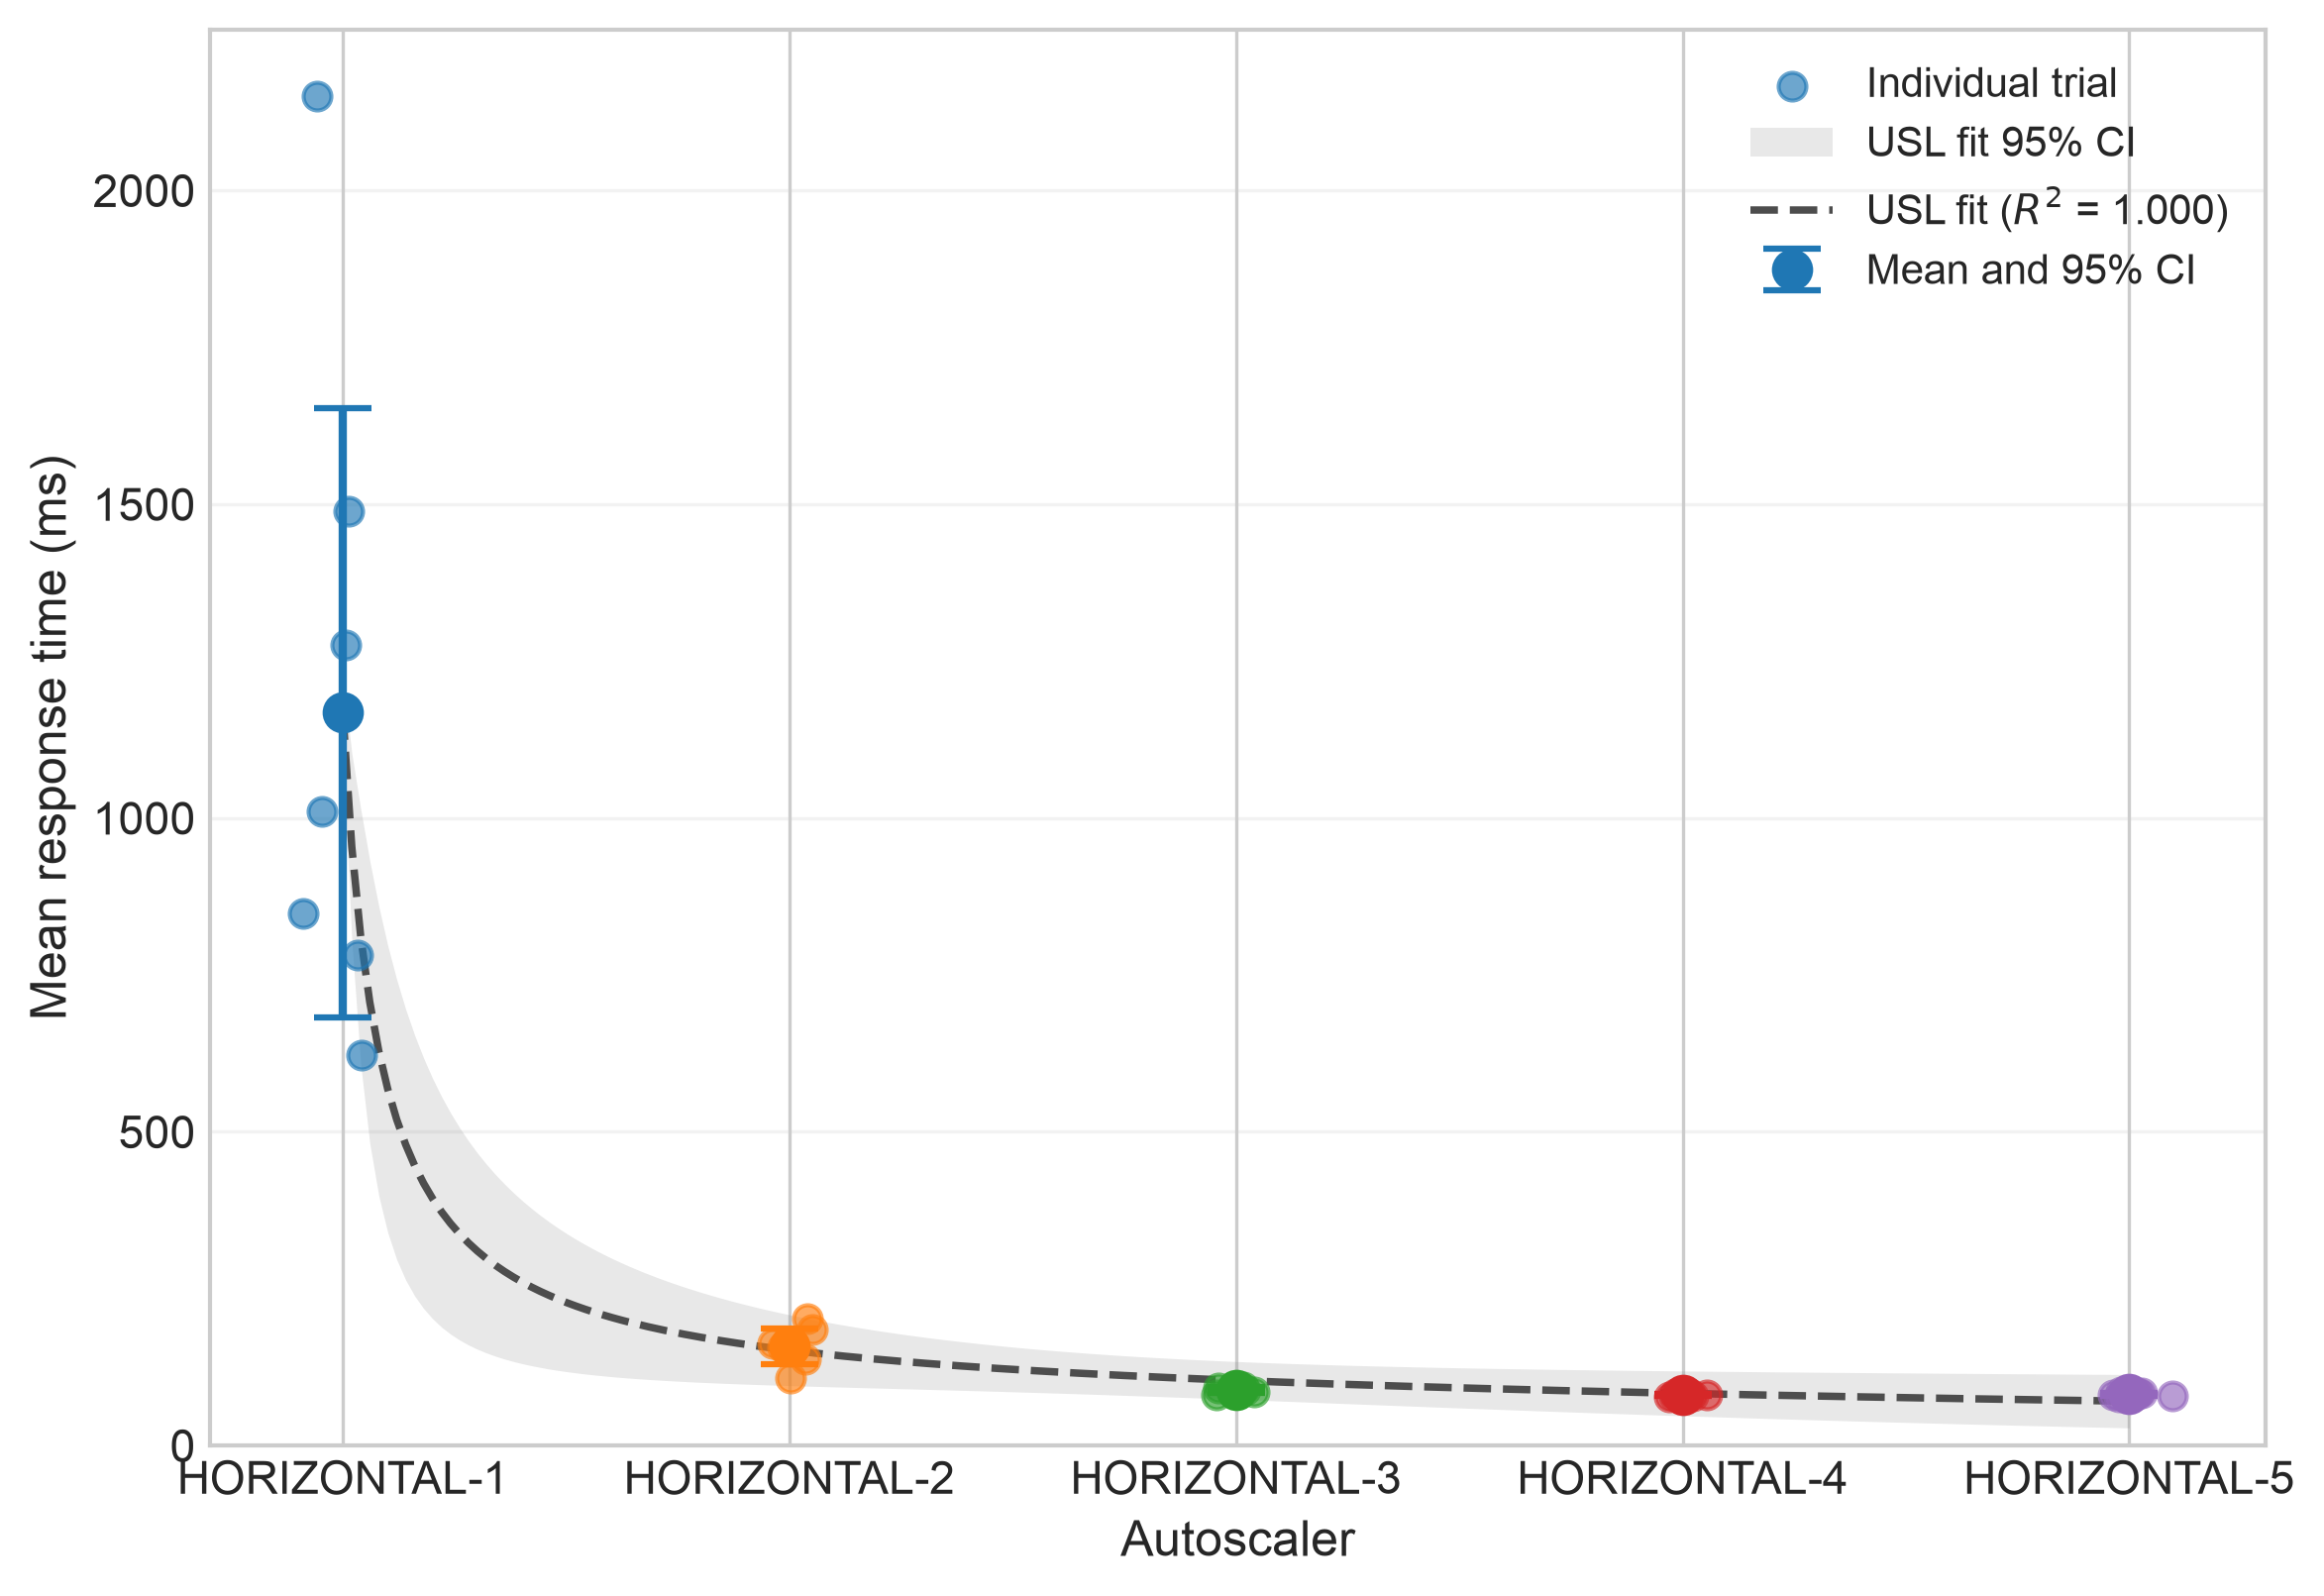

{'alpha': np.float64(10.347629170048368), 'beta': np.float64(2.007237984737146), 'gamma': np.float64(1168.113374947079), 'r_squared': np.float64(0.9995752320561443)}


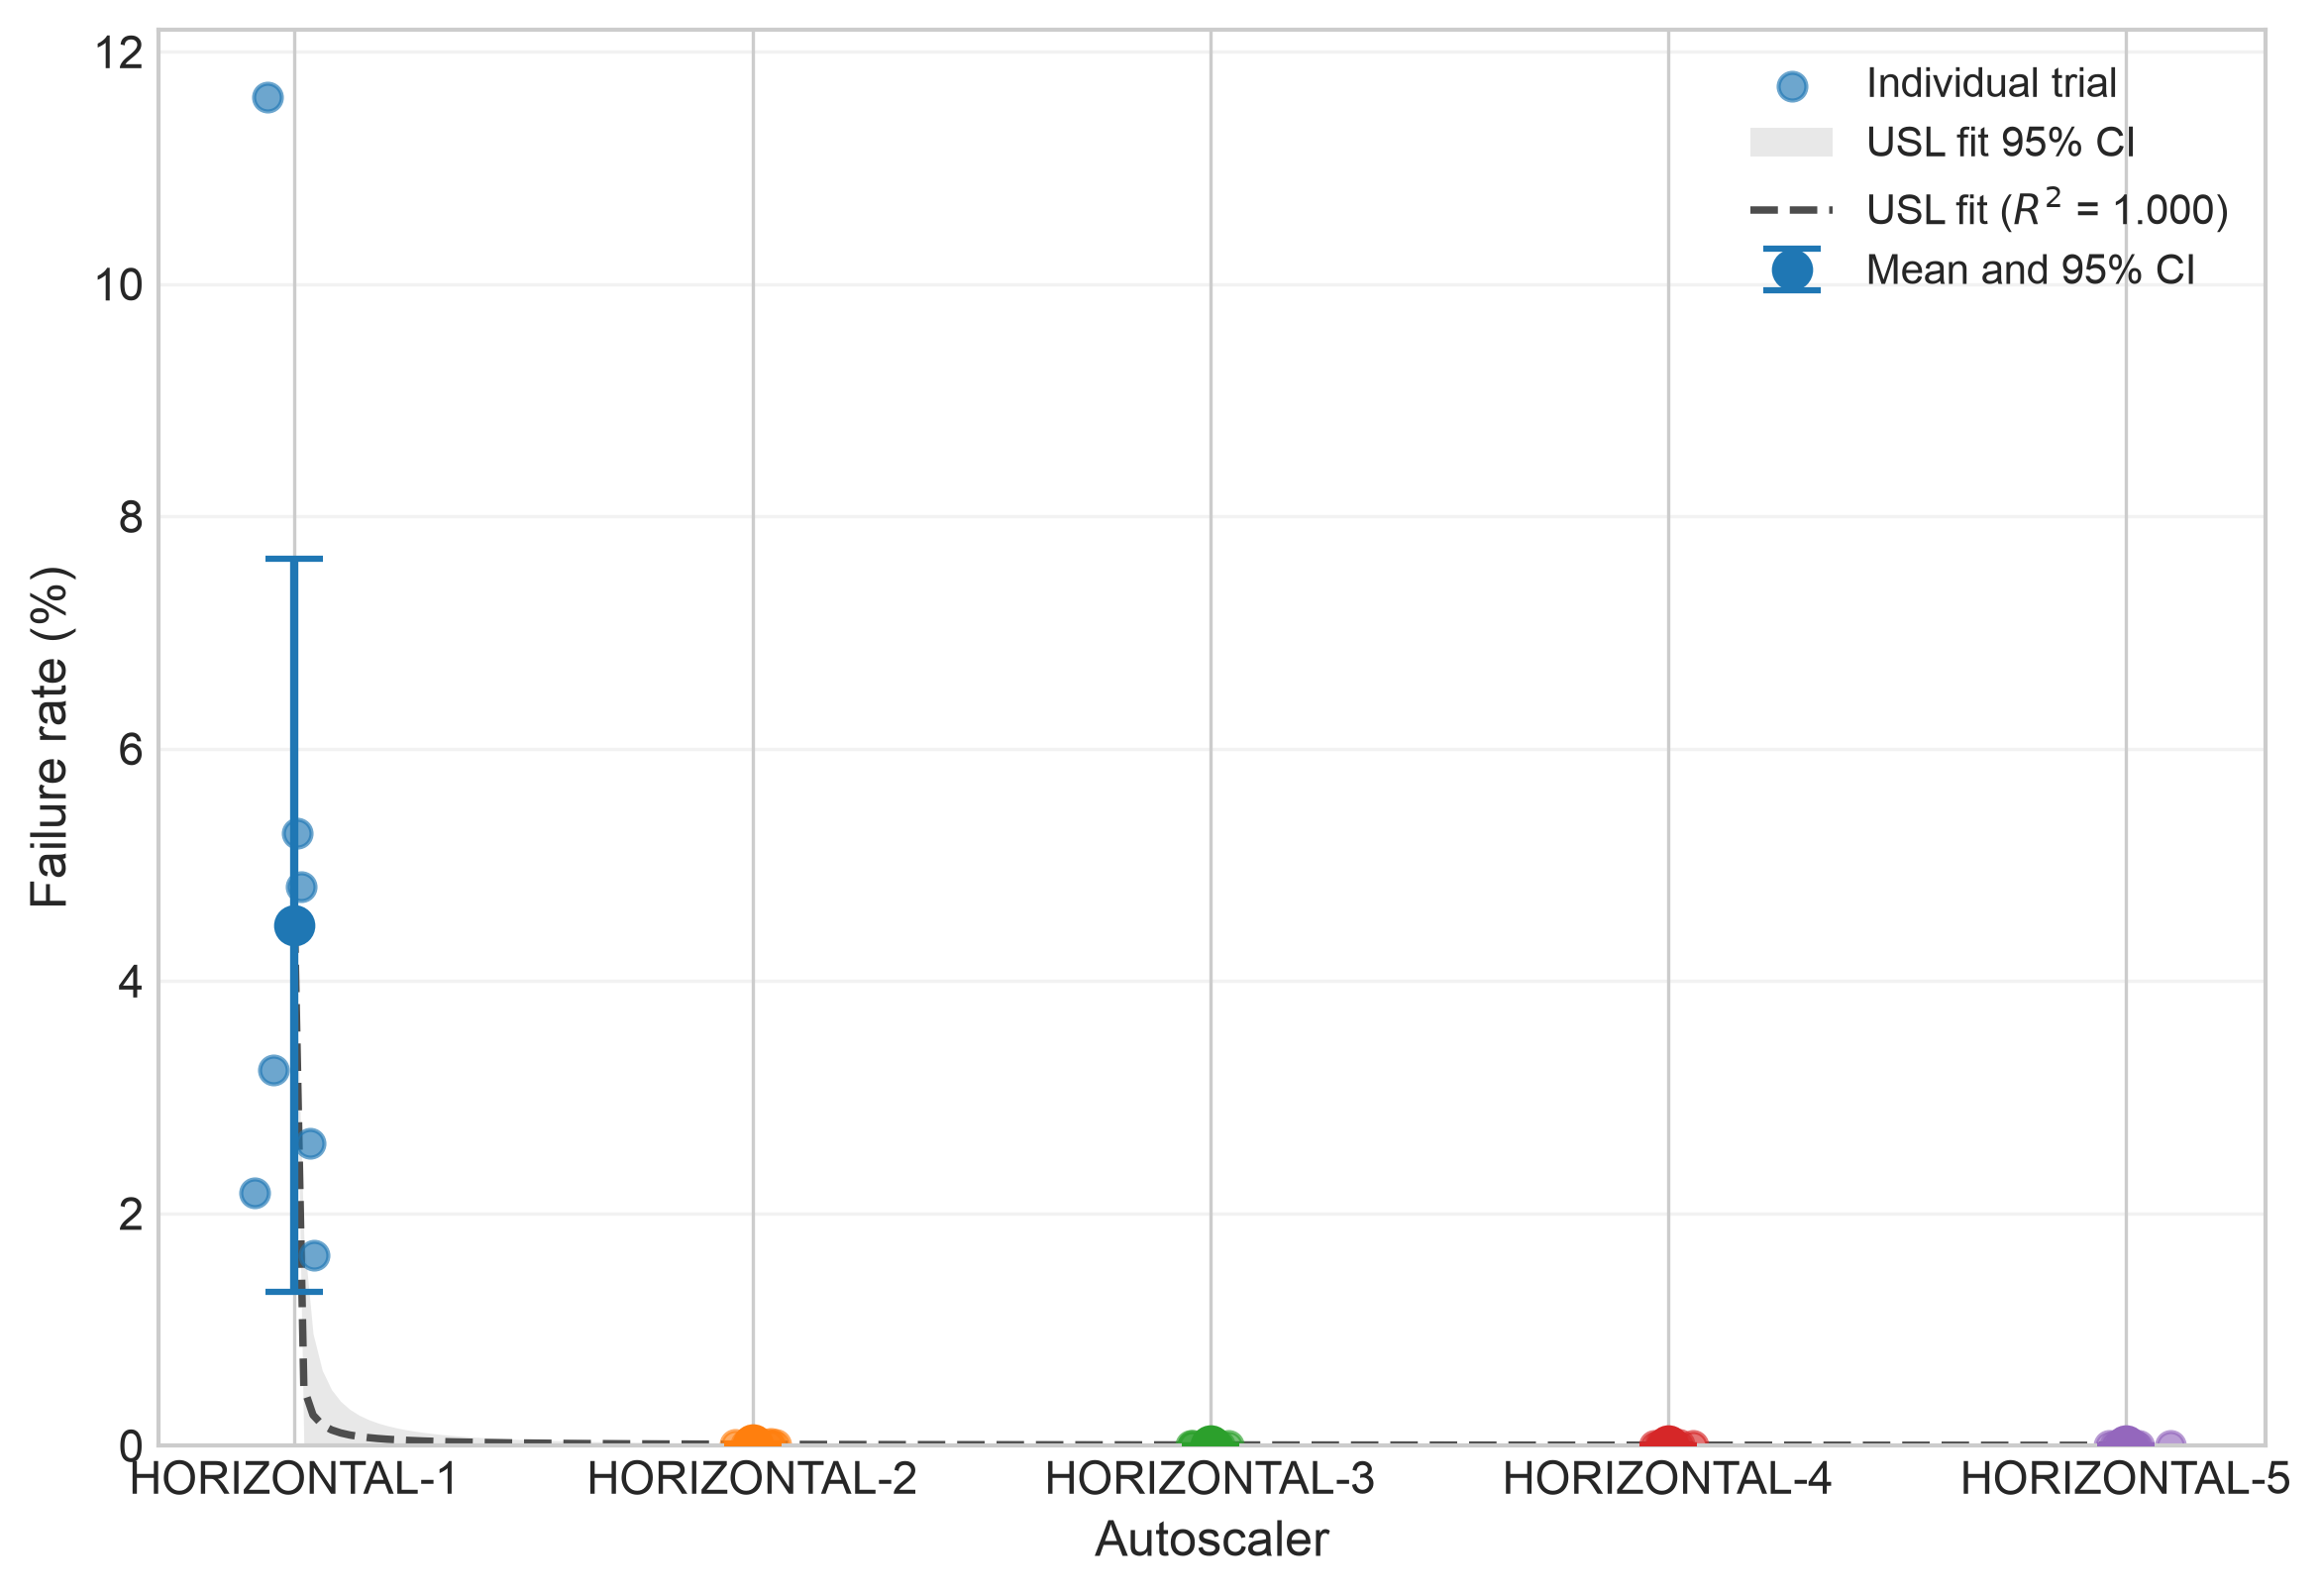

{'alpha': np.float64(0.0019413689833681497), 'beta': np.float64(399.9008471252306), 'gamma': np.float64(4.478191688675288), 'r_squared': np.float64(0.9999996665658997)}


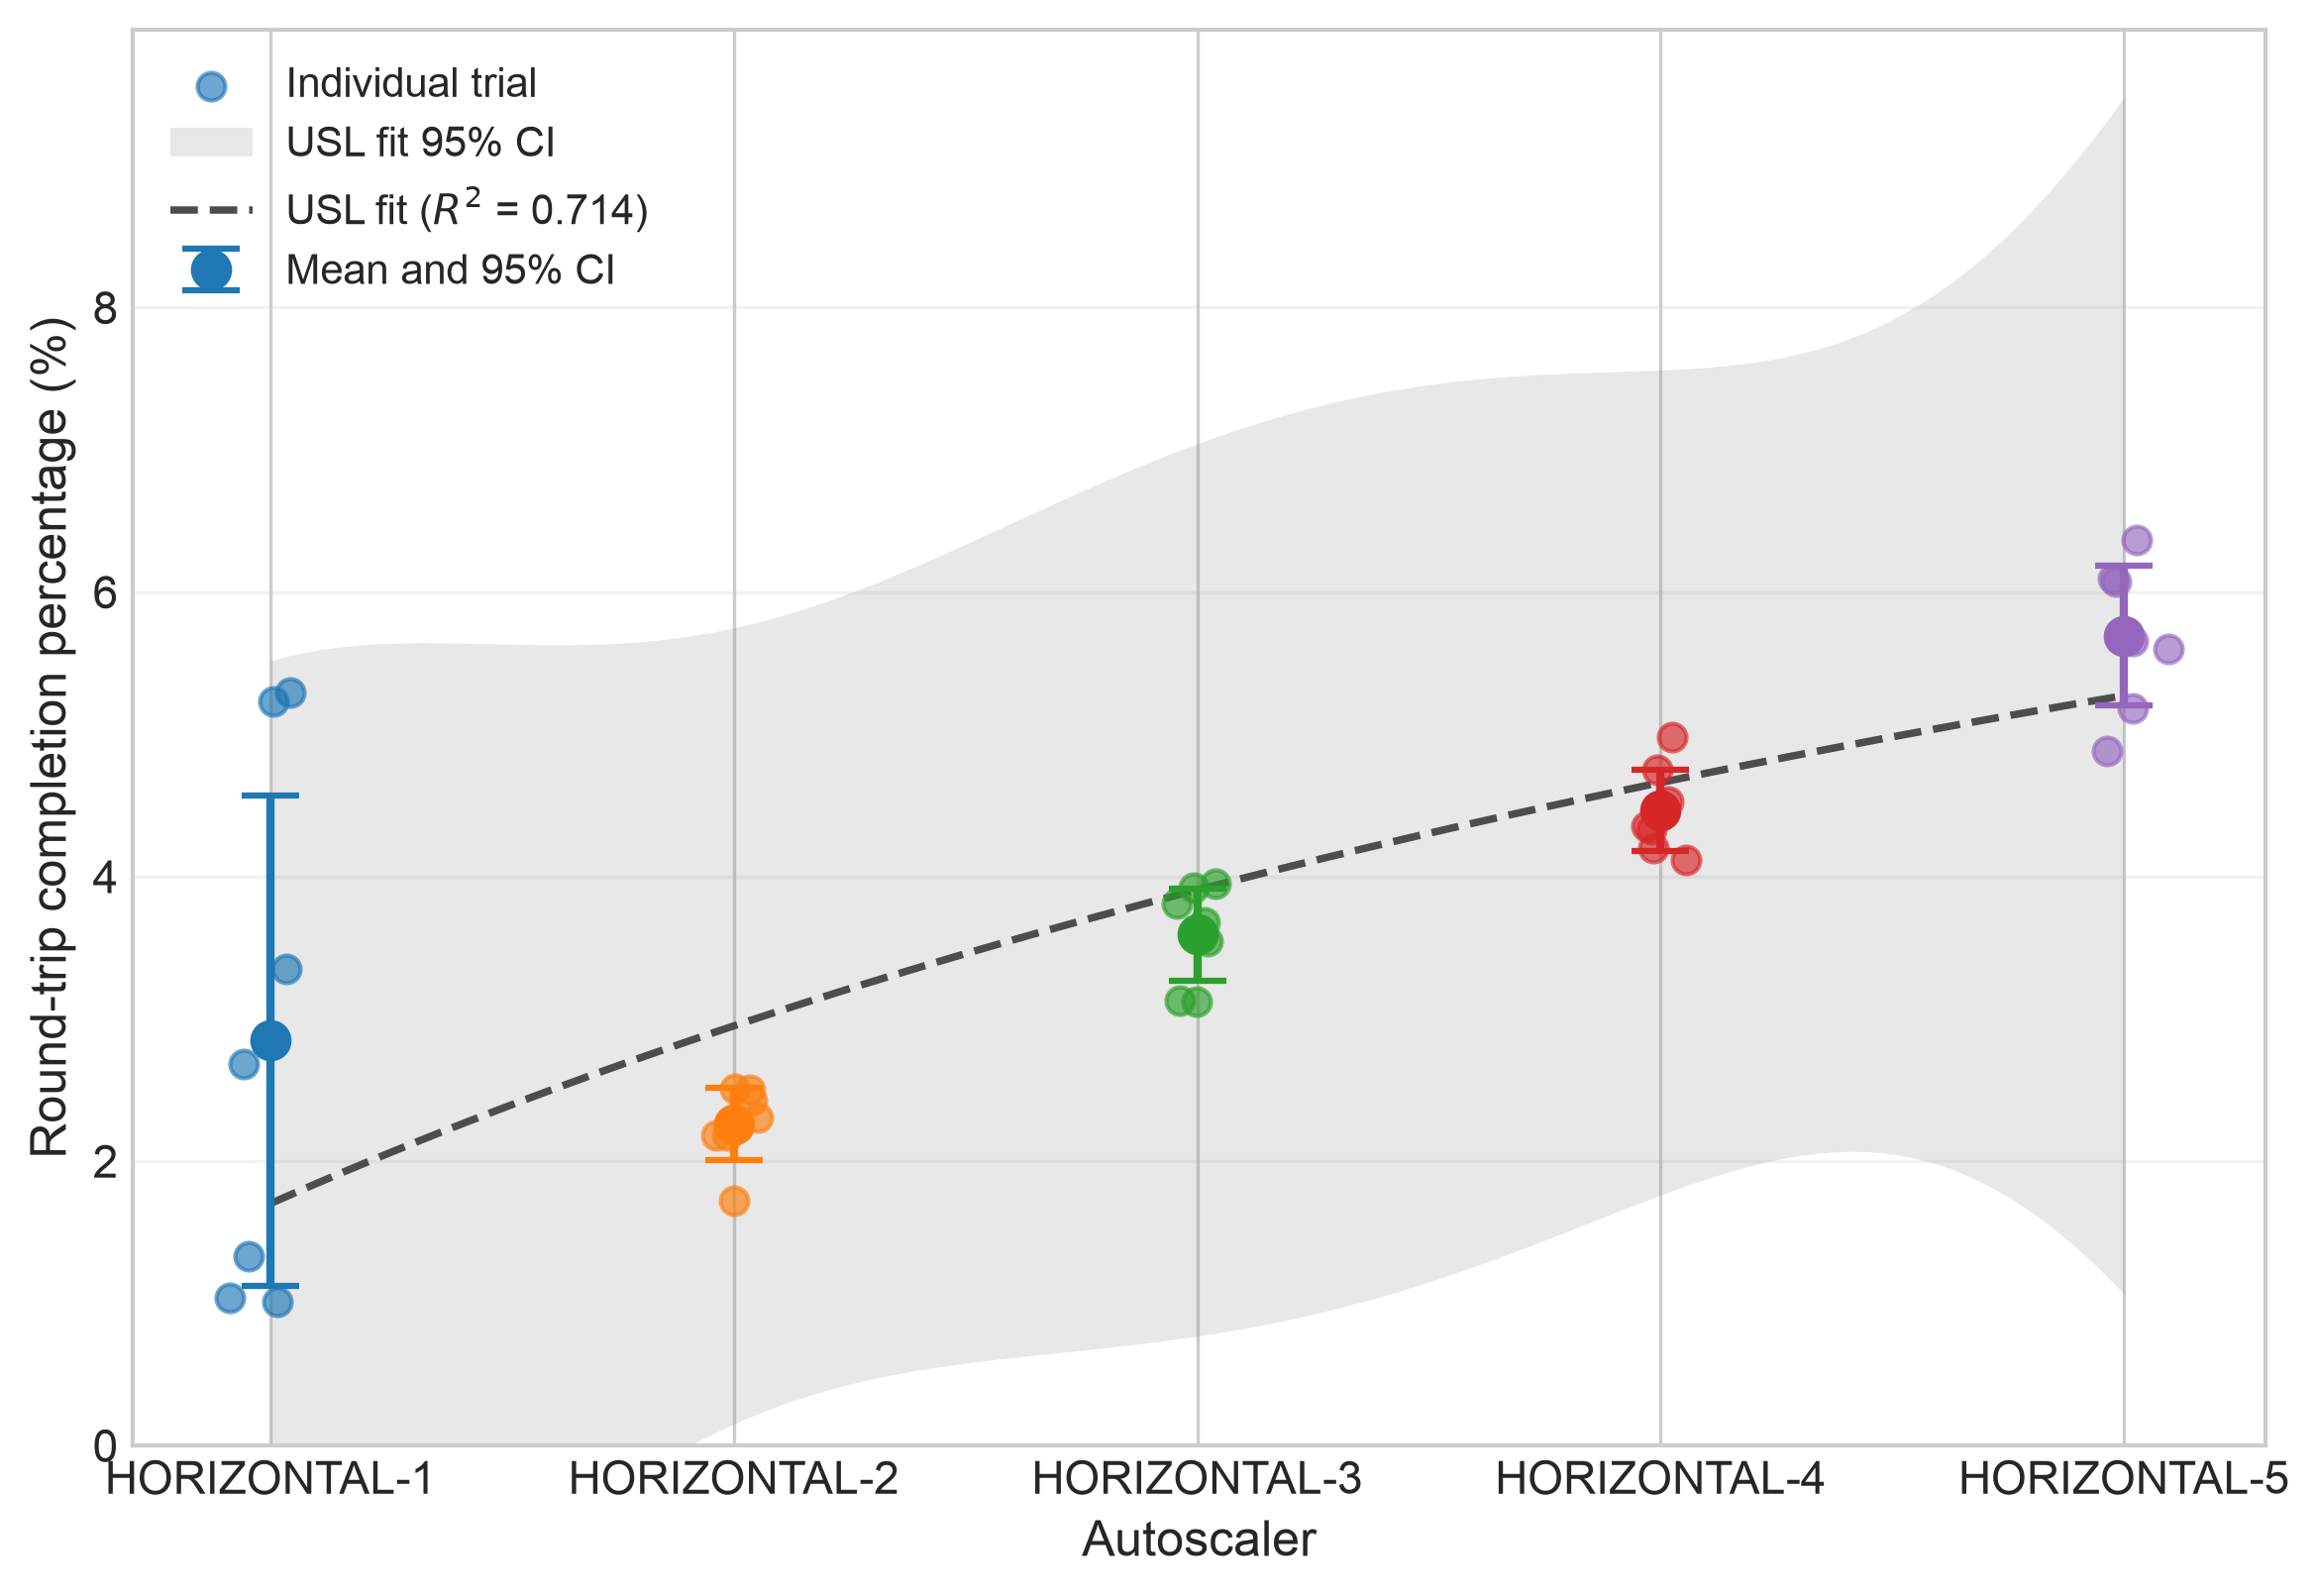

{'alpha': np.float64(0.15347315837763817), 'beta': np.float64(1.1357754143927023e-19), 'gamma': np.float64(1.7018274989545983), 'r_squared': np.float64(0.7140923423473726)}


In [232]:

# Generate mean response time by autoscaler plot
fig, ax, filename, fit_stats = common.plot_mean_response_time_by_autoscaler(trial_summary_df, show=True, 
filename = "../figures/experiment_1_response_time_by_autoscaler.png",)
print(fit_stats)

# Generate failure rate by autoscaler plot
fig, ax, filename, fit_stats = common.plot_failure_rate_by_autoscaler(merged_trial_summary_df, show=True, 
filename = "../figures/experiment_1_failure_rate_by_autoscaler.png",)
print(fit_stats)

fig, ax, filename, fit_stats = common.plot_roundtrip_completion_by_autoscaler(merged_trial_summary_df, show=True, 
filename = "../figures/experiment_1_roundtrip_completion_by_autoscaler.png",)
print(fit_stats)


### Variance plots

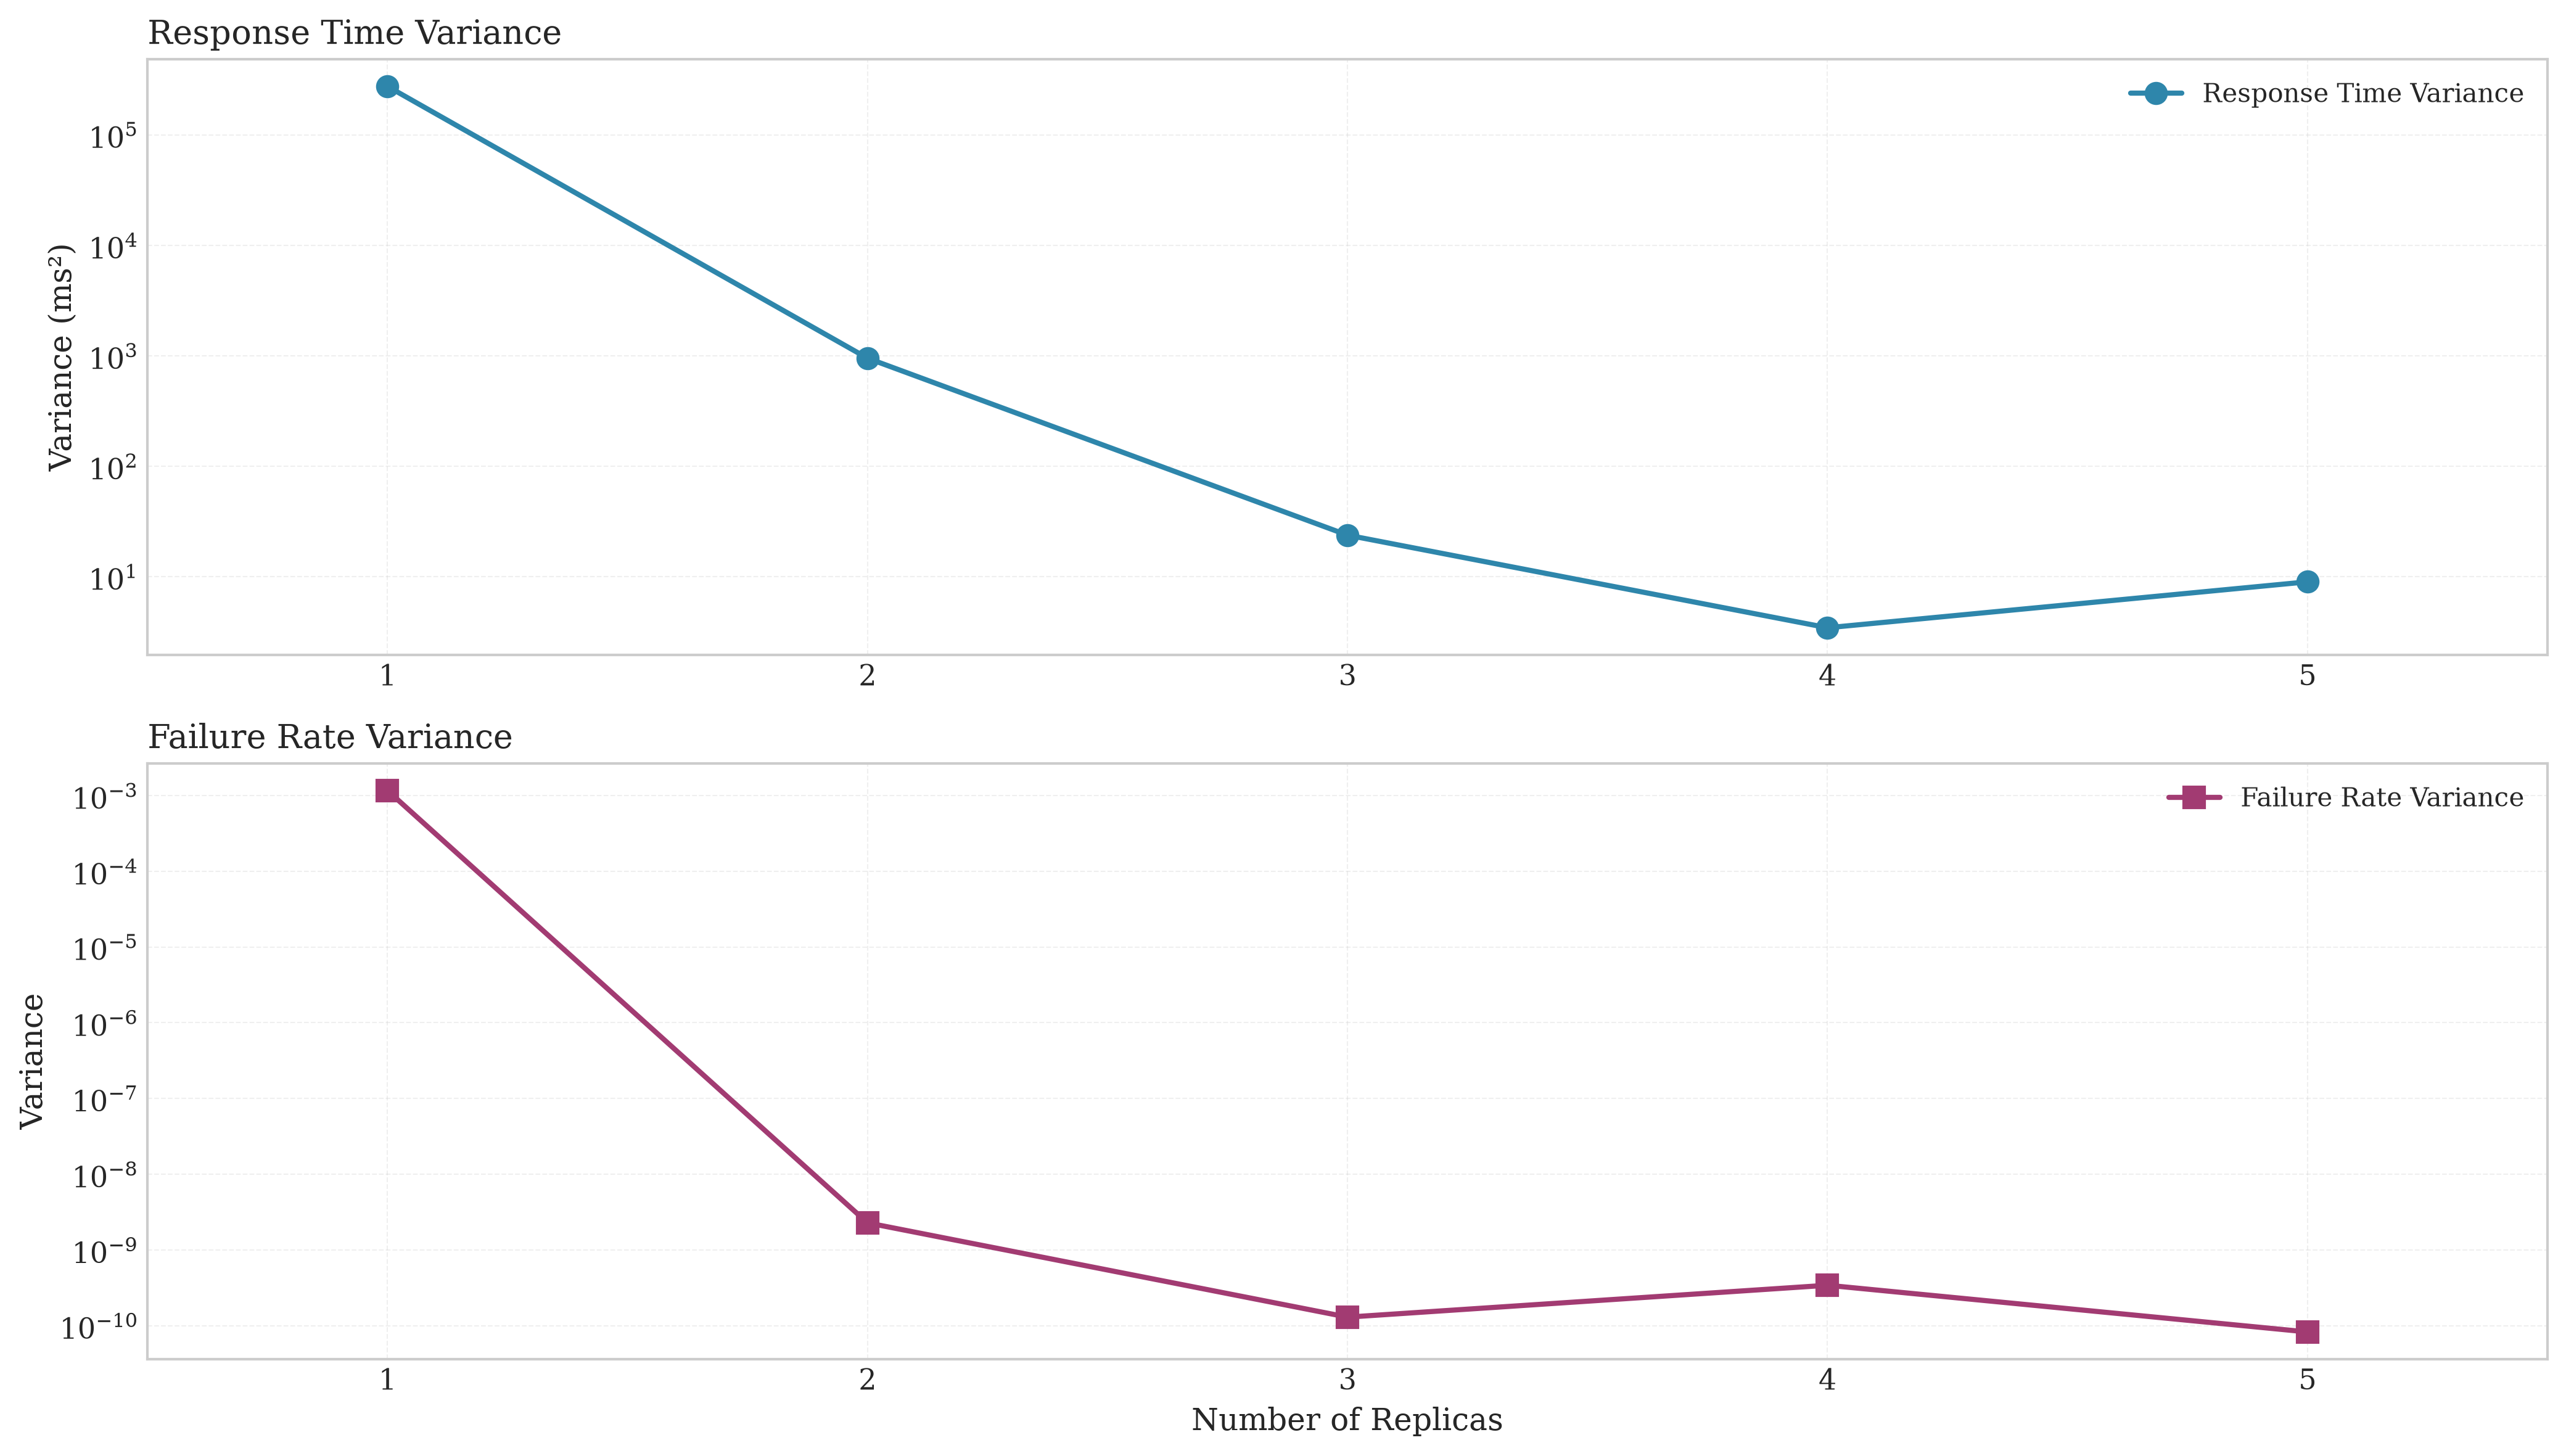

In [196]:
# Index(['autoscaler', 'trials', 'mean_rt', 'median_rt', 'sd_rt',
#        'mean_failure_rate', 'median_failure_rate', 'sd_failure_rate',
#        'mean_p99_response_time', 'median_p99_response_time',
#        'sd_p99_response_time', 'mean_roundtrip_completion_percentage',
#        'median_roundtrip_completion_percentage',
#        'sd_roundtrip_completion_percentage', 'total_quantity_ordered',
#        'total_quantity_placed', 'total_quantity_filled', 'ci95_rt',
#        'ci95_failure_rate', 'ci95_roundtrip_completion_percentage',
#        'pooled_roundtrip_completion_percentage'],
#       dtype='str')

df_u = autoscaler_summary_df.copy()
df_u['replicas'] = df_u["autoscaler"].str[-1].astype(int)


# --- Global style (unchanged) ---
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.dpi'] = 300

color_primary = '#2E86AB'
color_secondary = '#A23B72'

panel_labels = 'abcd'

# --- Figure 1: 2 metrics x 2 user counts ---
fig1, axes1 = plt.subplots(2, 1, figsize=(14, 8))
fig1.subplots_adjust(hspace=0.35, wspace=0.25)

# df_u = df[df['users'] == users].sort_values('replicas')

ax_rt = axes1[0]
ax_fr = axes1[1]

# --- Response Time Variance ---
rt_var = df_u['sd_rt'] ** 2

ax_rt.plot(df_u['replicas'], rt_var,
            marker='o', linewidth=2, markersize=8,
            color=color_primary, label='Response Time Variance')
ax_rt.set_yscale('log')
ax_rt.set_ylabel('Variance (ms²)')
ax_rt.set_title(f'Response Time Variance',
                loc='left')
ax_rt.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax_rt.set_xticks(df_u['replicas'])
ax_rt.legend()
ax_rt.set_xlim(df_u['replicas'].min() - 0.5,
                df_u['replicas'].max() + 0.5)
ax_rt.set_xlabel('')

# --- Failure Rate Variance ---
fr_var = df_u['sd_failure_rate'] ** 2

ax_fr.plot(df_u['replicas'], fr_var,
            marker='s', linewidth=2, markersize=8,
            color=color_secondary, label='Failure Rate Variance')
ax_fr.set_yscale('log')
ax_fr.set_ylabel('Variance')
ax_fr.set_xlabel('Number of Replicas')
ax_fr.set_title(f'Failure Rate Variance',
                loc='left')
ax_fr.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax_fr.set_xticks(df_u['replicas'])
ax_fr.legend()
ax_fr.set_xlim(df_u['replicas'].min() - 0.5,
                df_u['replicas'].max() + 0.5)

plt.tight_layout()
plt.savefig('../figures/experiment_1_rt_and_fr_variance_by_replica_count.png',
            dpi=300, bbox_inches='tight')
plt.show()

With confidence intervals

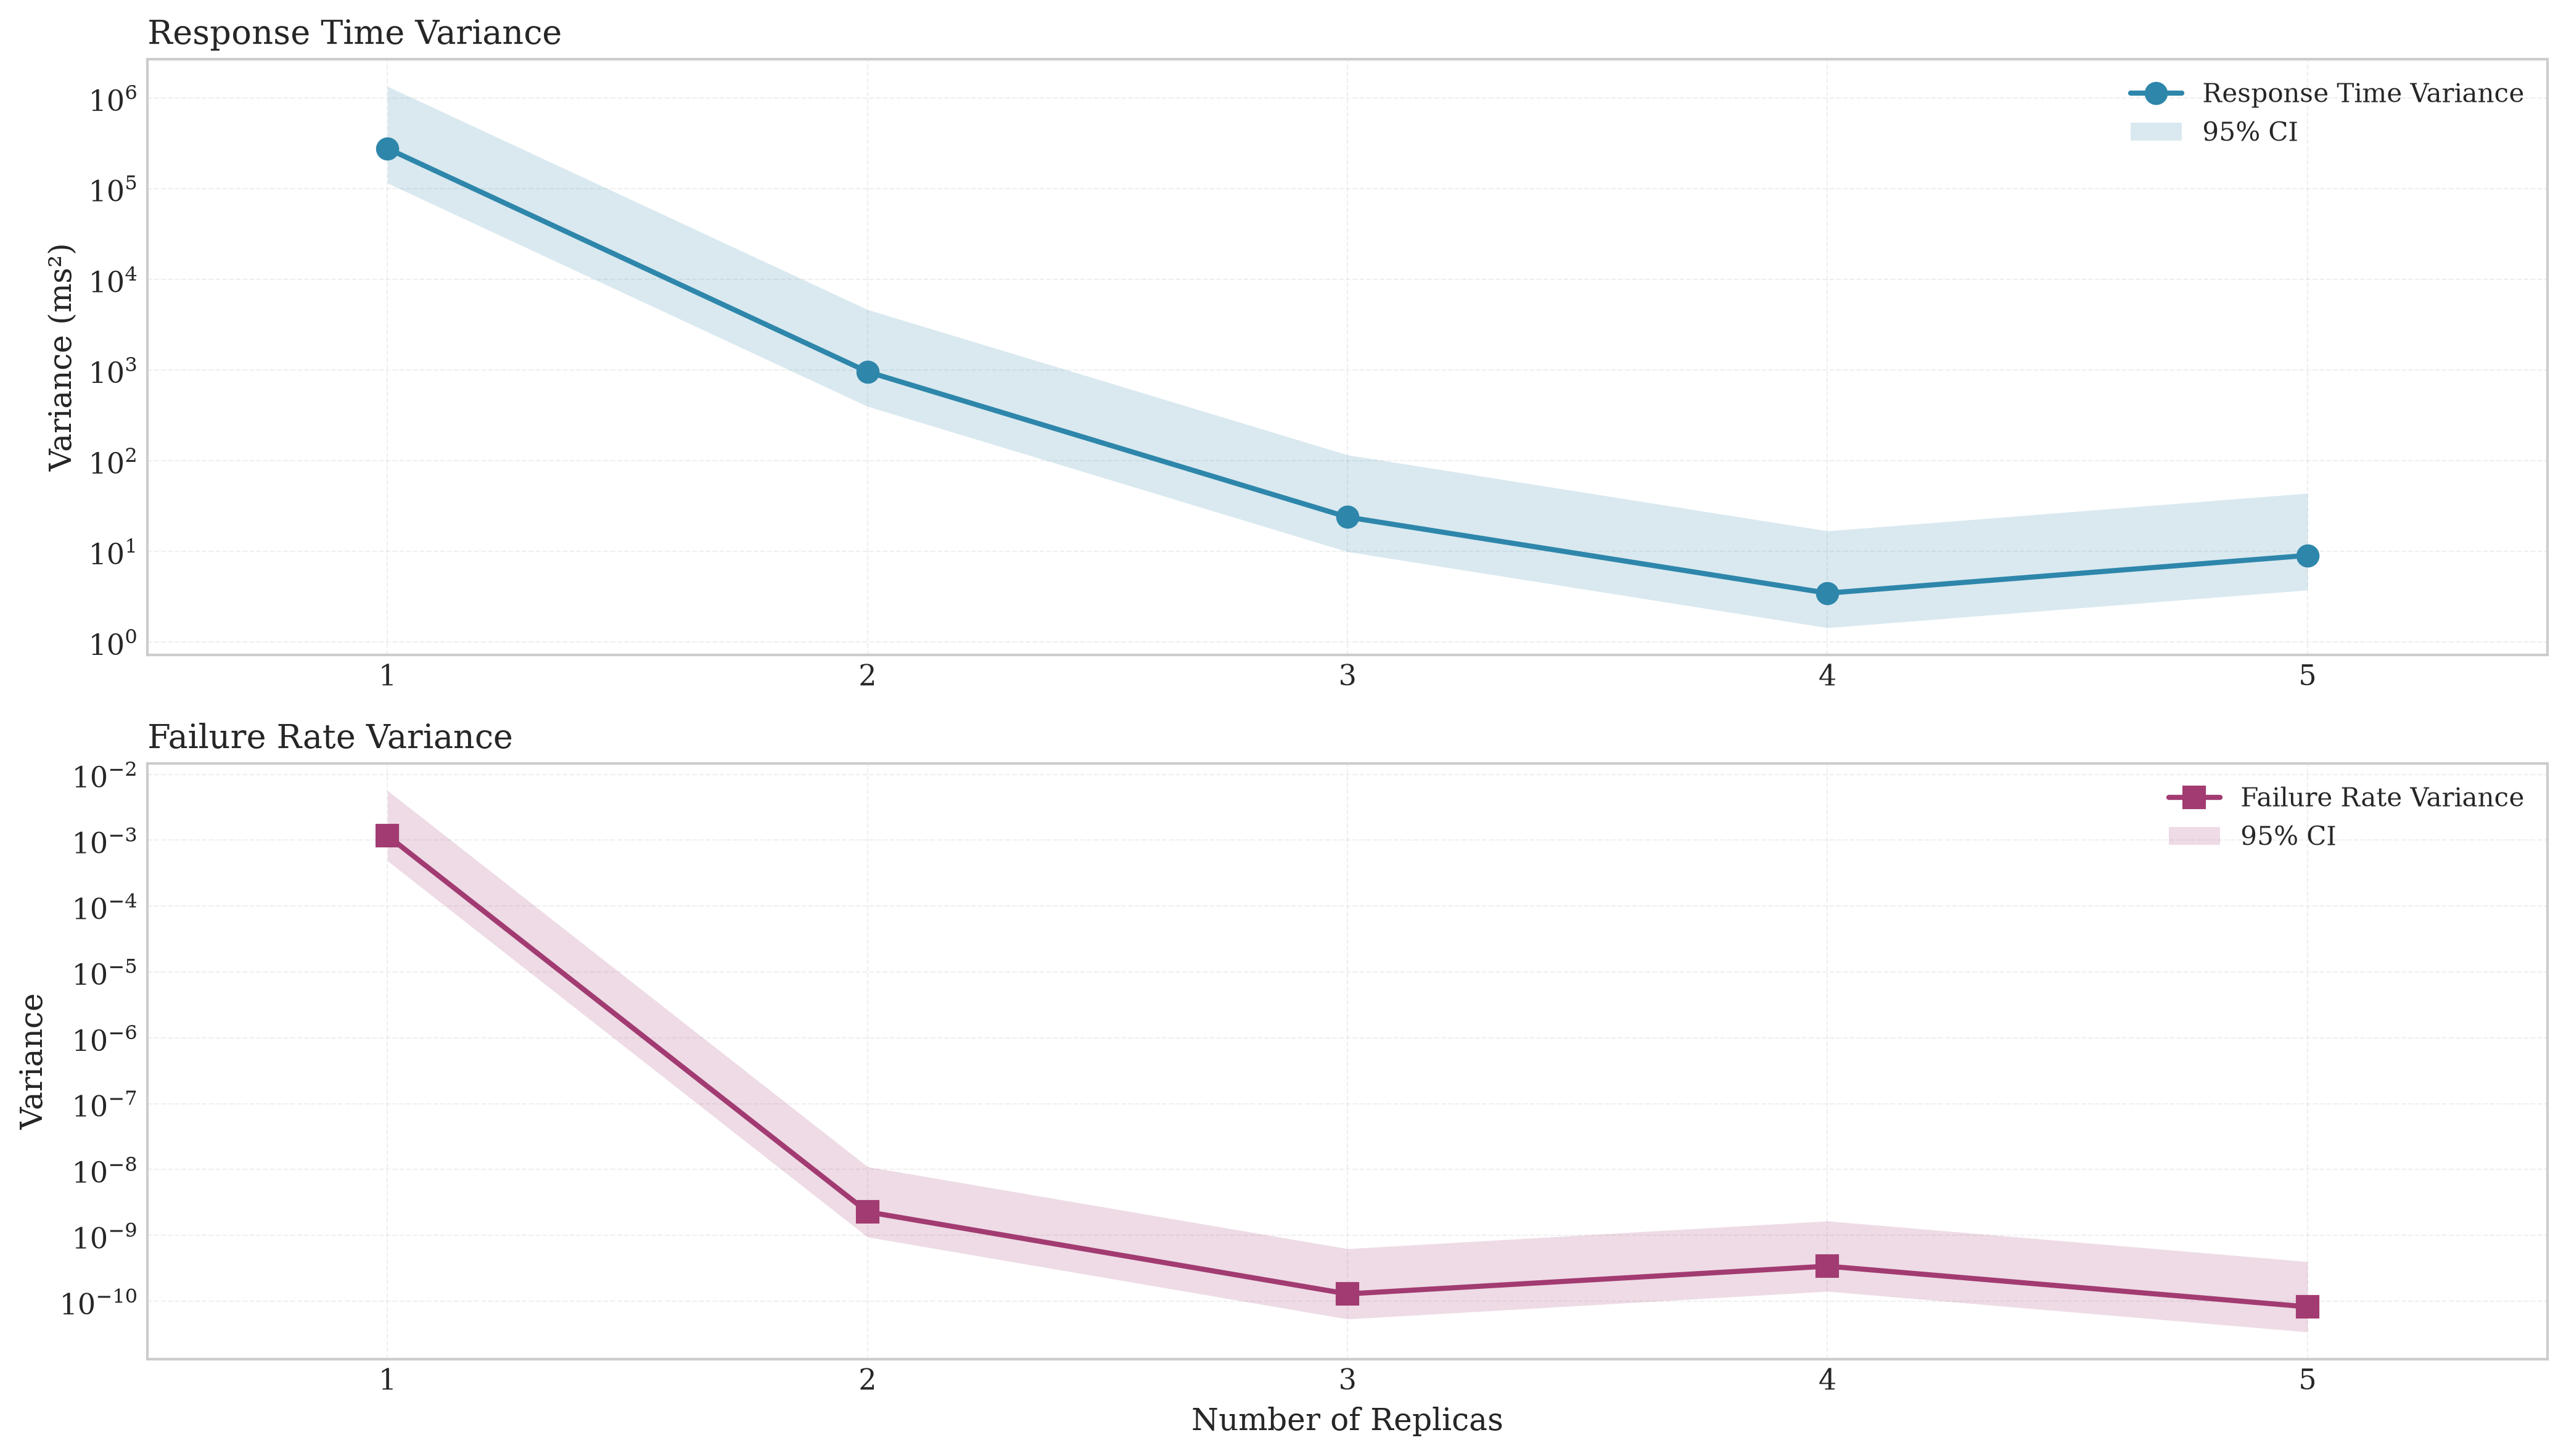

In [197]:

df_u = autoscaler_summary_df.copy()
df_u['replicas'] = df_u["autoscaler"].str[-1].astype(int)
df_u = df_u.sort_values('replicas')

# --- Variance confidence interval (chi-square) ---
# For a sample variance s^2 from n trials, the two-sided (1 - alpha)
# interval for the population variance is:
#     lower = (n - 1) s^2 / chi2_{1 - alpha/2, n-1}
#     upper = (n - 1) s^2 / chi2_{alpha/2, n-1}
# n (the trial count) can differ per replica level, so each point has its
# own interval width. Points with n < 2 have no defined interval.
confidence_level = 0.95
alpha = 1 - confidence_level

def variance_ci(sd, n):
    """Return (lower, upper) arrays for the variance CI; NaN where n < 2."""
    variance = sd ** 2
    dof = n - 1
    lower = np.where(n >= 2, dof * variance / chi2.ppf(1 - alpha / 2, dof), np.nan)
    upper = np.where(n >= 2, dof * variance / chi2.ppf(alpha / 2, dof), np.nan)
    return lower, upper

# --- Global style (unchanged) ---
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.dpi'] = 300

color_primary = '#2E86AB'
color_secondary = '#A23B72'

panel_labels = 'abcd'

# --- Figure 1: 2 metrics x 2 user counts ---
fig1, axes1 = plt.subplots(2, 1, figsize=(14, 8))
fig1.subplots_adjust(hspace=0.35, wspace=0.25)

ax_rt = axes1[0]
ax_fr = axes1[1]

# --- Response Time Variance ---
rt_var = df_u['sd_rt'] ** 2
rt_lower, rt_upper = variance_ci(df_u['sd_rt'], df_u['trials'])

ax_rt.plot(df_u['replicas'], rt_var,
           marker='o', linewidth=2, markersize=8,
           color=color_primary, label='Response Time Variance')
ax_rt.fill_between(df_u['replicas'], rt_lower, rt_upper,
                   color=color_primary, alpha=0.18, linewidth=0,
                   label=f'{confidence_level:.0%} CI')
ax_rt.set_yscale('log')
ax_rt.set_ylabel('Variance (ms²)')
ax_rt.set_title('Response Time Variance', loc='left')
ax_rt.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax_rt.set_xticks(df_u['replicas'])
ax_rt.legend()
ax_rt.set_xlim(df_u['replicas'].min() - 0.5,
               df_u['replicas'].max() + 0.5)
ax_rt.set_xlabel('')

# --- Failure Rate Variance ---
fr_var = df_u['sd_failure_rate'] ** 2
fr_lower, fr_upper = variance_ci(df_u['sd_failure_rate'], df_u['trials'])

ax_fr.plot(df_u['replicas'], fr_var,
           marker='s', linewidth=2, markersize=8,
           color=color_secondary, label='Failure Rate Variance')
ax_fr.fill_between(df_u['replicas'], fr_lower, fr_upper,
                   color=color_secondary, alpha=0.18, linewidth=0,
                   label=f'{confidence_level:.0%} CI')
ax_fr.set_yscale('log')
ax_fr.set_ylabel('Variance')
ax_fr.set_xlabel('Number of Replicas')
ax_fr.set_title('Failure Rate Variance', loc='left')
ax_fr.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax_fr.set_xticks(df_u['replicas'])
ax_fr.legend()
ax_fr.set_xlim(df_u['replicas'].min() - 0.5,
               df_u['replicas'].max() + 0.5)

plt.tight_layout()
plt.savefig('../figures/experiment_1_rt_and_fr_variance_by_replica_count.png',
            dpi=300, bbox_inches='tight')
plt.show()


Including roundtrip completion percentage

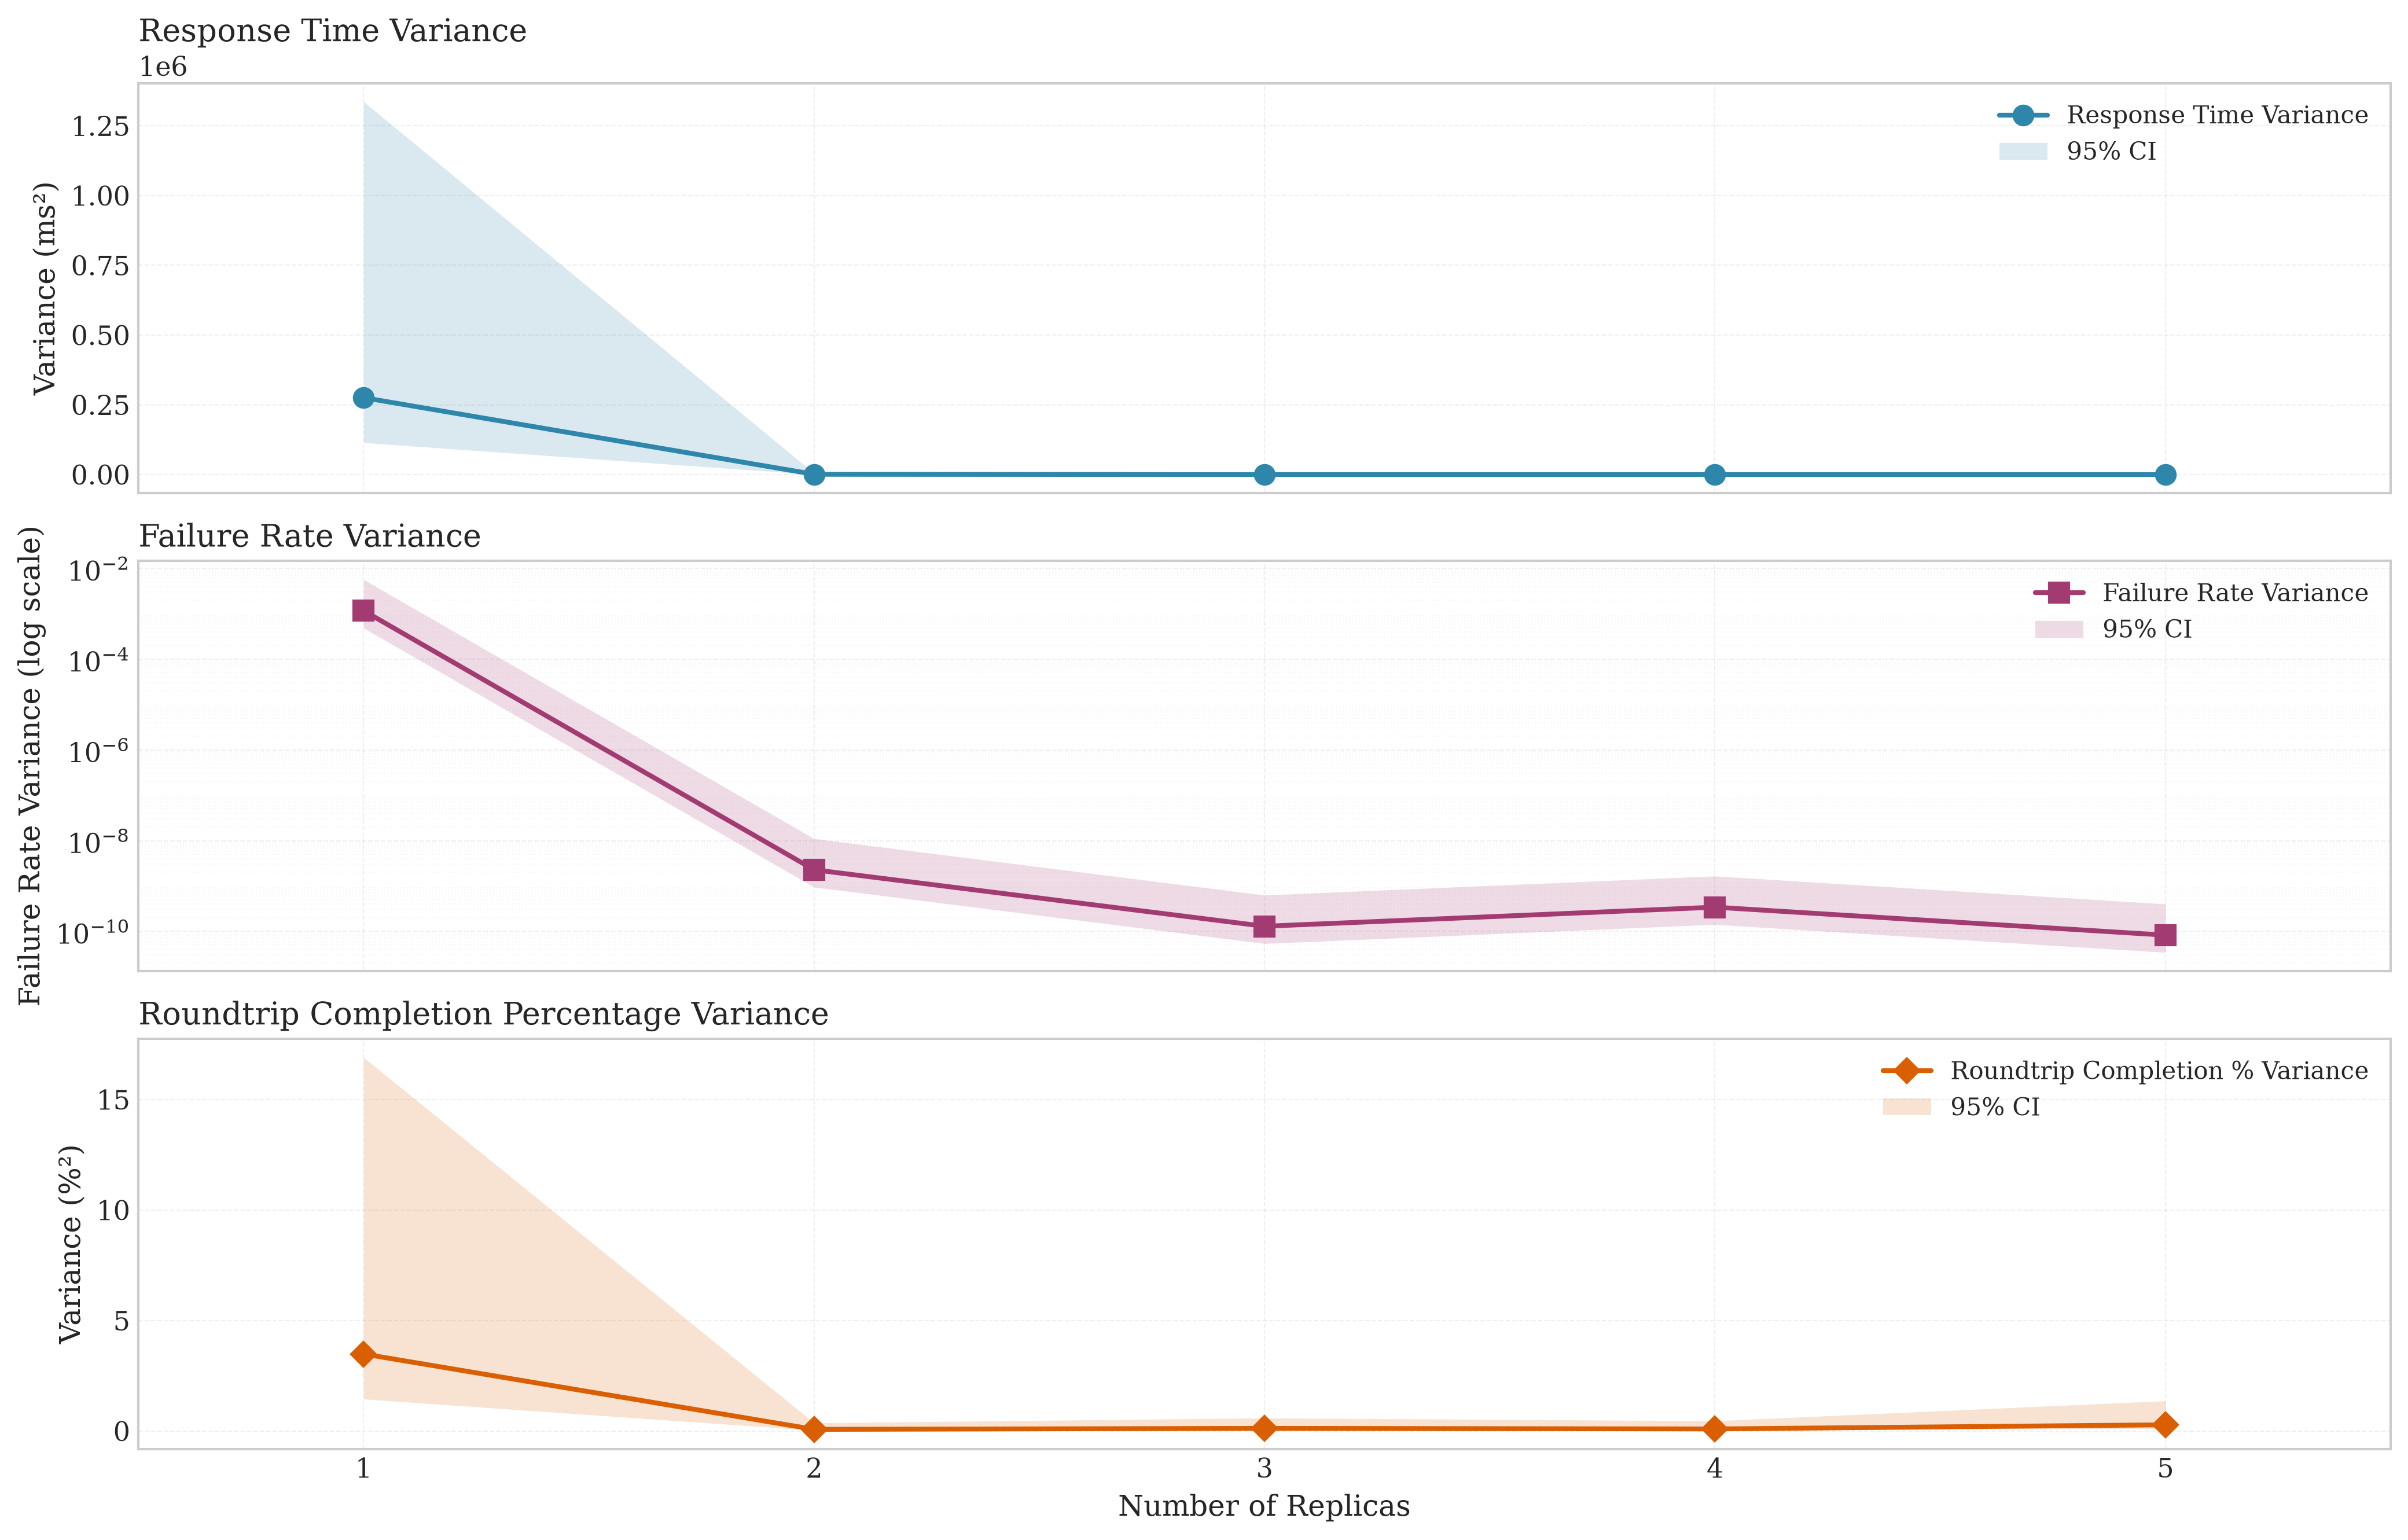

In [198]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
from scipy.stats import chi2

# --- Data Preparation ---
df_u = autoscaler_summary_df.copy()
df_u['replicas'] = df_u["autoscaler"].str[-1].astype(int)
df_u = df_u.sort_values('replicas')

confidence_level = 0.95
alpha = 1 - confidence_level

def variance_ci(sd, n):
    """Return (lower, upper) arrays for the variance CI; NaN where n < 2."""
    variance = sd ** 2
    dof = n - 1
    lower = np.where(n >= 2, dof * variance / chi2.ppf(1 - alpha / 2, dof), np.nan)
    upper = np.where(n >= 2, dof * variance / chi2.ppf(alpha / 2, dof), np.nan)
    return np.maximum(lower, 0.0), upper

# --- Global Style ---
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.dpi'] = 300

color_primary = '#2E86AB'    # Teal
color_secondary = '#A23B72'  # Magenta / Plum
color_tertiary = '#D95F02'   # Amber / Rust

x_min = df_u['replicas'].min() - 0.5
x_max = df_u['replicas'].max() + 0.5

# --- Figure Layout ---
fig1, axes1 = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
fig1.subplots_adjust(hspace=0.25)

ax_rt, ax_fr, ax_rtp = axes1

# -------------------------------------------------------------
# 1. Response Time Variance
# -------------------------------------------------------------
rt_var = df_u['sd_rt'] ** 2
rt_lower, rt_upper = variance_ci(df_u['sd_rt'], df_u['trials'])

ax_rt.plot(df_u['replicas'], rt_var,
           marker='o', linewidth=2, markersize=8,
           color=color_primary, label='Response Time Variance')
ax_rt.fill_between(df_u['replicas'], rt_lower, rt_upper,
                   color=color_primary, alpha=0.18, linewidth=0,
                   label=f'{confidence_level:.0%} CI')
ax_rt.set_ylabel('Variance (ms²)')
ax_rt.set_title('Response Time Variance', loc='left')
ax_rt.grid(True, which='major', alpha=0.3, linestyle='--', linewidth=0.5)
ax_rt.set_xlim(x_min, x_max)
ax_rt.legend(loc='upper right')

# -------------------------------------------------------------
# 2. Failure Rate Variance (Log Scale)
# -------------------------------------------------------------
fr_var = df_u['sd_failure_rate'] ** 2
fr_lower, fr_upper = variance_ci(df_u['sd_failure_rate'], df_u['trials'])

ax_fr.plot(df_u['replicas'], fr_var,
           marker='s', linewidth=2, markersize=8,
           color=color_secondary, label='Failure Rate Variance')
ax_fr.fill_between(df_u['replicas'], fr_lower, fr_upper,
                   color=color_secondary, alpha=0.18, linewidth=0,
                   label=f'{confidence_level:.0%} CI')
ax_fr.set_yscale('log')
ax_fr.set_ylabel('Failure Rate Variance (log scale)')
ax_fr.set_title('Failure Rate Variance', loc='left')
ax_fr.grid(True, which='major', alpha=0.3, linestyle='--', linewidth=0.5)
ax_fr.grid(True, which='minor', alpha=0.15, linestyle=':', linewidth=0.5)
ax_fr.yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10))
ax_fr.set_xlim(x_min, x_max)
ax_fr.legend(loc='upper right')

# -------------------------------------------------------------
# 3. Roundtrip Percentage Variance
# -------------------------------------------------------------
rtp_var = df_u['sd_roundtrip_completion_percentage'] ** 2
rtp_lower, rtp_upper = variance_ci(df_u['sd_roundtrip_completion_percentage'], df_u['trials'])

ax_rtp.plot(df_u['replicas'], rtp_var,
            marker='D', linewidth=2, markersize=7,
            color=color_tertiary, label='Roundtrip Completion % Variance')
ax_rtp.fill_between(df_u['replicas'], rtp_lower, rtp_upper,
                    color=color_tertiary, alpha=0.18, linewidth=0,
                    label=f'{confidence_level:.0%} CI')
ax_rtp.set_ylabel('Variance (%²)')
ax_rtp.set_xlabel('Number of Replicas')
ax_rtp.set_title('Roundtrip Completion Percentage Variance', loc='left')
ax_rtp.grid(True, which='major', alpha=0.3, linestyle='--', linewidth=0.5)
ax_rtp.set_xticks(df_u['replicas'])
ax_rtp.set_xlim(x_min, x_max)
ax_rtp.legend(loc='upper right')

plt.tight_layout()
plt.savefig('../figures/experiment_1_variance_by_replica_count.png',
            dpi=300, bbox_inches='tight')
plt.show()


Throughput stability (using CV)

I'm not going to use this

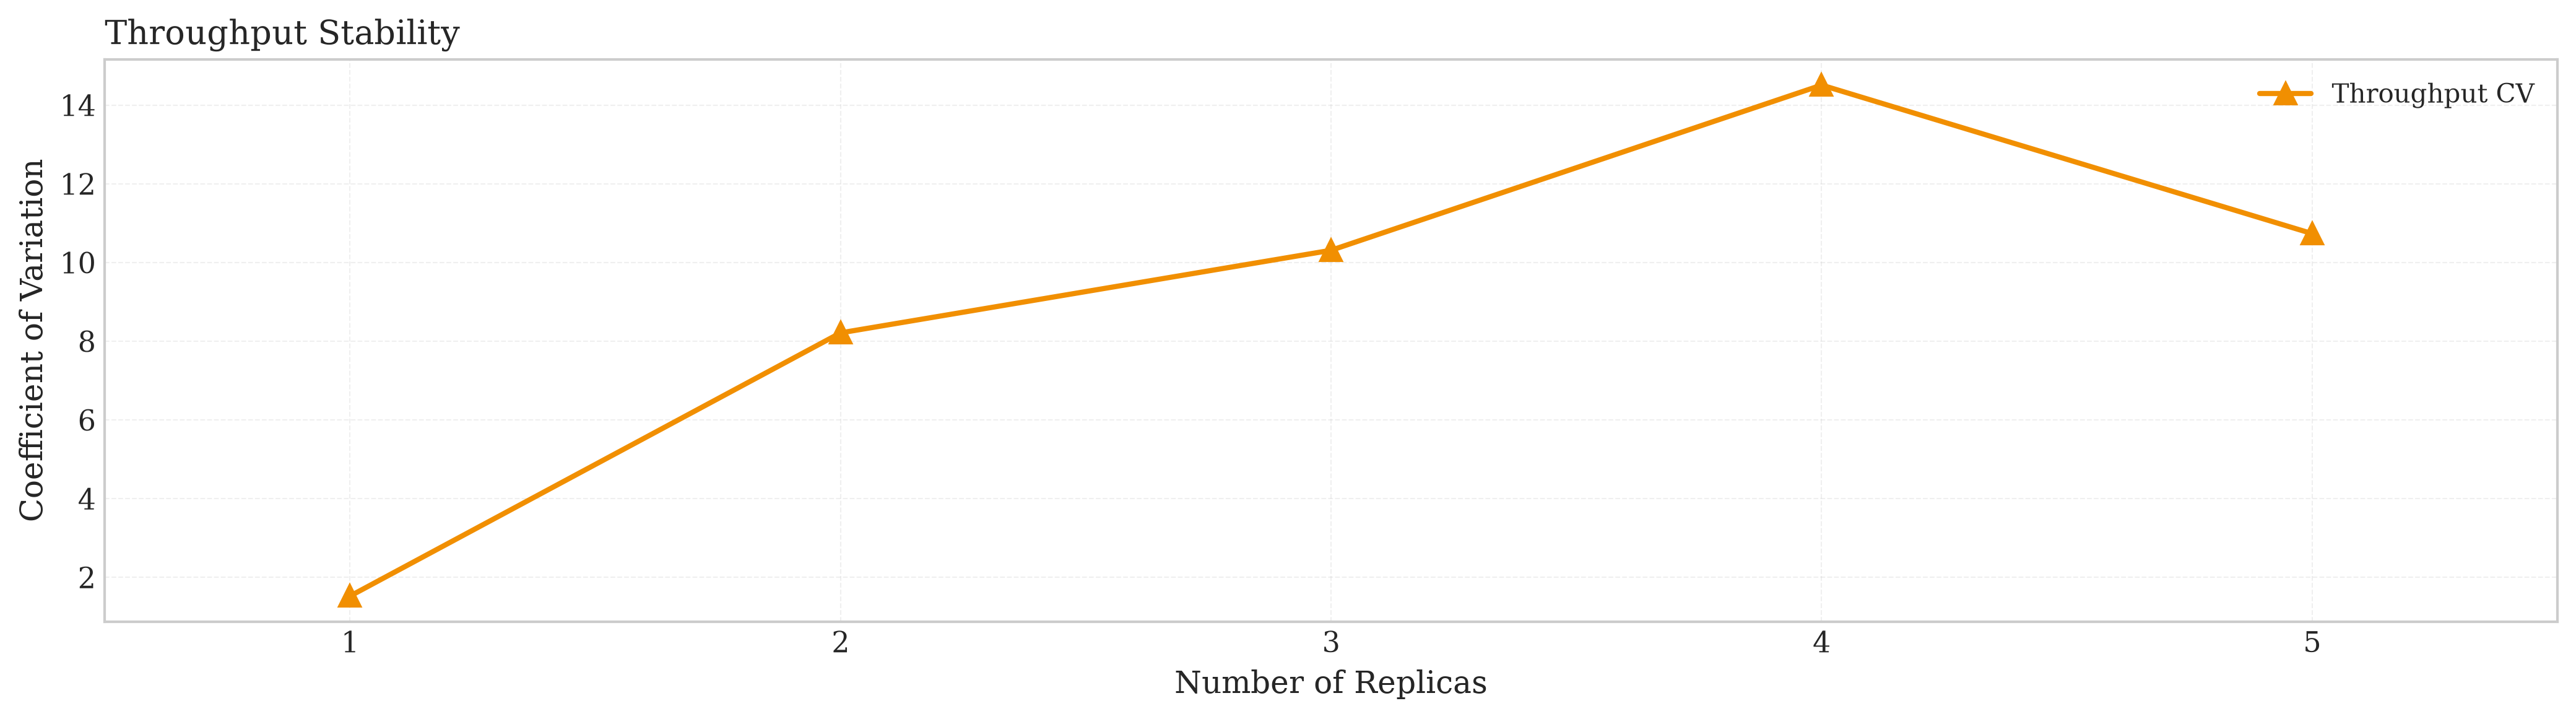

In [199]:
# Index(['autoscaler', 'trials', 'mean_rt', 'median_rt', 'sd_rt',
#        'mean_failure_rate', 'median_failure_rate', 'sd_failure_rate',
#        'mean_p99_response_time', 'median_p99_response_time',
#        'sd_p99_response_time', 'mean_roundtrip_completion_percentage',
#        'median_roundtrip_completion_percentage',
#        'sd_roundtrip_completion_percentage', 'total_quantity_ordered',
#        'total_quantity_placed', 'total_quantity_filled', 'ci95_rt',
#        'ci95_failure_rate', 'ci95_roundtrip_completion_percentage',
#        'pooled_roundtrip_completion_percentage'],
#       dtype='str')

# --- Figure 2: Throughput Stability ---
fig2, axes2 = plt.subplots(1, 1, figsize=(14, 4))
fig2.subplots_adjust(wspace=0.25)

color_tertiary = '#F18F01'
panel_labels = 'ef'

ax = axes2


# --- Throughput Coefficient of Variation ---
throughput_cv = (
    df_u['mean_roundtrip_completion_percentage'] /
    df_u['sd_roundtrip_completion_percentage']
)

ax.plot(df_u['replicas'], throughput_cv,
        marker='^', linewidth=2, markersize=8,
        color=color_tertiary, label='Throughput CV')

ax.set_xlabel('Number of Replicas')
ax.set_ylabel('Coefficient of Variation')
ax.set_title(f'Throughput Stability',
                loc='left')
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax.set_xticks(df_u['replicas'])
ax.legend()
ax.set_xlim(df_u['replicas'].min() - 0.5,
            df_u['replicas'].max() + 0.5)

plt.tight_layout()
plt.savefig('../figures/experiment_1_throughput_stability_by_replica_count.png',
            dpi=300, bbox_inches='tight')
plt.show()

## ANOVA

Baseline is one replica

H0: All group means are equal <br/>
H1: At least one group mean is different 


In [200]:
trial_summary_df

,autoscaler,trial_id,successful_requests,mean_response_time,sd_response_time,p99_response_time,unmodified_mean_response_time,sd_unmodified_response_time,requests,failures,failure_rate,sd_failure_rate
0,horizontal-1,trial0009,214740,1489.004370,4704.427806,22576.494879,2890.938000,9181.410215,225592,10852,0.048105,0.213988
1,horizontal-1,trial0010,253229,1010.337617,3885.285837,20954.923798,1888.534438,7315.369555,261693,8464,0.032343,0.176910
2,horizontal-1,trial0012,246923,781.059727,3748.065758,20985.710163,1597.077742,7290.770216,253519,6596,0.026018,0.159188
3,horizontal-1,trial0015,252082,622.326890,3245.195327,17203.263094,1114.116315,5890.344416,256292,4210,0.016427,0.127109
4,horizontal-1,trial0022,280160,848.639731,3548.033194,18483.471650,1430.944460,6145.970413,286390,6230,0.021754,0.145878
5,horizontal-1,trial0027,142432,2150.050726,5834.314209,35579.148979,5325.566734,12854.106062,161137,18705,0.116081,0.320323
6,horizontal-1,trial0034,189338,1275.227338,5084.194329,24724.583351,3001.778297,10348.701530,199881,10543,0.052746,0.223527
7,horizontal-2,trial0011,388313,157.341301,307.856948,1177.512434,157.330481,307.838288,388367,54,0.000139,0.011791
8,horizontal-2,trial0021,385149,157.979233,232.456378,1104.987864,157.967789,232.445840,385194,45,0.000117,0.010808
9,horizontal-2,trial0026,385156,162.820152,385.787666,1436.931095,162.809053,385.763181,385210,54,0.000140,0.011839


In [201]:
trial_summary_df.columns

Index(['autoscaler', 'trial_id', 'successful_requests', 'mean_response_time',
       'sd_response_time', 'p99_response_time',
       'unmodified_mean_response_time', 'sd_unmodified_response_time',
       'requests', 'failures', 'failure_rate', 'sd_failure_rate'],
      dtype='str')

In [203]:
def analyze_raw_scalability(df):
    results_list = []
    
    # Make a copy of the dataframe
    data = df.copy()

    # Add replica column
    data['replicas'] = data["autoscaler"].str[-1].astype(int)

    
    metrics = {
        'mean_response_time': 'Response Time (Mean)',
        'failure_rate': 'Failure Rate (Weighted)',
        'requests': 'Throughput (Total Requests)'
    }
    
    for col, label in metrics.items():
        # Prepare groups for 1, 2, 3, and 4 replicas
        groups = [data[data['replicas'] == i][col].dropna() for i in [1, 2, 3, 4, 5]]
        
        # Validate data presence
        if any(len(g) == 0 for g in groups):
            continue

        # Step 1: Omnibus Tests
        f_stat, p_anova = stats.f_oneway(*groups)
        h_stat, p_kruskal = stats.kruskal(*groups)
        
        # Step 2: Post-hoc Analysis
        if p_kruskal < 0.05:
            try:
                # Dunnett's test (SciPy 1.11.0+)
                res = stats.dunnett(*groups[1:], control=groups[0])
                for i, p_val in enumerate(res.pvalue):
                    comp_replica = i + 2
                    results_list.append({
                        'Metric': label,
                        'ANOVA p-value': p_anova,
                        'Kruskal p-value': p_kruskal,
                        'Comparison': f"1 vs {comp_replica}",
                        'PostHoc p-value': p_val,
                        'Significant': "Yes" if p_val < 0.05 else "No"
                    })
            except AttributeError:
                # Fallback to Tukey HSD
                tukey = pairwise_tukeyhsd(endog=data[col], groups=data['replicas'], alpha=0.05)
                tk_df = pd.DataFrame(data=tukey.summary().data[1:], columns=tukey.summary().data[0])
                # Filter for comparisons against the baseline (replica 1)
                vs_baseline = tk_df[tk_df['group1'] == 1]
                for _, row in vs_baseline.iterrows():
                    results_list.append({
                        'Users': user_count,
                        'Metric': label,
                        'ANOVA p-value': p_anova,
                        'Kruskal p-vallue': p_kruskal,
                        'Comparison': f"1 vs {row['group2']}",
                        'PostHoc p-value': row['p-adj'],
                        'Significant': row['reject']
                    })
        else:
            # If not significant, still record the omnibus result
            results_list.append({
                'Users': user_count,
                'Metric': label,
                'ANOVA p-value': p_anova,
                'Kruskal p-value': p_kruskal,
                'Comparison': "None",
                'PostHoc p-value': np.nan,
                'Significant': "No"
            })
            
    return results_list

# --- Execution and Collection ---
all_results = analyze_raw_scalability(trial_summary_df)

# Create the final DataFrame
results_df = pd.DataFrame(all_results)

# Optional: Format for your dissertation (round p-values)
results_df['ANOVA p-value'] = results_df['ANOVA p-value'].apply(lambda x: f"{x:.4e}")
results_df['Kruskal p-value'] = results_df['Kruskal p-value'].apply(lambda x: f"{x:.4e}")

results_df["ANOVA p-value"] = results_df["ANOVA p-value"].astype(float)
results_df["Kruskal p-value"] = results_df["Kruskal p-value"].astype(float)


# display(results_df)
results_df = results_df.set_index(["Metric", "ANOVA p-value", "Kruskal p-value", "Comparison"])

print(results_df)

# latex = results_df.to_latex()
# print(latex)

format_dict = {
    'ANOVA p-value': '{:.4f}',
    'Kruskal p-value': '{:.4f}',
    "PostHoc p-value": '{:.4f}'
}


# Apply the formatting and export to LaTeX
latex = results_df.style.format(format_dict, na_rep='').to_latex(
    caption="Experiment 1 ANOVA and Kruskal test result",
    label="tab:experiment-1-anova-kruskal-results",
    hrules=True
)

latex = latex.replace("%", r"\%")
latex = latex.replace("Response Time (Mean)",r"\makecell[l]{Response Time\\(Mean)}")
latex = latex.replace("Failure Rate (Weighted)", r"\makecell[l]{Failure Rate\\(Weighted)}")
latex = latex.replace("Throughput (Total Requests)", r"\makecell[l]{Throughput\\(Total\\Requests)}")
latex = latex.replace("ANOVA p-value", r"\makecell[c]{ANOVA\\p-value}")
latex = latex.replace("Kruskal p-value", r"\makecell[c]{Kruskal\\p-value}")
latex = latex.replace("PostHoc p-value", r"\makecell[c]{PostHoc\\p-value}")
latex = latex.replace("0.000000", "$< 0.001$")
latex = latex.replace("0.0000", "$< 0.001$")
latex = latex.replace(r"\multirow[c]{9}{*}{80}", r"\addlinespace[2ex]\multirow[c]{9}{*}{80}")


pyperclip.copy(latex)

print(latex)




# To export to Excel:
# results_df.to_excel("scalability_analysis_results.xlsx", index=False)

                                                                      PostHoc p-value  \
Metric                      ANOVA p-value Kruskal p-value Comparison                    
Response Time (Mean)        6.681700e-10  0.000006        1 vs 2         1.016167e-08   
                                                          1 vs 3         4.207412e-10   
                                                          1 vs 4         4.265572e-09   
                                                          1 vs 5         1.551341e-09   
Failure Rate (Weighted)     6.085100e-06  0.000067        1 vs 2         2.518751e-05   
                                                          1 vs 3         2.600598e-05   
                                                          1 vs 4         1.841109e-05   
                                                          1 vs 5         2.173587e-05   
Throughput (Total Requests) 3.519900e-16  0.000098        1 vs 2         0.000000e+00   
                     

## Scaling efficiency

In [204]:
df = merged_trial_summary_df.copy()
df['replicas'] = df["autoscaler"].str[-1].astype(int)
df = df.drop(columns=["autoscaler"])
df.columns


Index(['trial_id', 'successful_requests', 'mean_response_time',
       'sd_response_time', 'p99_response_time',
       'unmodified_mean_response_time', 'sd_unmodified_response_time',
       'requests', 'failures', 'failure_rate', 'sd_failure_rate',
       'quantity_ordered', 'quantity_placed', 'quantity_filled',
       'roundtrip_completion_percentage', 'replicas'],
      dtype='str')

I'm not going to use this one

,metric,metric_label,replicas,trials,baseline_mean,level_mean,efficiency,ci_lower,ci_upper
0,mean_response_time,Mean response time,1,7,1168.092343,1168.092343,1.000000,1.000000,1.000000
1,mean_response_time,Mean response time,2,7,1168.092343,158.560403,3.683430,2.590110,5.121699
2,mean_response_time,Mean response time,3,7,1168.092343,89.206835,4.364734,3.144741,5.820921
3,mean_response_time,Mean response time,4,7,1168.092343,80.544881,3.625595,2.628776,4.845431
4,mean_response_time,Mean response time,5,7,1168.092343,81.872019,2.853459,2.058538,3.805203
5,failure_rate,Failure rate,1,7,0.044782,0.044782,1.000000,1.000000,1.000000
6,failure_rate,Failure rate,2,7,0.044782,0.000120,186.063453,101.844894,328.646088
7,failure_rate,Failure rate,3,7,0.044782,0.000036,414.937651,227.331437,688.853236
8,failure_rate,Failure rate,4,7,0.044782,0.000036,310.988326,160.844584,569.714057
9,failure_rate,Failure rate,5,7,0.044782,0.000036,250.656769,140.107423,410.725814


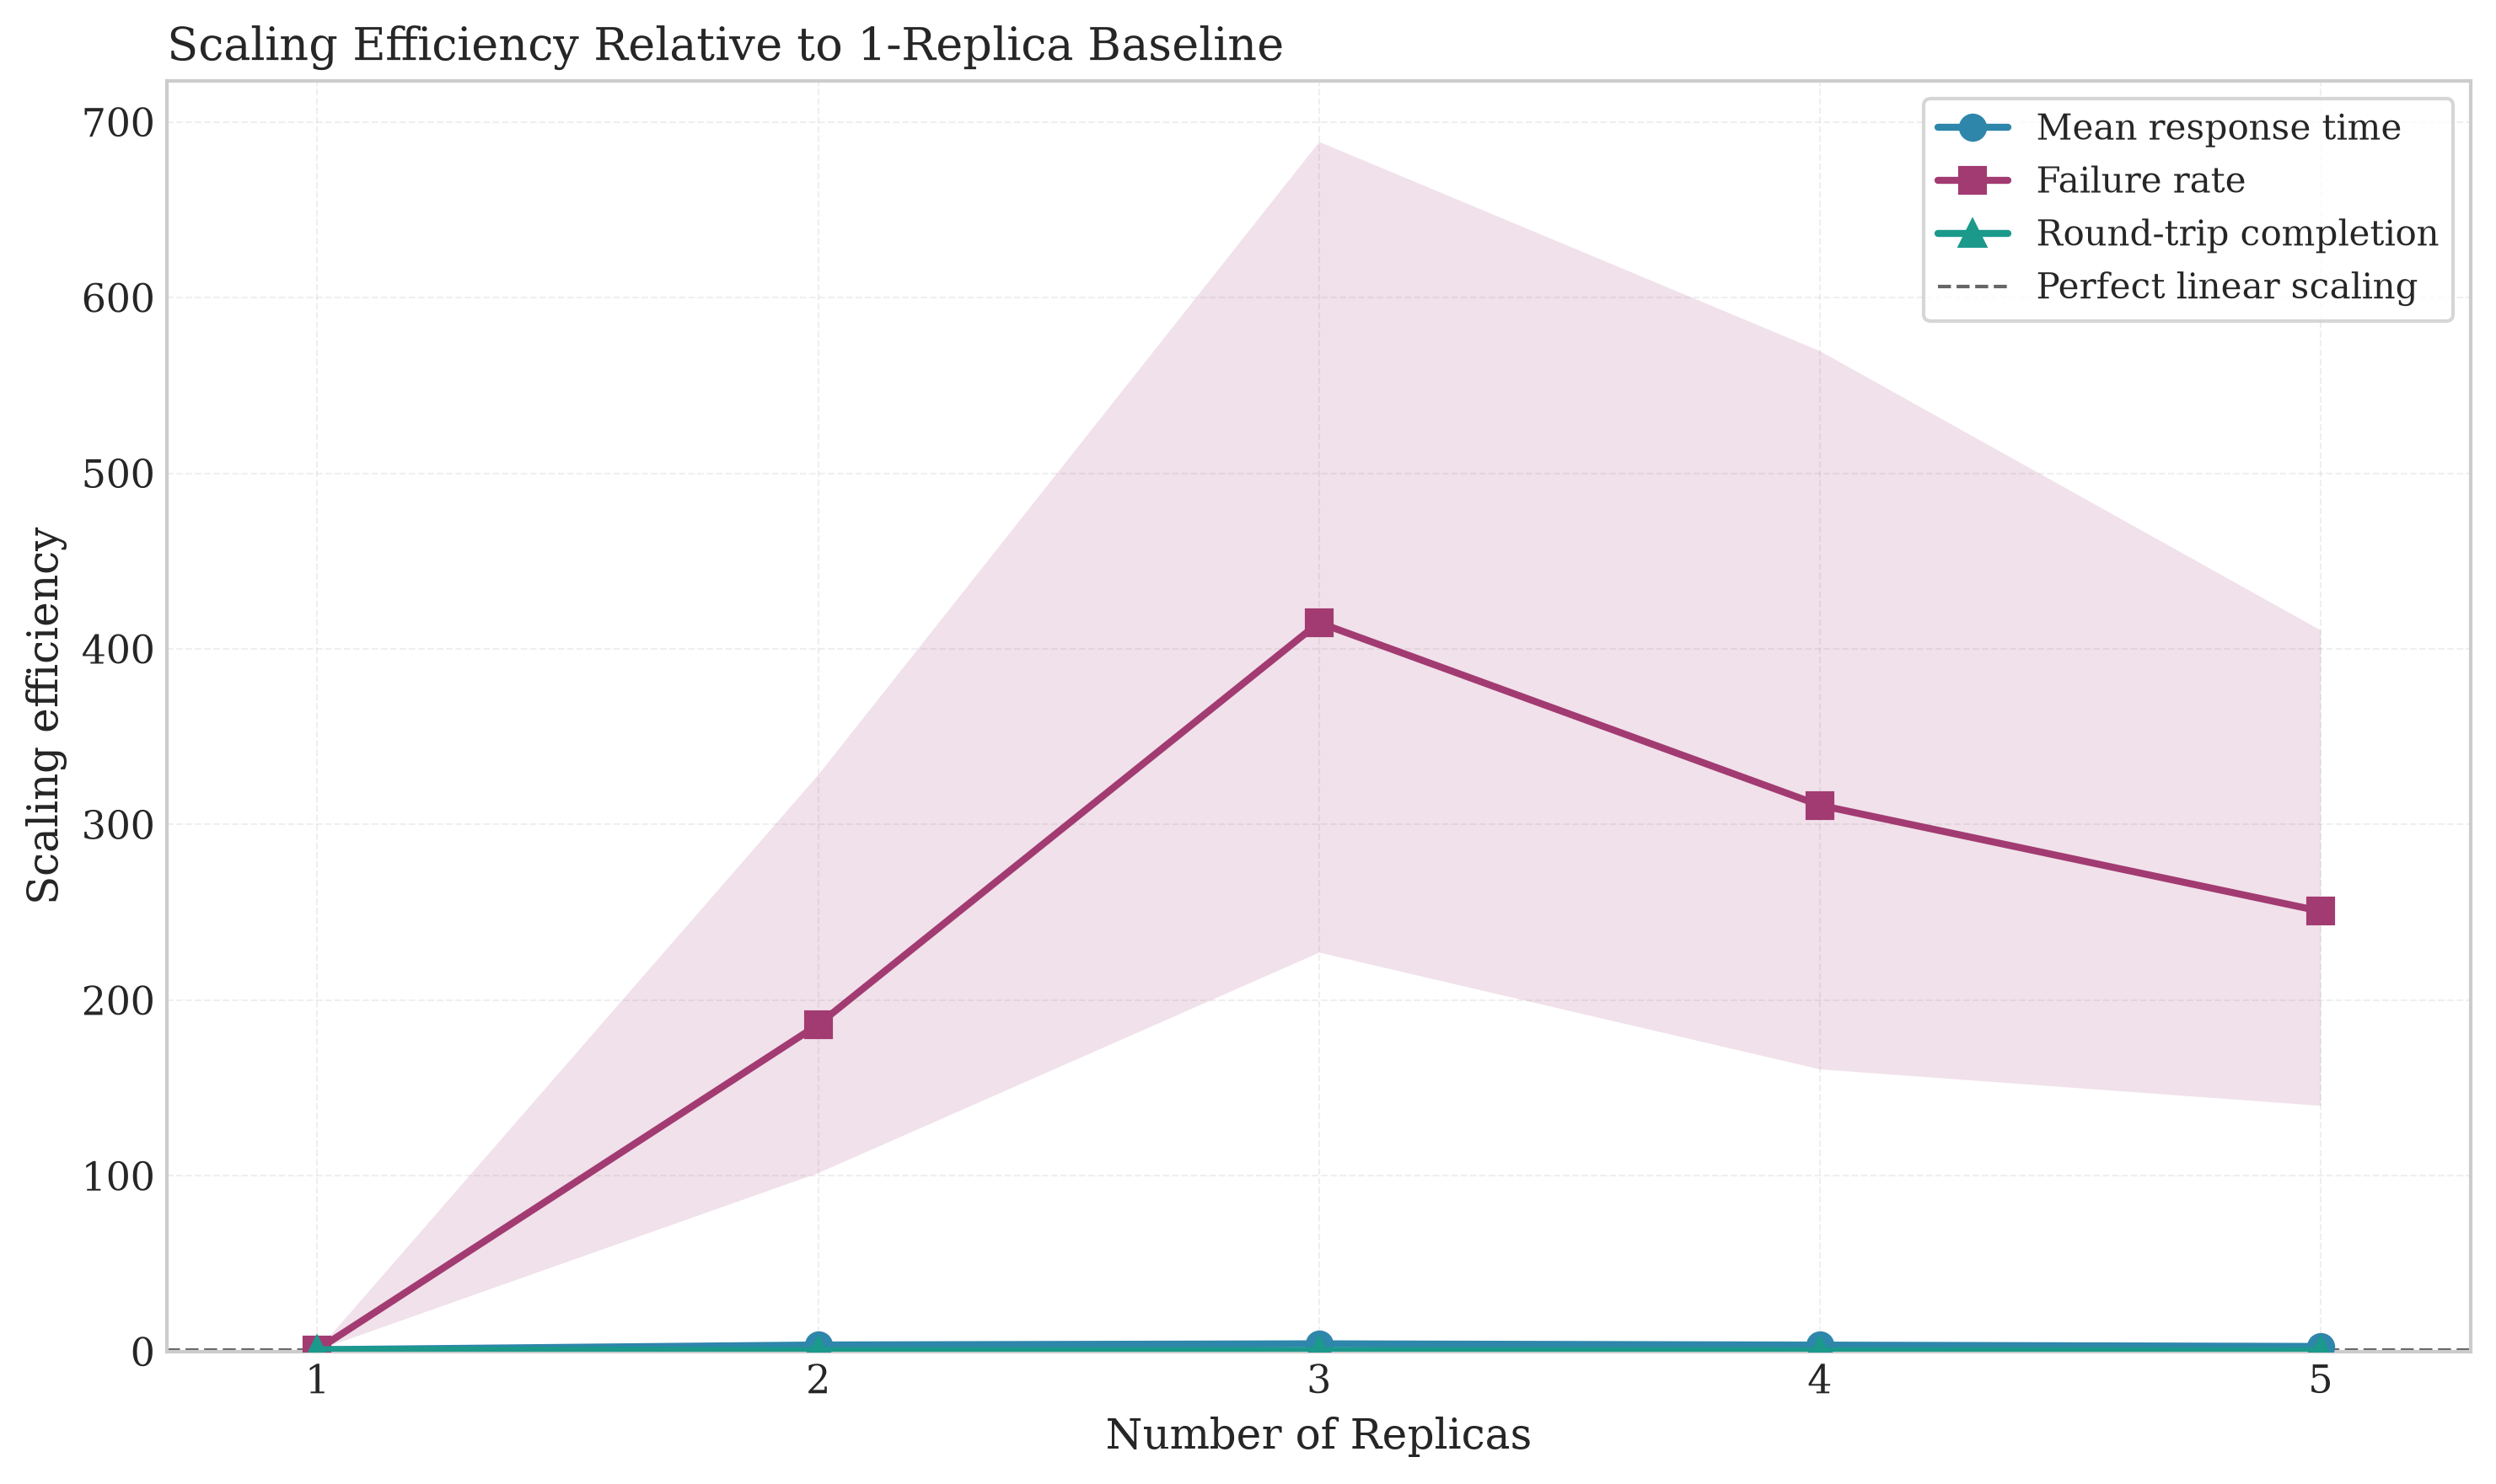

In [205]:

# ----------------------------------------------------------------------
# Scaling efficiency relative to the 1-replica baseline.
#
# Efficiency(N) = speedup(N) / N, where speedup is measured against the
# baseline (N = 1). Efficiency = 1.0 is perfect linear scaling; values
# below 1.0 indicate diminishing returns from adding replicas.
#
#   mean_response_time (lower is better):
#       speedup(N) = R(1) / R(N)   ->  efficiency = R(1) / (N * R(N))
#
#   roundtrip_completion_percentage (higher is better):
#       speedup(N) = C(N) / C(1)   ->  efficiency = C(N) / (N * C(1))
#
#   failure_rate (lower is better):
#       speedup(N) = F(1) / F(N)   ->  efficiency = F(1) / (N * F(N))
#       Undefined (NaN) when the baseline failure rate is 0.
# ----------------------------------------------------------------------

BASELINE_REPLICAS = 1
CONFIDENCE_LEVEL = 0.95
N_BOOTSTRAP = 10_000
RANDOM_SEED = 42

# (column, direction, label). direction is "lower" or "higher" = better.
METRICS = [
    ("mean_response_time", "lower", "Mean response time"),
    ("failure_rate", "lower", "Failure rate"),
    ("roundtrip_completion_percentage", "higher", "Round-trip completion"),
]

def _efficiency(baseline_mean, level_mean, n, direction):
    """Scaling efficiency of a level mean vs the baseline mean."""
    if direction == "lower":
        # Lower is better: speedup = baseline / level.
        if level_mean == 0:
            return np.nan
        speedup = baseline_mean / level_mean
    else:
        # Higher is better: speedup = level / baseline.
        if baseline_mean == 0:
            return np.nan
        speedup = level_mean / baseline_mean
    return speedup / n

def compute_scaling_efficiency(
    trial_df,
    metrics=METRICS,
    baseline_replicas=BASELINE_REPLICAS,
    confidence_level=CONFIDENCE_LEVEL,
    n_bootstrap=N_BOOTSTRAP,
    random_seed=RANDOM_SEED,
):
    """
    Compute per-replica scaling efficiency for each metric, with a
    bootstrap confidence interval.

    Returns a tidy DataFrame with one row per (metric, replicas).
    """
    df = trial_df.copy()
    df["replicas"] = pd.to_numeric(df["replicas"], errors="raise")

    for column, _, _ in metrics:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    if baseline_replicas not in set(df["replicas"]):
        raise ValueError(
            f"No trials found at the baseline of {baseline_replicas} replica(s)."
        )

    rng = np.random.default_rng(random_seed)
    alpha = 1 - confidence_level
    replica_levels = sorted(df["replicas"].unique())

    rows = []

    for column, direction, label in metrics:
        baseline_values = (
            df.loc[df["replicas"] == baseline_replicas, column]
            .dropna()
            .to_numpy()
        )
        baseline_mean = baseline_values.mean()

        for n in replica_levels:
            level_values = (
                df.loc[df["replicas"] == n, column].dropna().to_numpy()
            )
            level_mean = level_values.mean()

            point = _efficiency(baseline_mean, level_mean, n, direction)

            # Bootstrap the efficiency by resampling trials within the
            # baseline and the current level. Efficiency is a ratio of means,
            # so a closed-form interval is not available.
            if n == baseline_replicas:
                # Efficiency is 1.0 by construction at the baseline.
                ci_lower = ci_upper = point
            elif len(baseline_values) >= 2 and len(level_values) >= 2:
                boot = np.empty(n_bootstrap)
                for b in range(n_bootstrap):
                    bl = rng.choice(
                        baseline_values, size=len(baseline_values), replace=True
                    ).mean()
                    lv = rng.choice(
                        level_values, size=len(level_values), replace=True
                    ).mean()
                    boot[b] = _efficiency(bl, lv, n, direction)
                boot = boot[np.isfinite(boot)]
                if boot.size:
                    ci_lower, ci_upper = np.quantile(
                        boot, [alpha / 2, 1 - alpha / 2]
                    )
                else:
                    ci_lower = ci_upper = np.nan
            else:
                ci_lower = ci_upper = np.nan

            rows.append(
                {
                    "metric": column,
                    "metric_label": label,
                    "replicas": n,
                    "trials": len(level_values),
                    "baseline_mean": baseline_mean,
                    "level_mean": level_mean,
                    "efficiency": point,
                    "ci_lower": ci_lower,
                    "ci_upper": ci_upper,
                }
            )

    return pd.DataFrame(rows)

# ----------------------------------------------------------------------
# Compute results
# ----------------------------------------------------------------------
efficiency_df = compute_scaling_efficiency(df) 
display(efficiency_df)

# ----------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------
plt.rcParams["font.family"] = "serif"
plt.rcParams["figure.dpi"] = 300

colors = {
    "mean_response_time": "#2E86AB",
    "failure_rate": "#A23B72",
    "roundtrip_completion_percentage": "#1B998B",
}
markers = {
    "mean_response_time": "o",
    "failure_rate": "s",
    "roundtrip_completion_percentage": "^",
}

fig, ax = plt.subplots(figsize=(10, 6))

replica_levels = sorted(efficiency_df["replicas"].unique())

for column, _, label in METRICS:
    sub = efficiency_df[efficiency_df["metric"] == column].sort_values(
        "replicas"
    )

    ax.plot(
        sub["replicas"],
        sub["efficiency"],
        marker=markers[column],
        linewidth=2,
        markersize=7,
        color=colors[column],
        label=label,
        zorder=3,
    )

    ax.fill_between(
        sub["replicas"],
        sub["ci_lower"],
        sub["ci_upper"],
        color=colors[column],
        alpha=0.15,
        linewidth=0,
        zorder=1,
    )

# Perfect linear scaling reference.
ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.0,
    color="0.4",
    label="Perfect linear scaling",
    zorder=2,
)

ax.set_xlabel("Number of Replicas")
ax.set_ylabel("Scaling efficiency")
ax.set_title(
    "Scaling Efficiency Relative to 1-Replica Baseline", loc="left"
)
ax.set_xticks(replica_levels)
ax.set_xlim(min(replica_levels) - 0.3, max(replica_levels) + 0.3)
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3, linestyle="--", linewidth=0.5)
ax.legend(frameon=True)

plt.tight_layout()
plt.savefig(
    "../figures/experiment_1_scaling_efficiency_by_replica_count.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


Use this one

,replicas,trials,baseline_throughput,throughput,speedup,efficiency,ci_lower,ci_upper
0,1,7,0.000997,0.000997,1.000000,1.000000,1.000000,1.000000
1,2,7,0.000997,0.006541,6.563348,3.281674,2.463243,4.633162
2,3,7,0.000997,0.011240,11.278375,3.759458,2.933353,5.067831
3,4,7,0.000997,0.012421,12.463546,3.115887,2.464087,4.250559
4,5,7,0.000997,0.012228,12.270061,2.454012,1.928321,3.328219


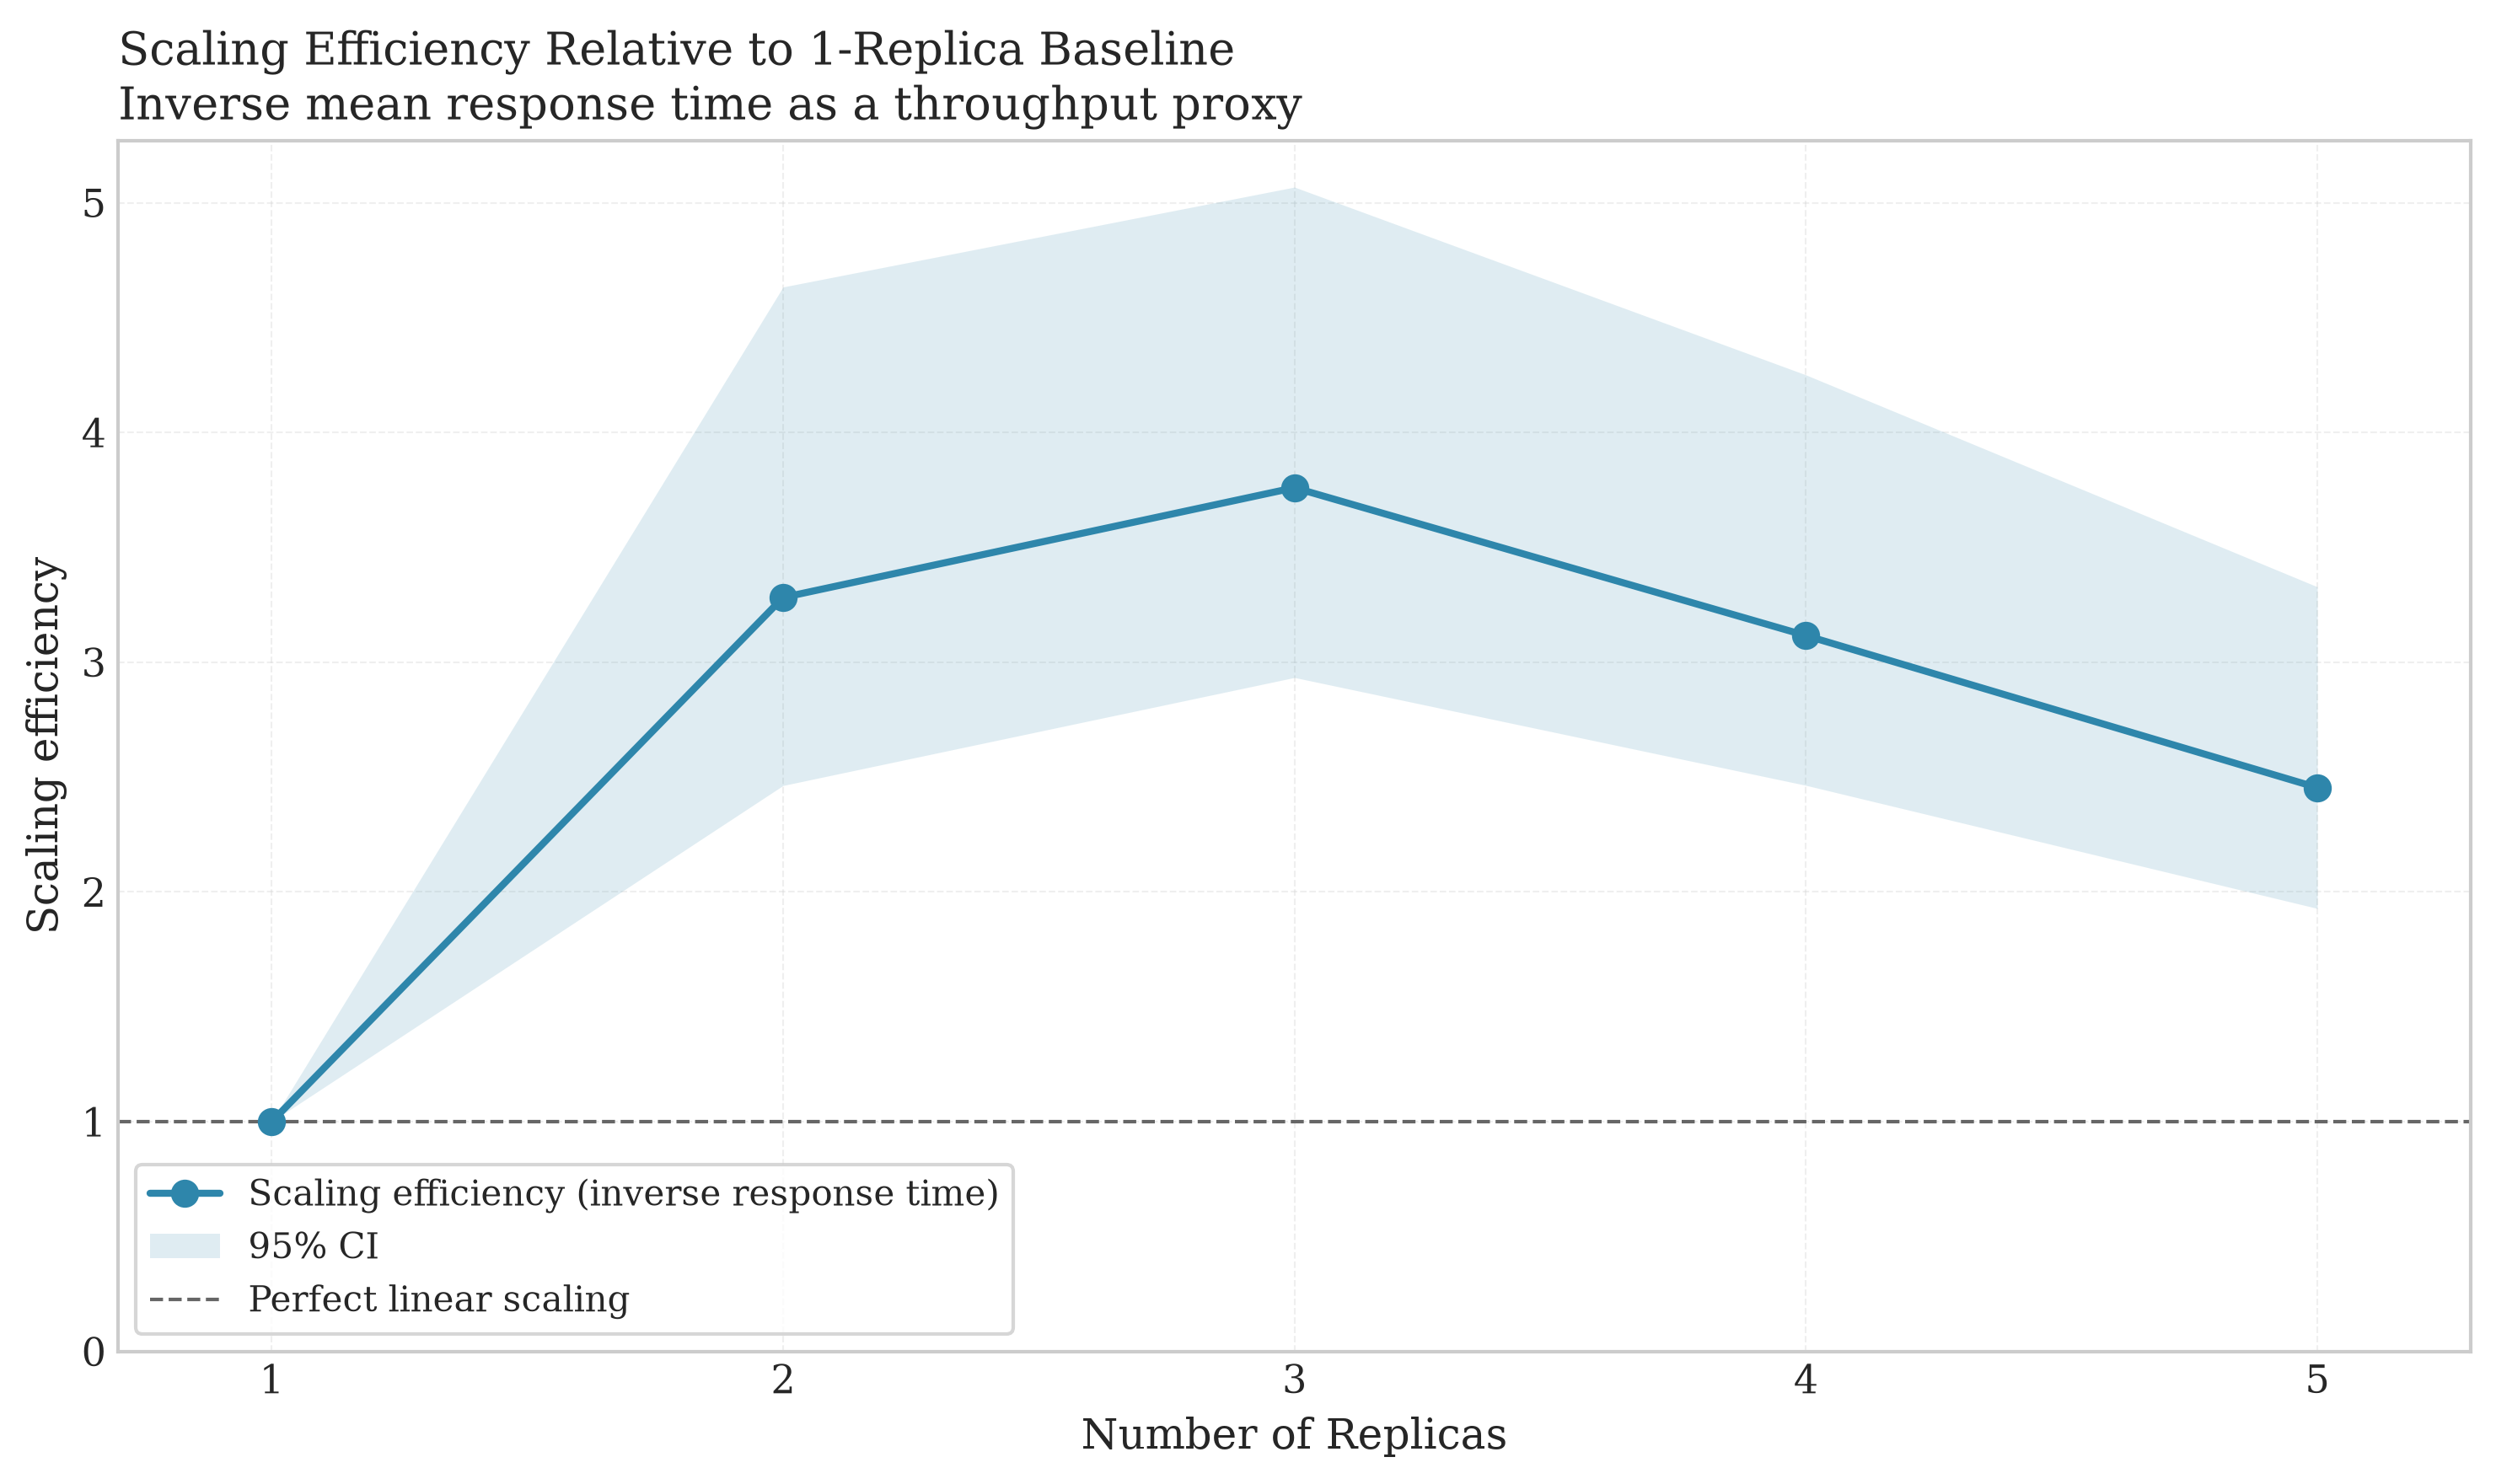

In [206]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# Scaling efficiency relative to the 1-replica baseline, using inverse
# mean response time as a throughput proxy:
#
#     X = 1 / mean_response_time   (higher is better)
#
# Efficiency(N) = speedup(N) / N = X(N) / (N * X(1)). Efficiency = 1.0 is
# perfect linear scaling; values below 1.0 indicate diminishing returns.
#
# The inverse is taken per trial and then averaged, which is the more
# correct throughput estimate and lets the bootstrap resample the actual
# per-trial quantity.
# ----------------------------------------------------------------------

BASELINE_REPLICAS = 1
CONFIDENCE_LEVEL = 0.95
N_BOOTSTRAP = 10_000
RANDOM_SEED = 42

def compute_scaling_efficiency(
    trial_df,
    baseline_replicas=BASELINE_REPLICAS,
    confidence_level=CONFIDENCE_LEVEL,
    n_bootstrap=N_BOOTSTRAP,
    random_seed=RANDOM_SEED,
):
    """
    Compute per-replica scaling efficiency from inverse response time,
    with a bootstrap confidence interval.

    Returns a tidy DataFrame with one row per replica level.
    """
    df = trial_df.copy()
    df["replicas"] = pd.to_numeric(df["replicas"], errors="raise")
    df["mean_response_time"] = pd.to_numeric(
        df["mean_response_time"], errors="coerce"
    )

    # Throughput proxy, computed per trial. Drop nonpositive response times,
    # which cannot yield a valid throughput.
    df = df[df["mean_response_time"] > 0].copy()
    df["throughput"] = 1.0 / df["mean_response_time"]

    if baseline_replicas not in set(df["replicas"]):
        raise ValueError(
            f"No trials found at the baseline of {baseline_replicas} replica(s)."
        )

    rng = np.random.default_rng(random_seed)
    alpha = 1 - confidence_level
    replica_levels = sorted(df["replicas"].unique())

    baseline_values = (
        df.loc[df["replicas"] == baseline_replicas, "throughput"]
        .dropna()
        .to_numpy()
    )
    baseline_mean = baseline_values.mean()

    rows = []

    for n in replica_levels:
        level_values = (
            df.loc[df["replicas"] == n, "throughput"].dropna().to_numpy()
        )
        level_mean = level_values.mean()

        # Efficiency: X(N) / (N * X(1)).
        point = level_mean / (n * baseline_mean)

        if n == baseline_replicas:
            # Efficiency is 1.0 by construction at the baseline.
            ci_lower = ci_upper = point
        elif len(baseline_values) >= 2 and len(level_values) >= 2:
            # Efficiency is a ratio of means, so resample trials within the
            # baseline and the current level for a bootstrap interval.
            bl = rng.choice(
                baseline_values,
                size=(n_bootstrap, len(baseline_values)),
                replace=True,
            ).mean(axis=1)
            lv = rng.choice(
                level_values,
                size=(n_bootstrap, len(level_values)),
                replace=True,
            ).mean(axis=1)
            boot = lv / (n * bl)
            boot = boot[np.isfinite(boot)]
            if boot.size:
                ci_lower, ci_upper = np.quantile(
                    boot, [alpha / 2, 1 - alpha / 2]
                )
            else:
                ci_lower = ci_upper = np.nan
        else:
            ci_lower = ci_upper = np.nan

        rows.append(
            {
                "replicas": n,
                "trials": len(level_values),
                "baseline_throughput": baseline_mean,
                "throughput": level_mean,
                "speedup": level_mean / baseline_mean,
                "efficiency": point,
                "ci_lower": ci_lower,
                "ci_upper": ci_upper,
            }
        )

    return pd.DataFrame(rows)

# ----------------------------------------------------------------------
# Compute results
# ----------------------------------------------------------------------
efficiency_df = compute_scaling_efficiency(df)  
display(efficiency_df)

# ----------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------
plt.rcParams["font.family"] = "serif"
plt.rcParams["figure.dpi"] = 300

color = "#2E86AB"

fig, ax = plt.subplots(figsize=(10, 6))

efficiency_df = efficiency_df.sort_values("replicas")
replica_levels = efficiency_df["replicas"].to_numpy()

ax.plot(
    efficiency_df["replicas"],
    efficiency_df["efficiency"],
    marker="o",
    linewidth=2,
    markersize=7,
    color=color,
    label="Scaling efficiency (inverse response time)",
    zorder=3,
)

ax.fill_between(
    efficiency_df["replicas"],
    efficiency_df["ci_lower"],
    efficiency_df["ci_upper"],
    color=color,
    alpha=0.15,
    linewidth=0,
    label=f"{CONFIDENCE_LEVEL:.0%} CI",
    zorder=1,
)

# Perfect linear scaling reference.
ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.0,
    color="0.4",
    label="Perfect linear scaling",
    zorder=2,
)

ax.set_xlabel("Number of Replicas")
ax.set_ylabel("Scaling efficiency")
ax.set_title(
    "Scaling Efficiency Relative to 1-Replica Baseline\n"
    "Inverse mean response time as a throughput proxy",
    loc="left",
)
ax.set_xticks(replica_levels)
ax.set_xlim(replica_levels.min() - 0.3, replica_levels.max() + 0.3)
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3, linestyle="--", linewidth=0.5)
ax.legend(frameon=True)

plt.tight_layout()
plt.savefig(
    "../figures/experiment_1_scaling_efficiency_by_replica_count.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


In [207]:
baseline = 0.005226
throughput =0.014711
replicas = 3
efficiency = throughput / (replicas * baseline)
print(efficiency)


0.9383212144406176


## Analysis by API

In [208]:
log_df

,run_id,trial_id,role,autoscaler,user_id,request_type,name,response_time,response_length,response,status_code,reason,exception,start_time,url,method_and_name,success,failure
0,experiment-1-run-60m-7rep-b,trial0001,back-office,horizontal-5,3ff8bb67-b520-4e58-b4fe-1109789deb7a,POST,/api/portfolios/bulk,39.643473,139,<Response [201]>,201,Created,None,2026-10-31 14:22:42.550506,http://kasb-20261031140650393800000012-5810d7b...,POST /api/portfolios/bulk,1,0
1,experiment-1-run-60m-7rep-b,trial0001,back-office,horizontal-5,84967279-9ed5-4846-a499-25cb3e81a513,POST,/api/portfolios/bulk,30.494465,139,<Response [201]>,201,Created,None,2026-10-31 14:22:42.827526,http://kasb-20261031140650393800000012-5810d7b...,POST /api/portfolios/bulk,1,0
2,experiment-1-run-60m-7rep-b,trial0001,back-office,horizontal-5,3ff8bb67-b520-4e58-b4fe-1109789deb7a,GET,/api/portfolios/{id},20.632344,132,<Response [200]>,200,OK,None,2026-10-31 14:22:44.337429,http://kasb-20261031140650393800000012-5810d7b...,GET /api/portfolios/{id},1,0
3,experiment-1-run-60m-7rep-b,trial0001,back-office,horizontal-5,f09dc5f1-524e-4a3e-9e51-0d8b08c775f1,POST,/api/portfolios/bulk,20.597442,140,<Response [201]>,201,Created,None,2026-10-31 14:22:45.163623,http://kasb-20261031140650393800000012-5810d7b...,POST /api/portfolios/bulk,1,0
4,experiment-1-run-60m-7rep-b,trial0001,back-office,horizontal-5,84967279-9ed5-4846-a499-25cb3e81a513,GET,/api/portfolios/{id},14.826718,132,<Response [200]>,200,OK,None,2026-10-31 14:22:45.292367,http://kasb-20261031140650393800000012-5810d7b...,GET /api/portfolios/{id},1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12510266,experiment-1-run-60m-7rep-b,trial0035,trader,horizontal-2,7793e9a7-a743-4dc5-af9d-9ac35f1c6917,GET,/api/executions/{id},141.005000,406,<Response [200]>,200,OK,None,2026-11-01 20:07:15.456635,http://kasb-20261101192212814700000012-e927577...,GET /api/executions/{id},1,0
12510267,experiment-1-run-60m-7rep-b,trial0035,trader,horizontal-2,239c73ef-6441-4946-8ad1-83476549845c,GET,/api/trades?orderId,384.732646,627,<Response [200]>,200,OK,None,2026-11-01 20:07:15.218308,http://kasb-20261101192212814700000012-e927577...,GET /api/trades?orderId,1,0
12510268,experiment-1-run-60m-7rep-b,trial0035,trader,horizontal-2,e9325cf8-e49b-4963-a468-54eeff6e984a,GET,/api/trades?orderId,415.753185,626,<Response [200]>,200,OK,None,2026-11-01 20:07:15.193495,http://kasb-20261101192212814700000012-e927577...,GET /api/trades?orderId,1,0
12510269,experiment-1-run-60m-7rep-b,trial0035,trader,horizontal-2,5ca4c0d9-894d-49b3-b693-12f2f4bf3587,GET,/api/executions/{id},167.600384,406,<Response [200]>,200,OK,None,2026-11-01 20:07:15.447823,http://kasb-20261101192212814700000012-e927577...,GET /api/executions/{id},1,0


### Prepare the data

In [209]:
df = log_df.copy()
df["replicas"] = df.autoscaler.str[-1]
agg_df = df.groupby(["replicas", "method_and_name"]).agg(
    response_time_mean=("response_time", "mean"),
    response_time_std=("response_time", "std"),
    requests=("response_time", "count"),
    successful_requests=("success", "sum"),
    failures=("failure", "sum"),
    failure_rate=("failure", "mean"),
    failure_rate_std=("failure", "std"),
).reset_index()

agg_df = agg_df.sort_values(by=["method_and_name", "replicas"])

api_to_microservice_map = {
    'GET /api/executions?portfolio_id={portfolio_id}': 'Execution',
    'GET /api/models/{id}': 'Order Generation', 
    'GET /api/orders': 'Order',
    'GET /api/portfolios/{id}': 'Portfolio', 
    'GET /api/rebalances/{id}': 'Order Generation',
    'GET /api/trades': 'Trade', 
    'POST /api/models': 'Order Generation',
    'POST /api/models/{id}/rebalance': 'Order Generation', 
    'POST /api/orders/batch/submit': 'Order',
    'POST /api/portfolios/bulk': 'Portfolio',
    'POST /api/rebalances/submit-positions': 'Order Generation',
    'POST /api/trade-orders/batch/submit': 'Trade', 
    'POST /api/transactions': 'Execution',
    'GET /api/balances?portfolio_id={id}': 'Portfolio Accounting',
    'GET /api/executions/{id}': 'Execution',
    'GET /api/securities': 'Security',
    'GET /api/trades?orderId': 'Trade',
    'GET /api/transactions?portfolio_id={id}': 'Portfolio Accounting'
}

agg_df["microservice"] = agg_df.method_and_name.map(api_to_microservice_map)
agg_df["name"] = agg_df.method_and_name 

agg_df


,replicas,method_and_name,response_time_mean,response_time_std,requests,successful_requests,failures,failure_rate,failure_rate_std,microservice,name
0,1,GET /api/balances?portfolio_id={id},861.308093,2692.513481,37000,33680,3320,0.089730,0.285798,Portfolio Accounting,GET /api/balances?portfolio_id={id}
18,2,GET /api/balances?portfolio_id={id},174.385400,81.475883,12829,12829,0,0.000000,0.000000,Portfolio Accounting,GET /api/balances?portfolio_id={id}
36,3,GET /api/balances?portfolio_id={id},156.333945,54.333576,12669,12669,0,0.000000,0.000000,Portfolio Accounting,GET /api/balances?portfolio_id={id}
54,4,GET /api/balances?portfolio_id={id},154.917258,49.696063,12673,12673,0,0.000000,0.000000,Portfolio Accounting,GET /api/balances?portfolio_id={id}
72,5,GET /api/balances?portfolio_id={id},154.156324,48.947691,13517,13517,0,0.000000,0.000000,Portfolio Accounting,GET /api/balances?portfolio_id={id}
...,...,...,...,...,...,...,...,...,...,...,...
17,1,POST /api/transactions,803.987412,2640.957860,65660,59832,5828,0.088760,0.284400,Execution,POST /api/transactions
35,2,POST /api/transactions,21.519117,11.577903,110654,110653,1,0.000009,0.003006,Execution,POST /api/transactions
53,3,POST /api/transactions,20.011273,10.159006,113231,113231,0,0.000000,0.000000,Execution,POST /api/transactions
71,4,POST /api/transactions,21.012829,10.021553,113607,113607,0,0.000000,0.000000,Execution,POST /api/transactions


### Latex data table for response time

In [210]:
df_pivoted = agg_df.pivot(index='method_and_name', columns='replicas', values='response_time_mean')
print(df_pivoted.columns)

format_dict = {
     "1": '{:.2f}',
     "2": '{:.2f}',
     "3": '{:.2f}',
     "4": '{:.2f}',
     "5": '{:.2f}',
}



# Apply the formatting and export to LaTeX
latex = df_pivoted.style.format(format_dict, na_rep='').to_latex(
    caption="Experiment 1 response times in milliseconds by API and replica count.",
    label="tab:experiment-1-response-time-by-api-and-replica-count",
    hrules=True
)

latex = latex.replace("%", r"\%")
latex = latex.replace("method_and_name",r"\makecell[l]{API}")
latex = latex.replace("replicas", r"\makecell[l]{Replicas}")
latex = latex.replace("_", r"\_")
latex = latex.replace("{id}", r"\{id\}")

pyperclip.copy(latex)

print(latex)

Index(['1', '2', '3', '4', '5'], dtype='str', name='replicas')
\begin{table}
\caption{Experiment 1 response times in milliseconds by API and replica count.}
\label{tab:experiment-1-response-time-by-api-and-replica-count}
\begin{tabular}{lrrrrr}
\toprule
\makecell[l]{Replicas} & 1 & 2 & 3 & 4 & 5 \\
\makecell[l]{API} &  &  &  &  &  \\
\midrule
GET /api/balances?portfolio\_id=\{id\} & 861.31 & 174.39 & 156.33 & 154.92 & 154.16 \\
GET /api/executions/\{id\} & 119.00 & 94.38 & 80.38 & 79.56 & 78.13 \\
GET /api/executions?portfolio\_id={portfolio\_id} & 92.55 & 173.45 & 155.57 & 157.18 & 158.70 \\
GET /api/models/\{id\} & 34.03 & 18.16 & 15.95 & 15.71 & 15.53 \\
GET /api/orders & 432.68 & 176.39 & 151.01 & 148.86 & 148.39 \\
GET /api/portfolios/\{id\} & 6485.75 & 230.70 & 79.75 & 54.14 & 61.16 \\
GET /api/rebalances/\{id\} & 44.42 & 20.39 & 18.31 & 18.25 & 18.04 \\
GET /api/securities & 18731.54 & 44.64 & 41.53 & 47.57 & 50.45 \\
GET /api/trades & 1531.83 & 225.36 & 167.37 & 159.19 & 165.16

### Latex CV table for response time

These CVs are very high for most APIs.  They are significantly worse than preliminary experiments (which used fixed user loads).  Let's take a look at CVs by API in experiment 3 to see how they compare.

I've double checked the calculations and they look correct.

In [211]:
df_copy = agg_df.copy()
df_copy["cv"] = df_copy.response_time_std / df_copy.response_time_mean * 100
df_pivoted = df_copy.pivot(index='method_and_name', columns='replicas', values='cv')
df_pivoted

format_dict = {
     "1": '{:.2f}',
     "2": '{:.2f}',
     "3": '{:.2f}',
     "4": '{:.2f}',
     "5": '{:.2f}',
}


latex = df_pivoted.style.format(format_dict, na_rep='').to_latex(
    caption="Experiment 1 coefficient of variation percentage for response time by API and replica count.",
    label="tab:experiment-1-cv-by-api-and-replica-count",
    hrules=True
)

latex = latex.replace("%", r"\%")
latex = latex.replace("method_and_name",r"\makecell[l]{API}")
latex = latex.replace("replicas", r"\makecell[l]{Replicas}")
latex = latex.replace("_", r"\_")
latex = latex.replace("{id}", r"\{id\}")


pyperclip.copy(latex)

print(latex)

\begin{table}
\caption{Experiment 1 coefficient of variation percentage for response time by API and replica count.}
\label{tab:experiment-1-cv-by-api-and-replica-count}
\begin{tabular}{lrrrrr}
\toprule
\makecell[l]{Replicas} & 1 & 2 & 3 & 4 & 5 \\
\makecell[l]{API} &  &  &  &  &  \\
\midrule
GET /api/balances?portfolio\_id=\{id\} & 312.61 & 46.72 & 34.75 & 32.08 & 31.75 \\
GET /api/executions/\{id\} & 149.82 & 97.14 & 86.39 & 82.26 & 80.78 \\
GET /api/executions?portfolio\_id={portfolio\_id} & 127.18 & 45.74 & 36.20 & 35.06 & 32.83 \\
GET /api/models/\{id\} & 385.73 & 76.43 & 73.46 & 71.97 & 72.33 \\
GET /api/orders & 1209.40 & 55.89 & 42.59 & 37.66 & 36.79 \\
GET /api/portfolios/\{id\} & 234.32 & 145.89 & 91.36 & 92.68 & 75.59 \\
GET /api/rebalances/\{id\} & 182.83 & 69.45 & 56.62 & 64.83 & 64.90 \\
GET /api/securities & 210.37 & 38.18 & 35.19 & 127.14 & 39.77 \\
GET /api/trades & 242.19 & 121.72 & 52.52 & 43.49 & 47.14 \\
GET /api/trades?orderId & 290.13 & 131.45 & 45.11 & 39.50 & 3

### Latex data table for failure rate

If I use this, need to figure out a better presentation.  The zeros are misleading.

In [212]:
df_pivoted = agg_df.pivot(index='method_and_name', columns='replicas', values='failure_rate')
print(df_pivoted.columns)



format_dict = {
     "1": '{:.4f}',
     "2": '{:.4f}',
     "3": '{:.4f}',
     "4": '{:.4f}',
     "5": '{:.4f}',
}



# Apply the formatting and export to LaTeX
latex = df_pivoted.style.format(format_dict, na_rep='').to_latex(
    caption="Experiment 1 failure rate by API and replica count.",
    label="tab:experiment-1-failure-rate-by-api-and-replica-count",
    hrules=True
)

latex = latex.replace("%", r"\%")
latex = latex.replace("method_and_name",r"\makecell[l]{API}")
latex = latex.replace("replicas", r"\makecell[l]{Replicas}")
latex = latex.replace("_", r"\_")
latex = latex.replace("{id}", r"\{id\}")

pyperclip.copy(latex)

print(latex)

Index(['1', '2', '3', '4', '5'], dtype='str', name='replicas')
\begin{table}
\caption{Experiment 1 failure rate by API and replica count.}
\label{tab:experiment-1-failure-rate-by-api-and-replica-count}
\begin{tabular}{lrrrrr}
\toprule
\makecell[l]{Replicas} & 1 & 2 & 3 & 4 & 5 \\
\makecell[l]{API} &  &  &  &  &  \\
\midrule
GET /api/balances?portfolio\_id=\{id\} & 0.0897 & 0.0000 & 0.0000 & 0.0000 & 0.0000 \\
GET /api/executions/\{id\} & 0.0001 & 0.0000 & 0.0000 & 0.0000 & 0.0000 \\
GET /api/executions?portfolio\_id={portfolio\_id} & 0.0000 & 0.0000 & 0.0000 & 0.0000 & 0.0000 \\
GET /api/models/\{id\} & 0.0001 & 0.0000 & 0.0000 & 0.0000 & 0.0000 \\
GET /api/orders & 0.0043 & 0.0002 & 0.0000 & 0.0000 & 0.0000 \\
GET /api/portfolios/\{id\} & 0.0644 & 0.0000 & 0.0000 & 0.0000 & 0.0000 \\
GET /api/rebalances/\{id\} & 0.0002 & 0.0000 & 0.0000 & 0.0000 & 0.0000 \\
GET /api/securities & 0.2127 & 0.0000 & 0.0000 & 0.0000 & 0.0000 \\
GET /api/trades & 0.0010 & 0.0000 & 0.0000 & 0.0000 & 0.0000 

### Plots

In [213]:
agg_df.columns

Index(['replicas', 'method_and_name', 'response_time_mean',
       'response_time_std', 'requests', 'successful_requests', 'failures',
       'failure_rate', 'failure_rate_std', 'microservice', 'name'],
      dtype='str')

Index(['replicas', 'method_and_name', 'response_time_mean',
       'response_time_std', 'requests', 'successful_requests', 'failures',
       'failure_rate', 'failure_rate_std', 'microservice', 'name'],
      dtype='str')


/var/folders/sh/1_33sr491y7488wgvd7hldqr0000gn/T/ipykernel_73155/1099194893.py:123: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_yscale('log')


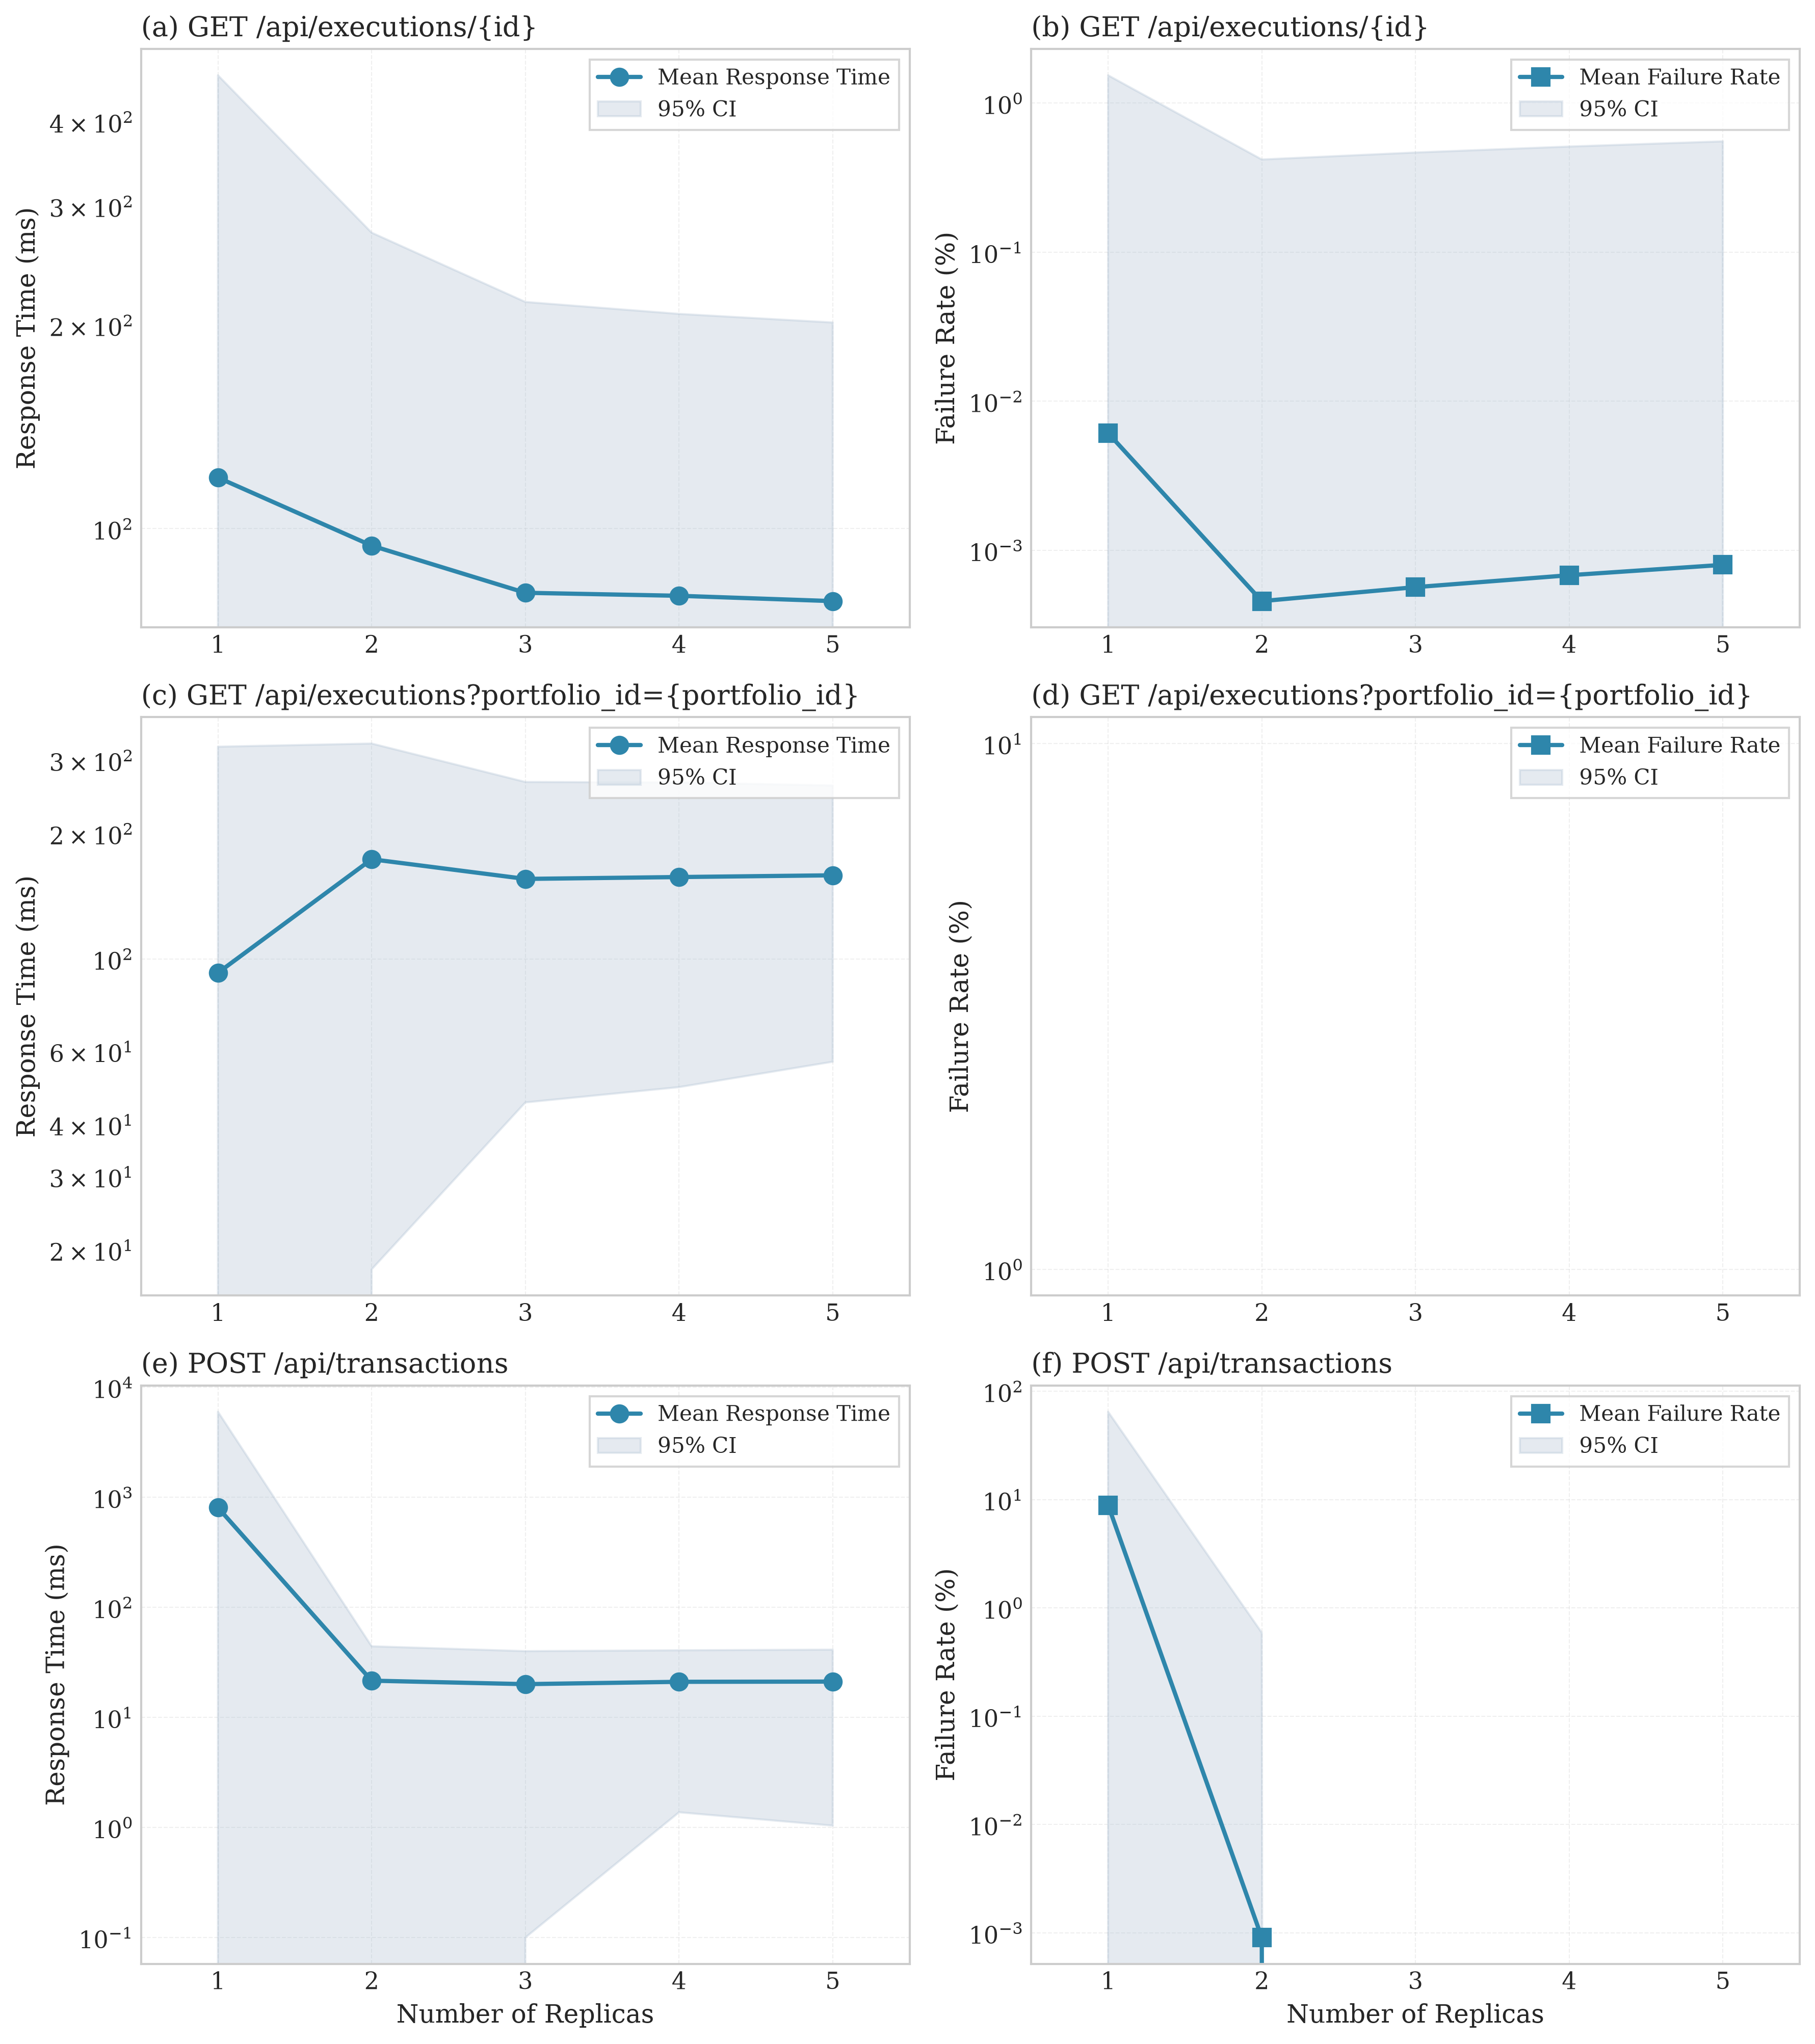

Saved: ../figures/experiment_1_replica_analysis_Execution.png


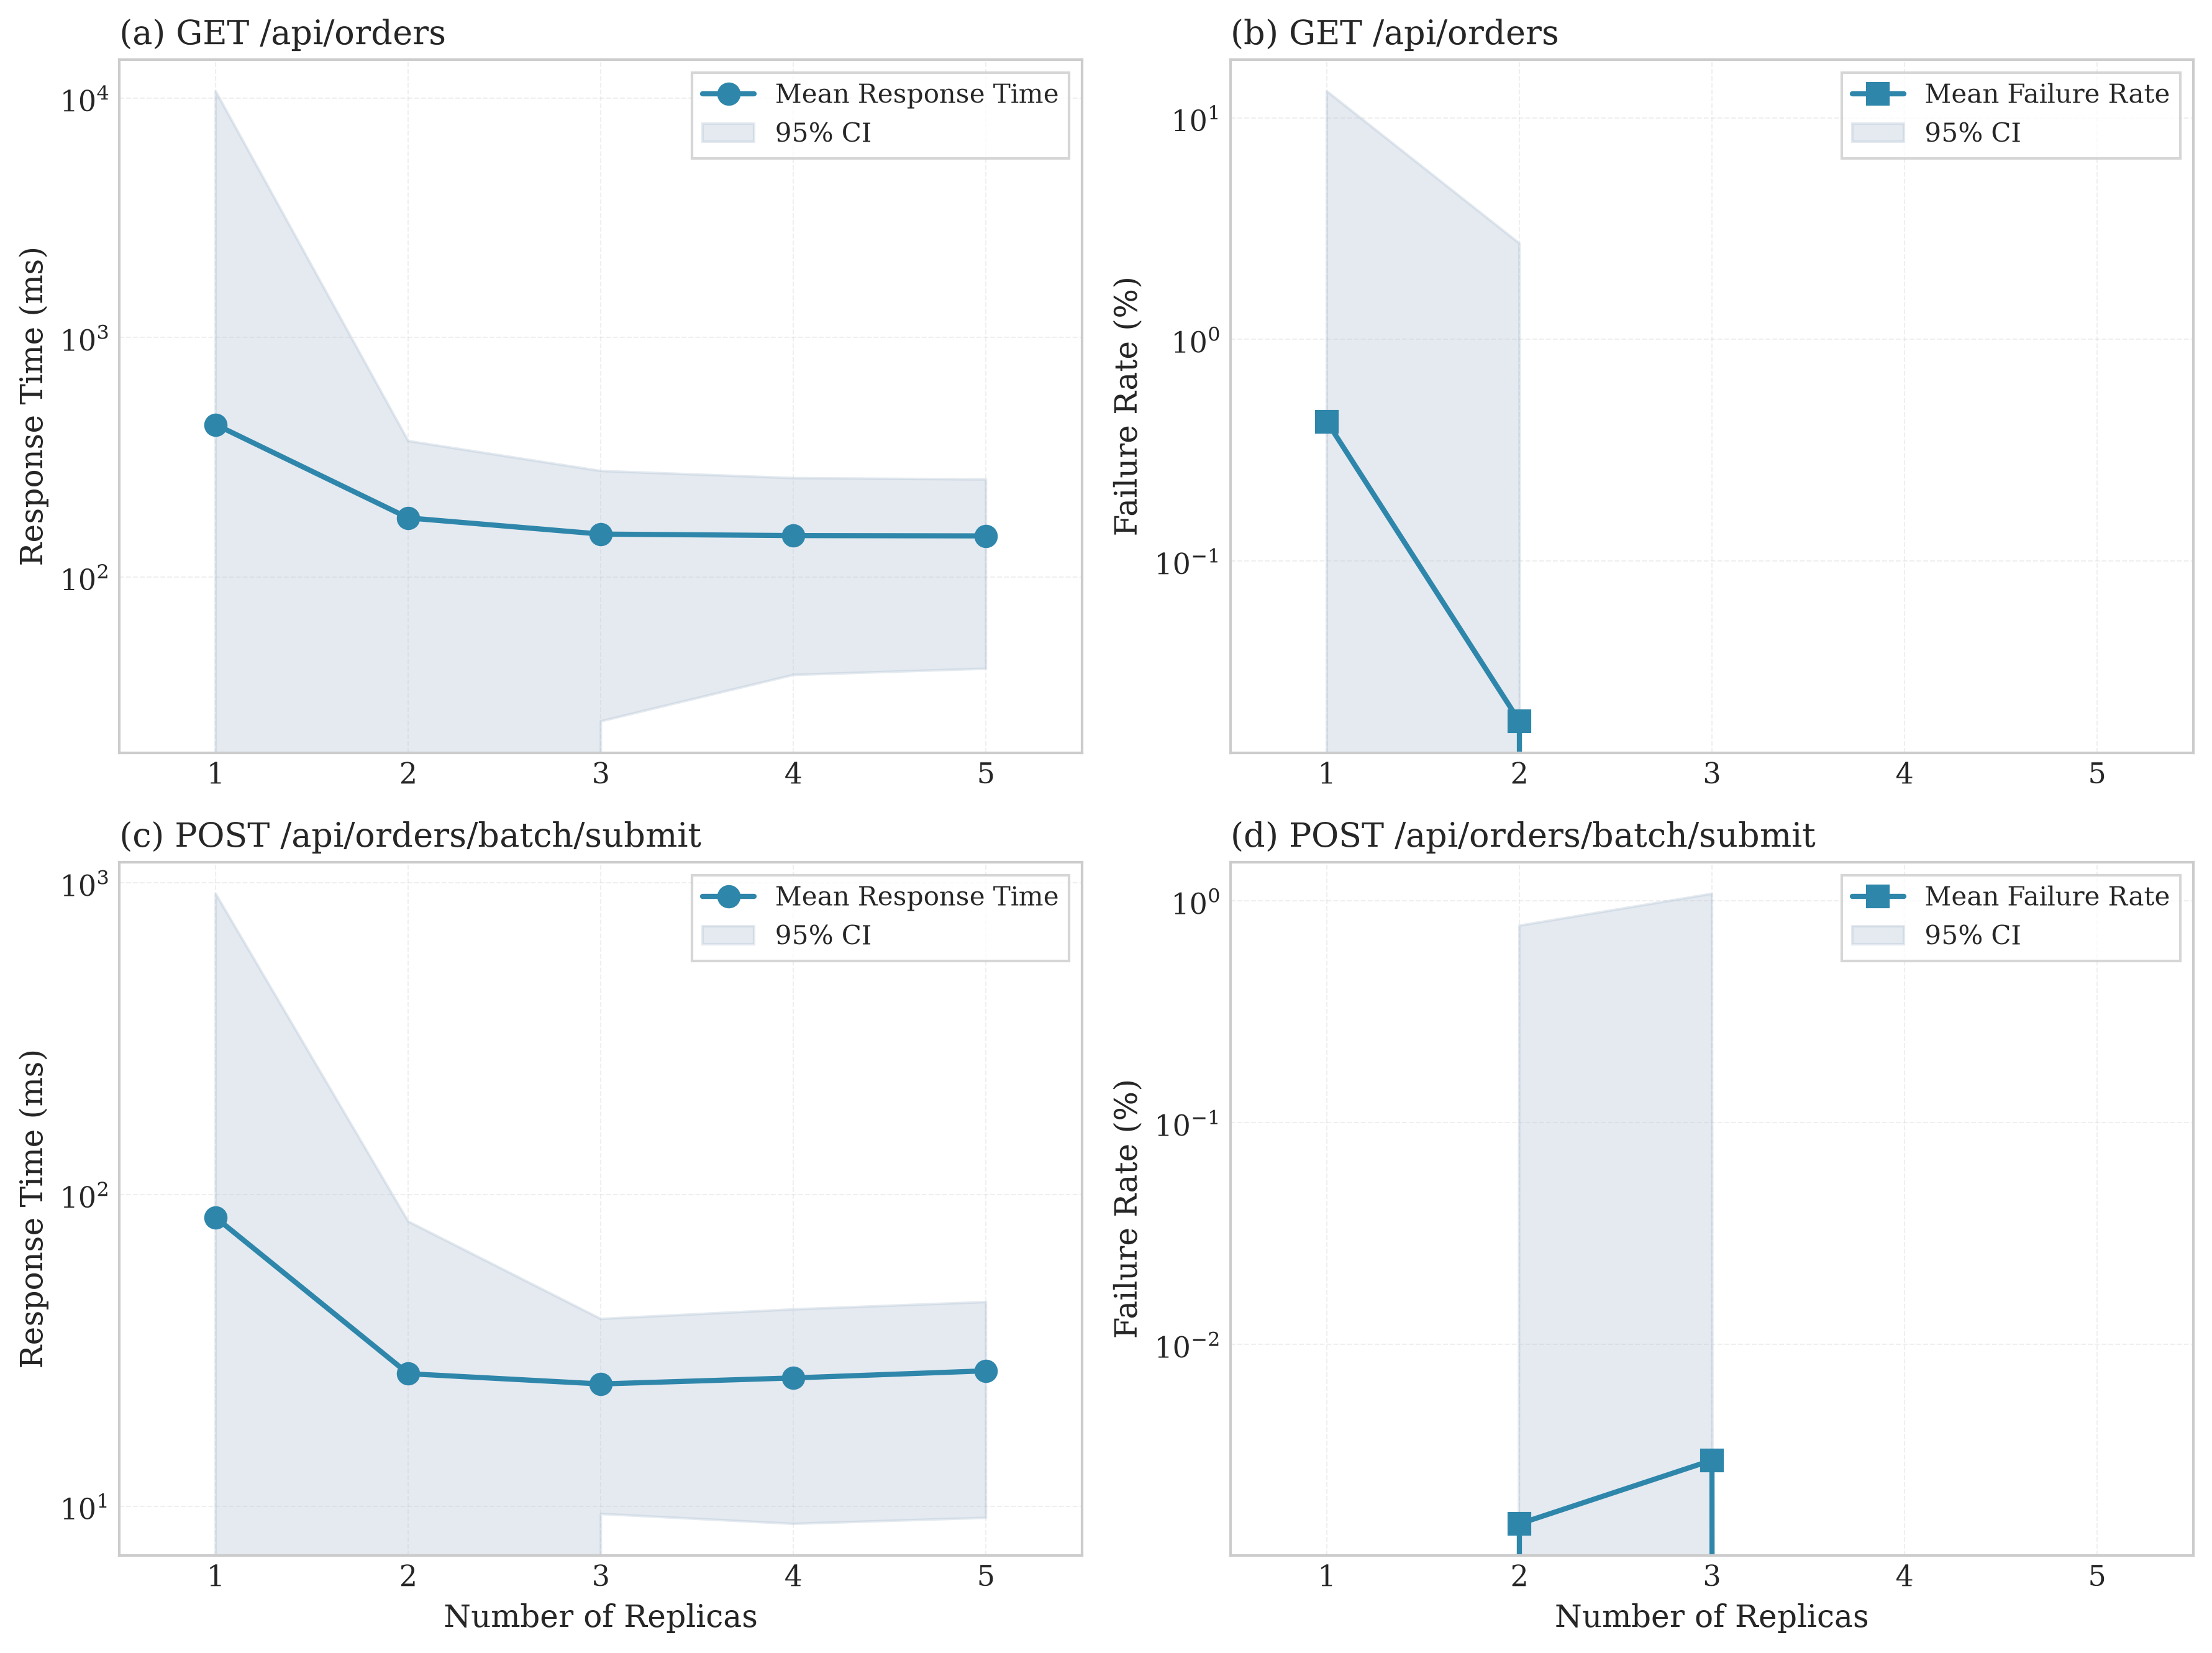

Saved: ../figures/experiment_1_replica_analysis_Order.png


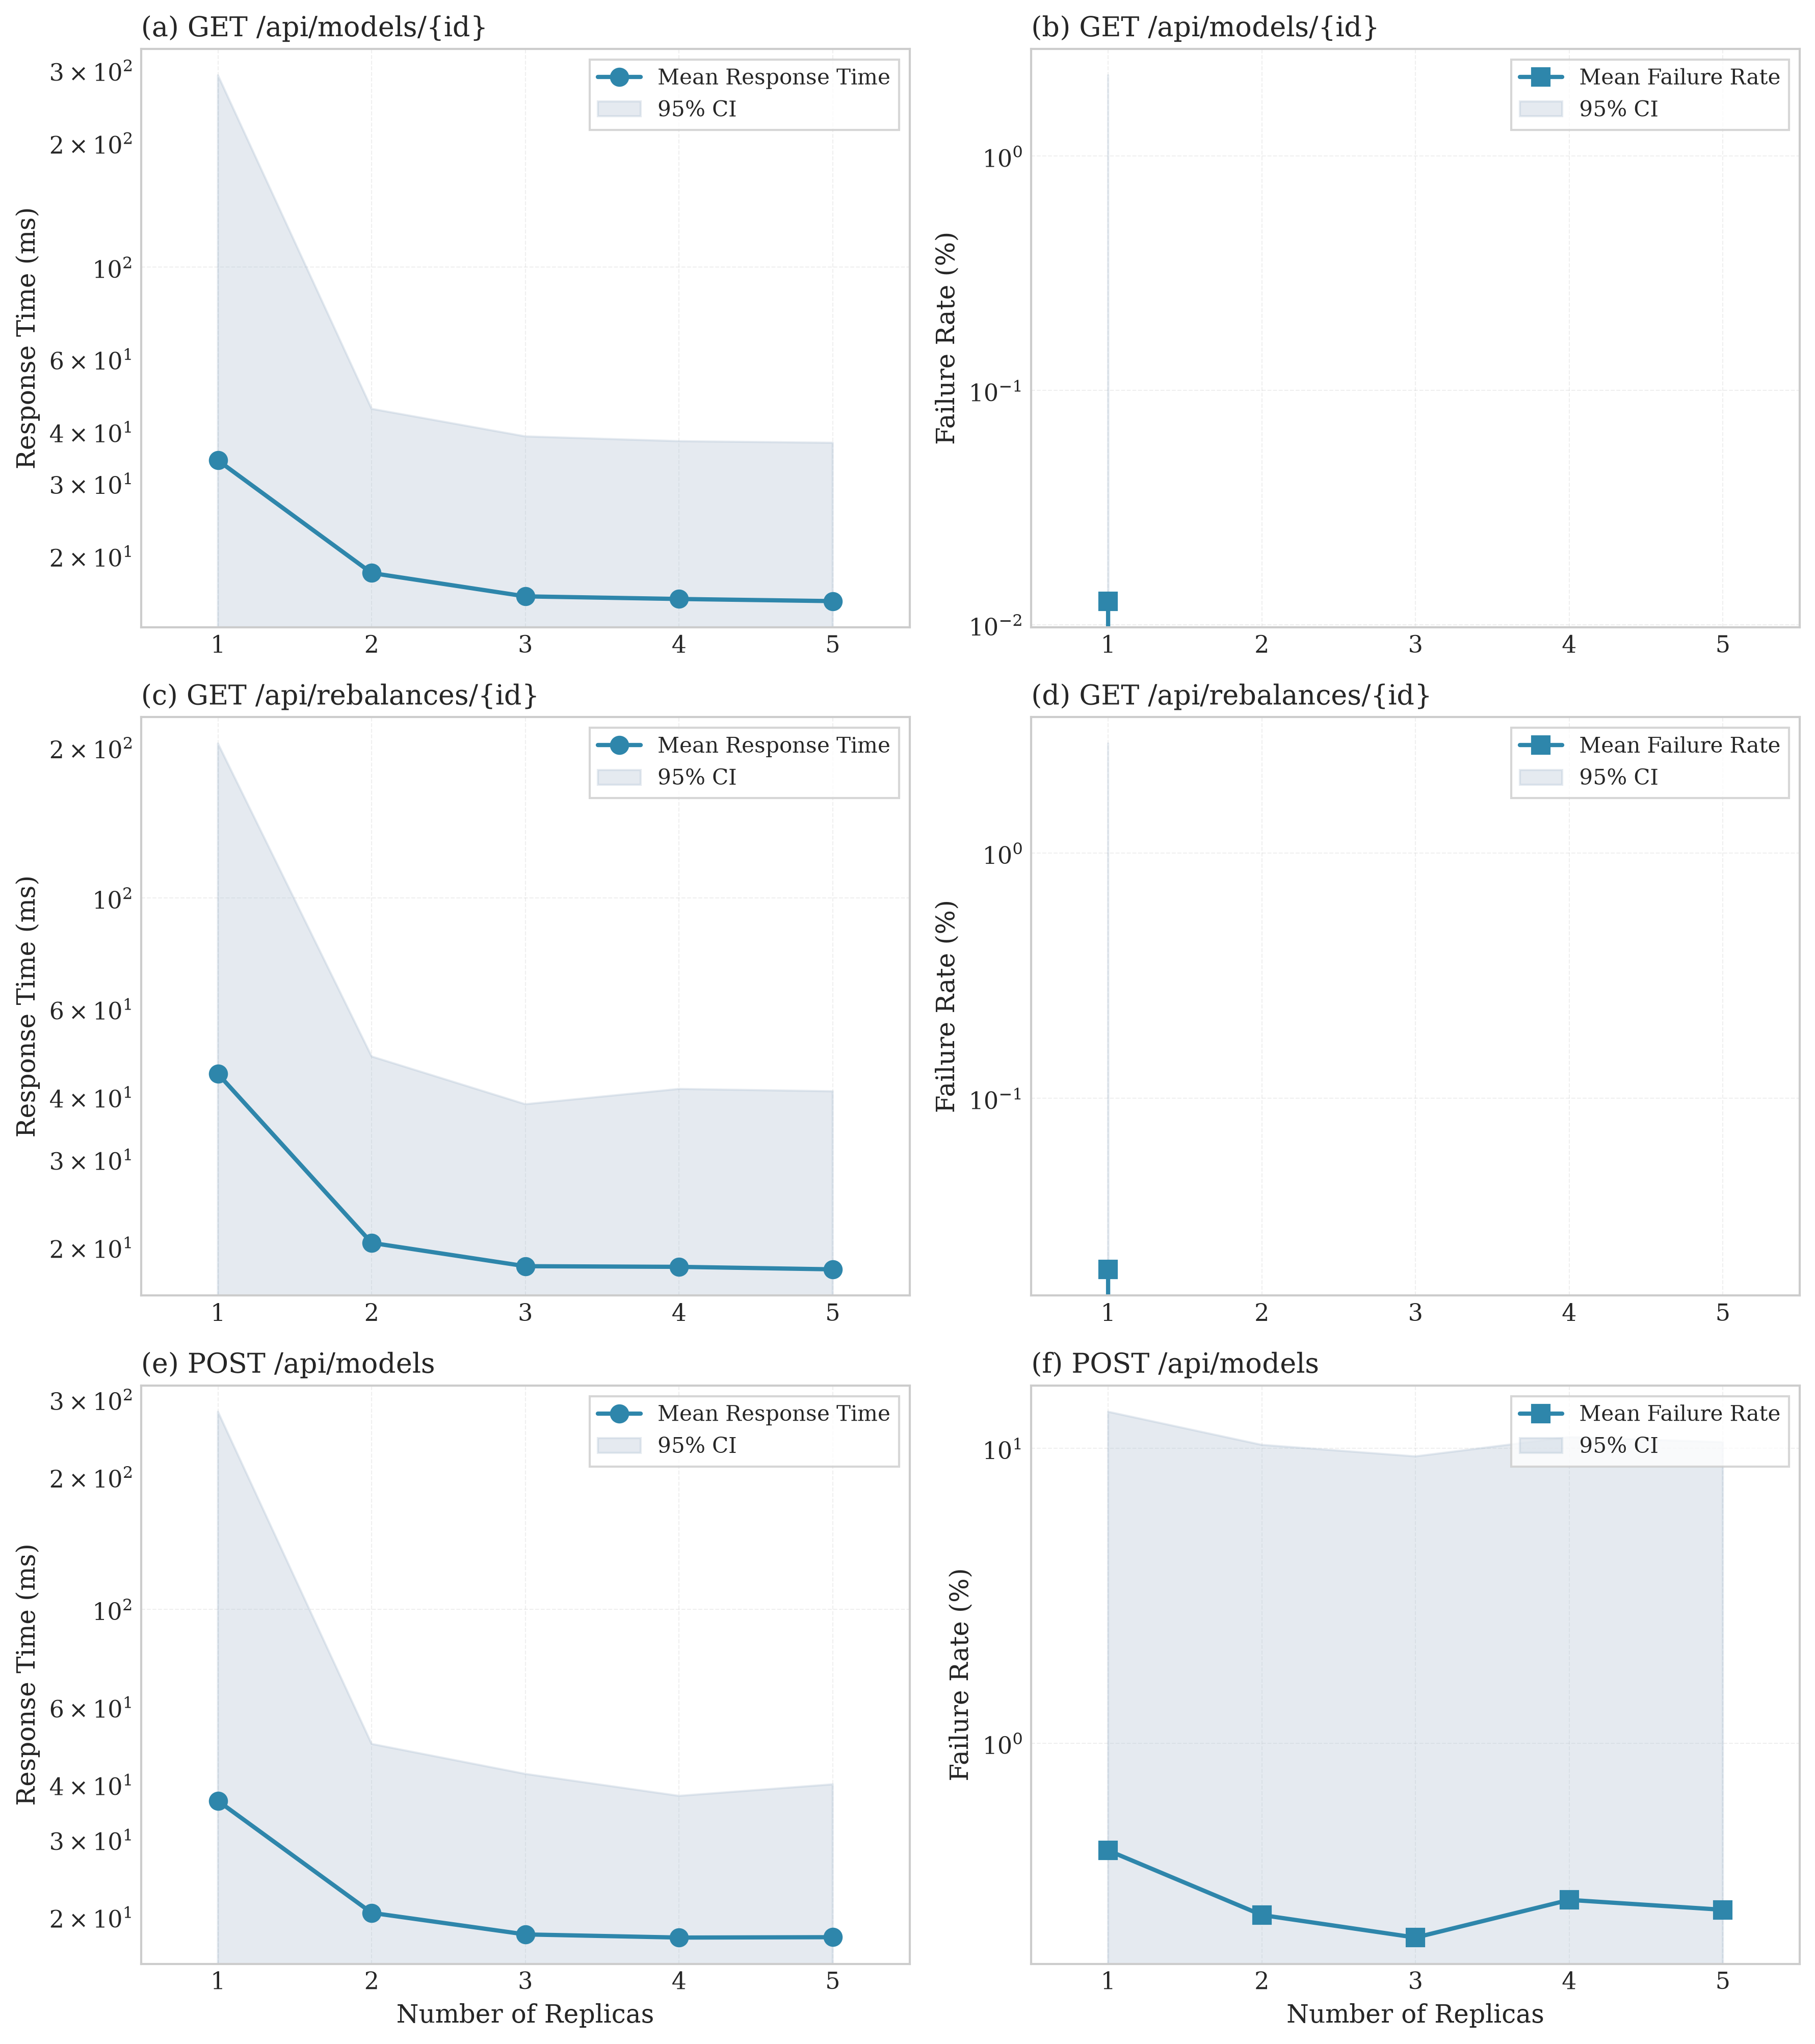

Saved: ../figures/experiment_1_replica_analysis_Order_Generation_part1.png


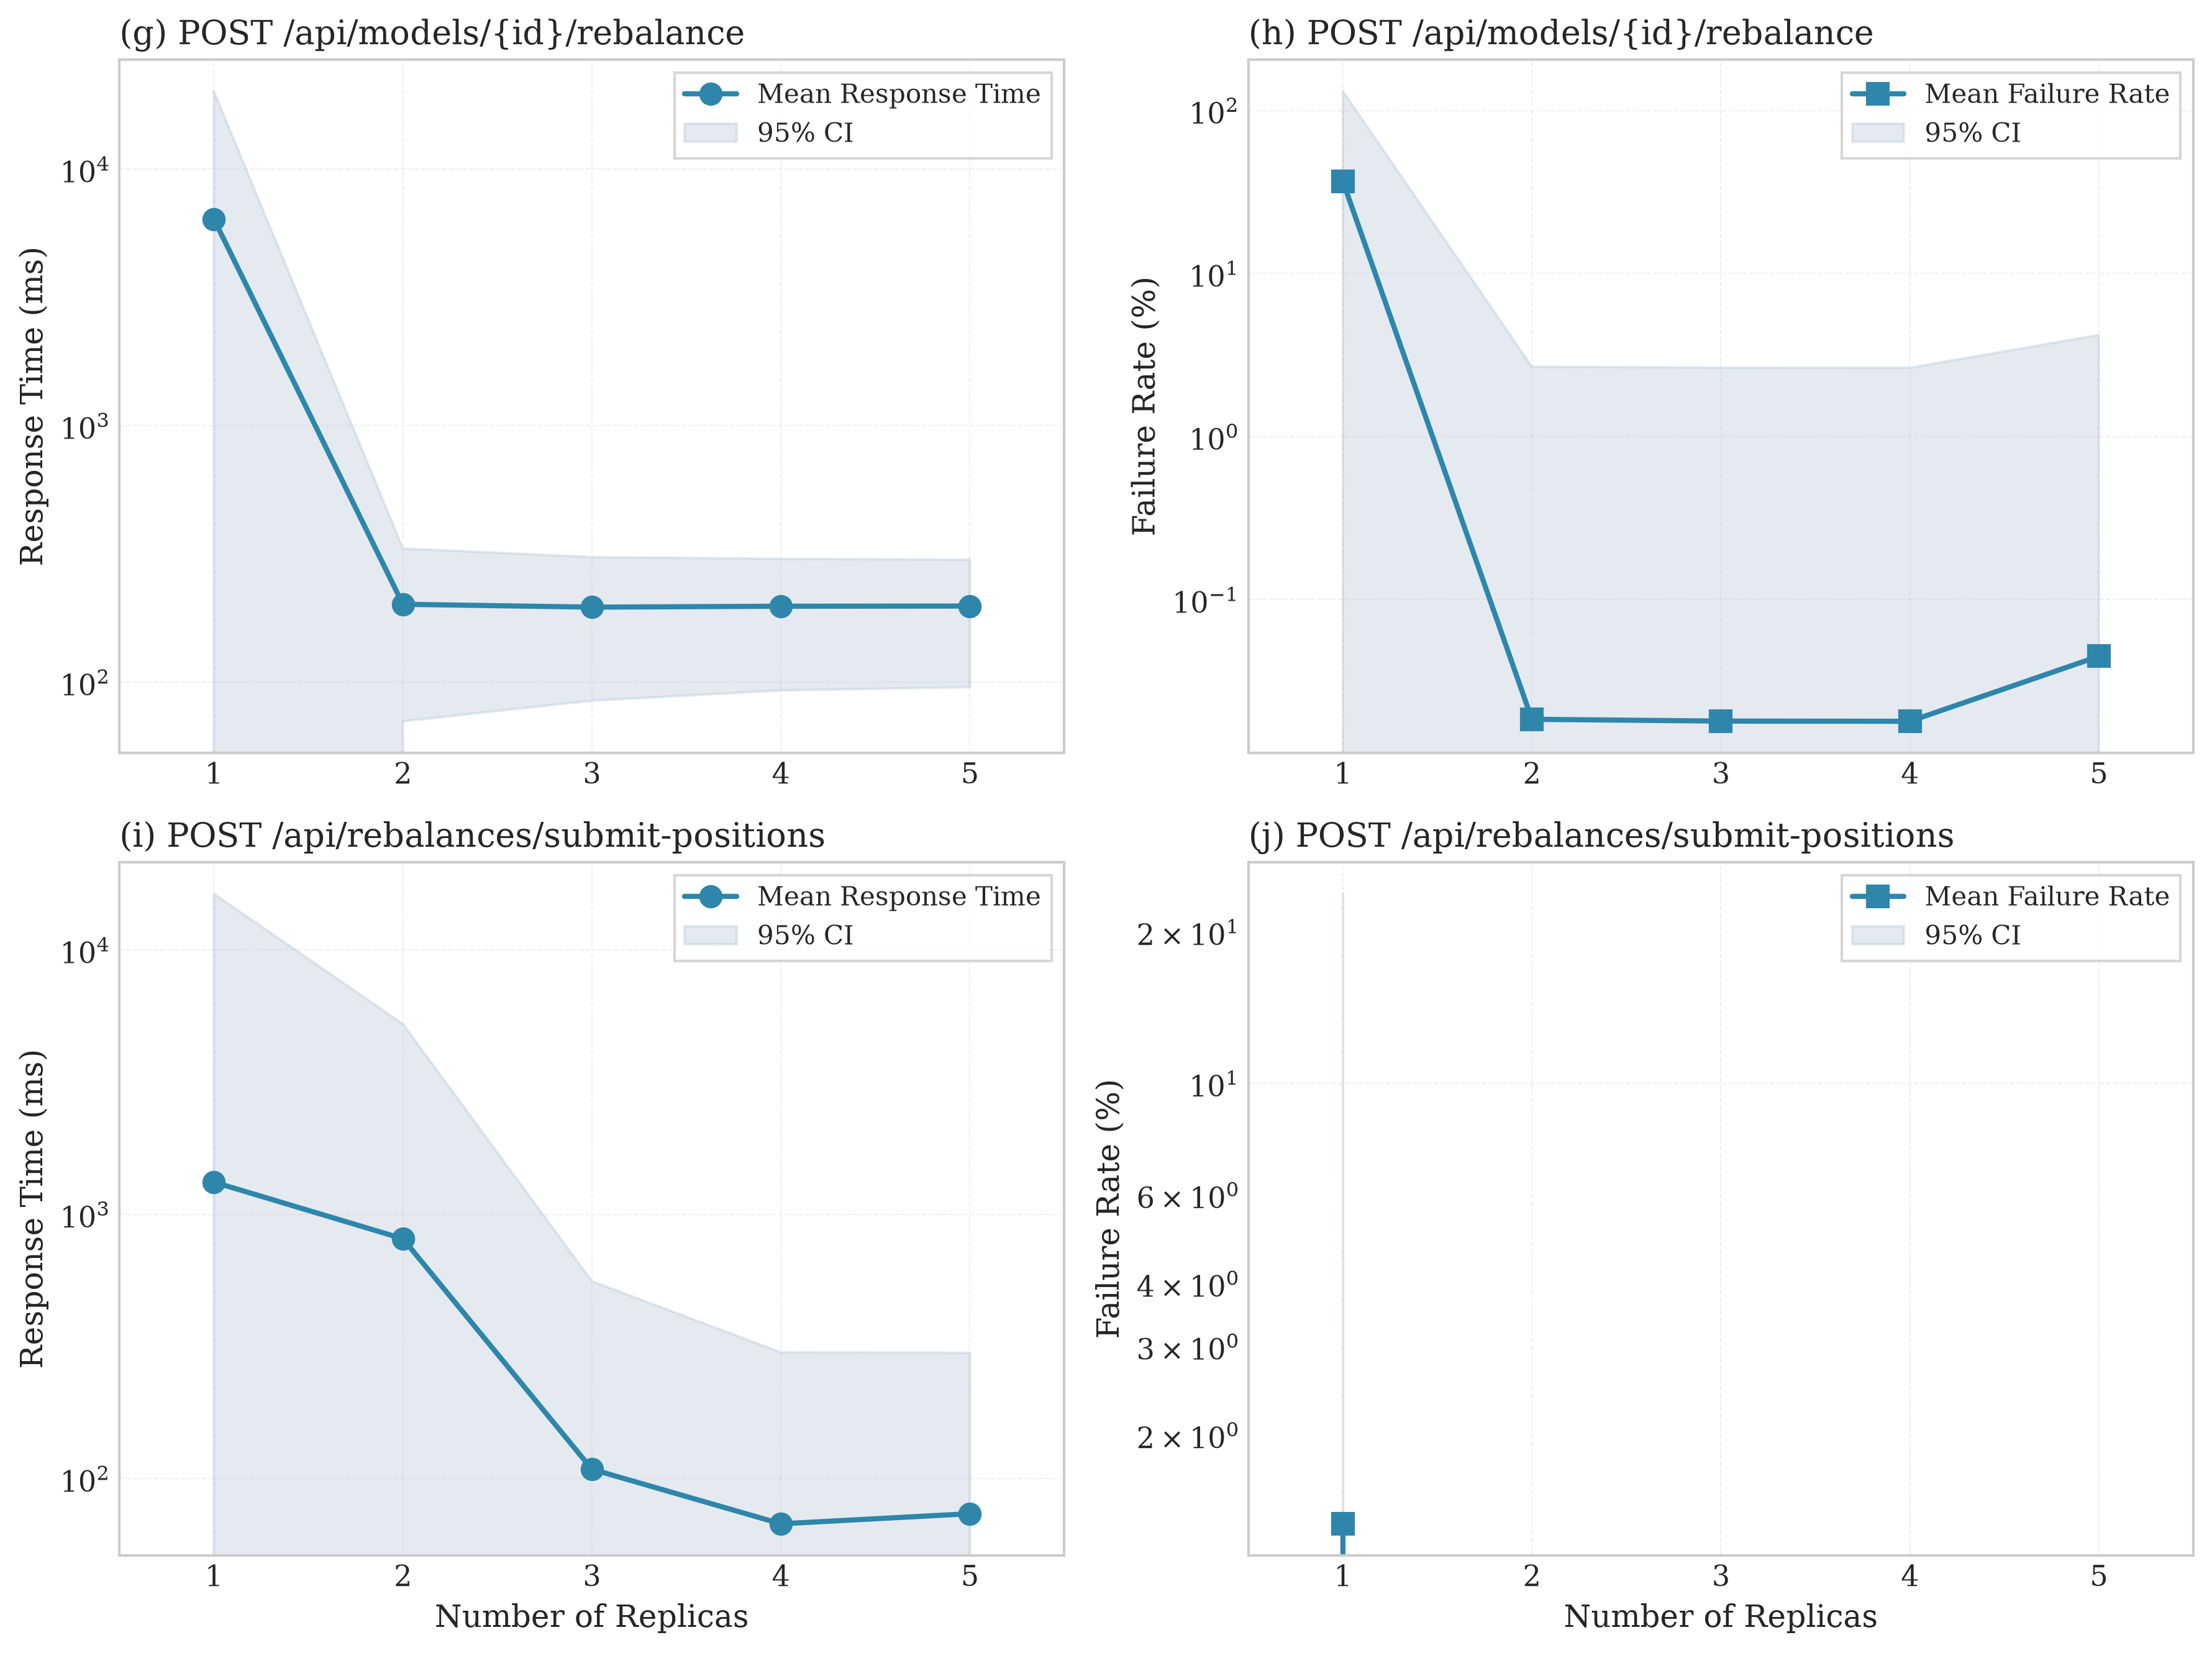

Saved: ../figures/experiment_1_replica_analysis_Order_Generation_part2.png


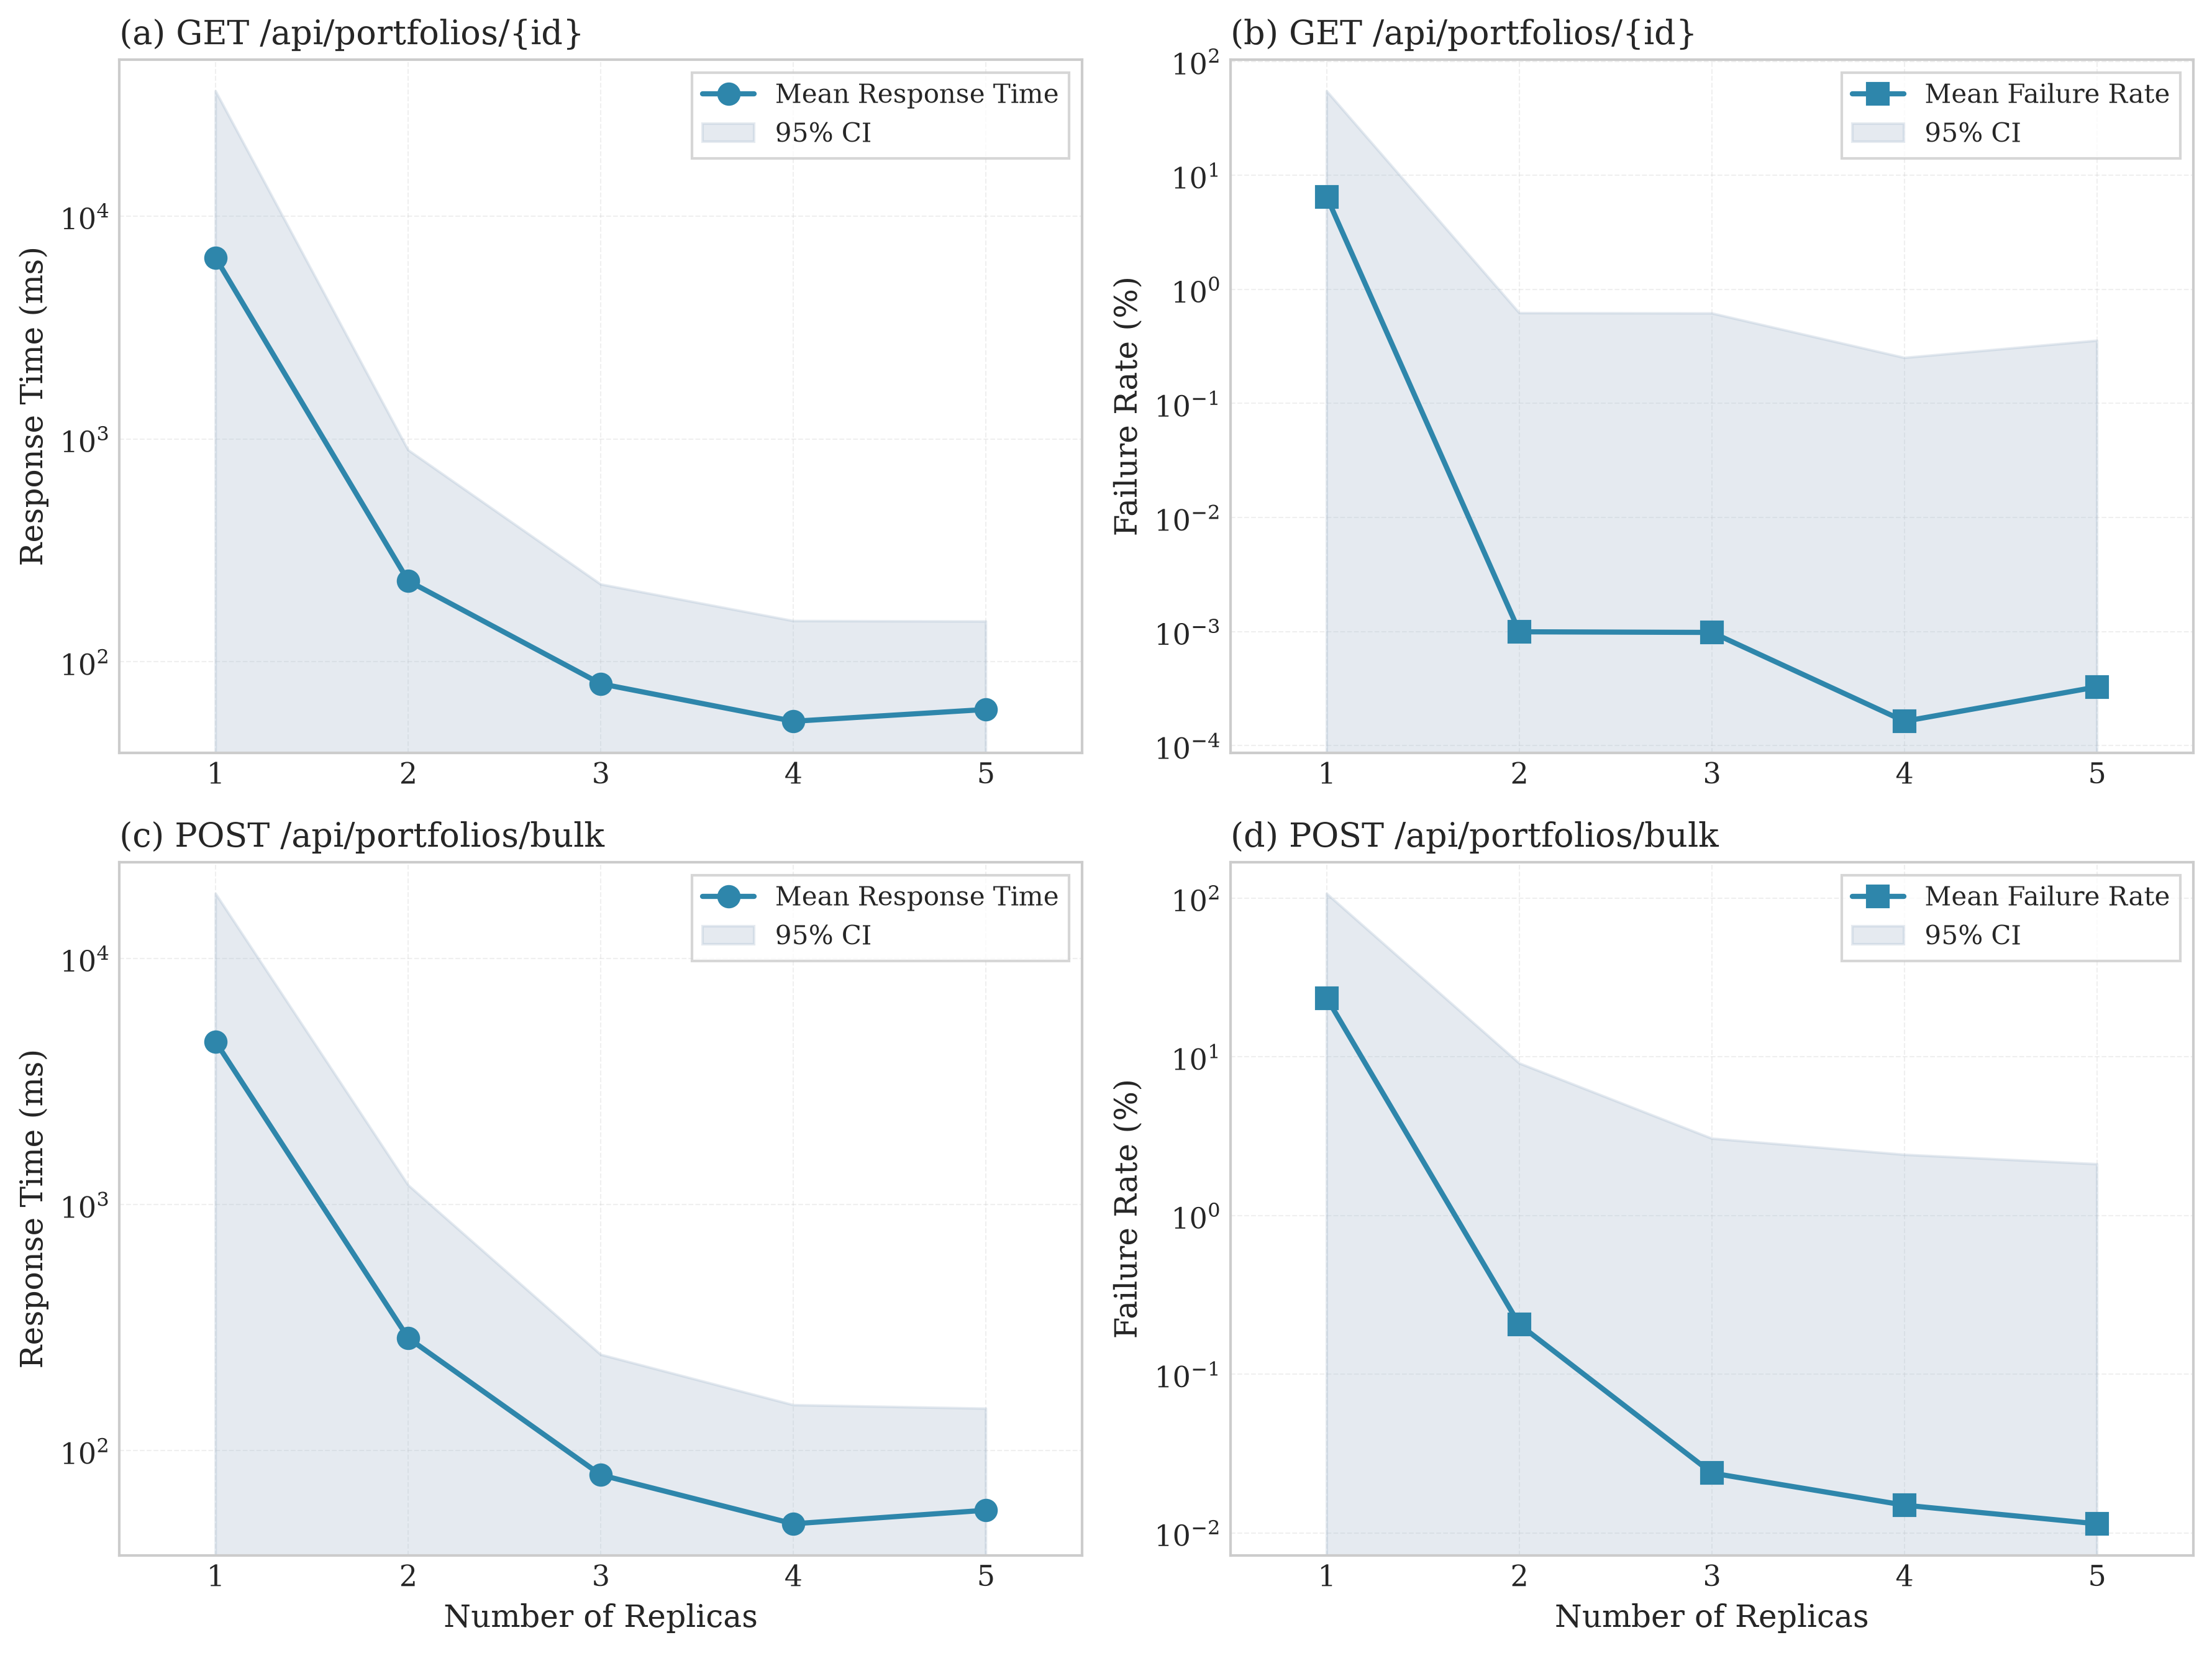

Saved: ../figures/experiment_1_replica_analysis_Portfolio.png


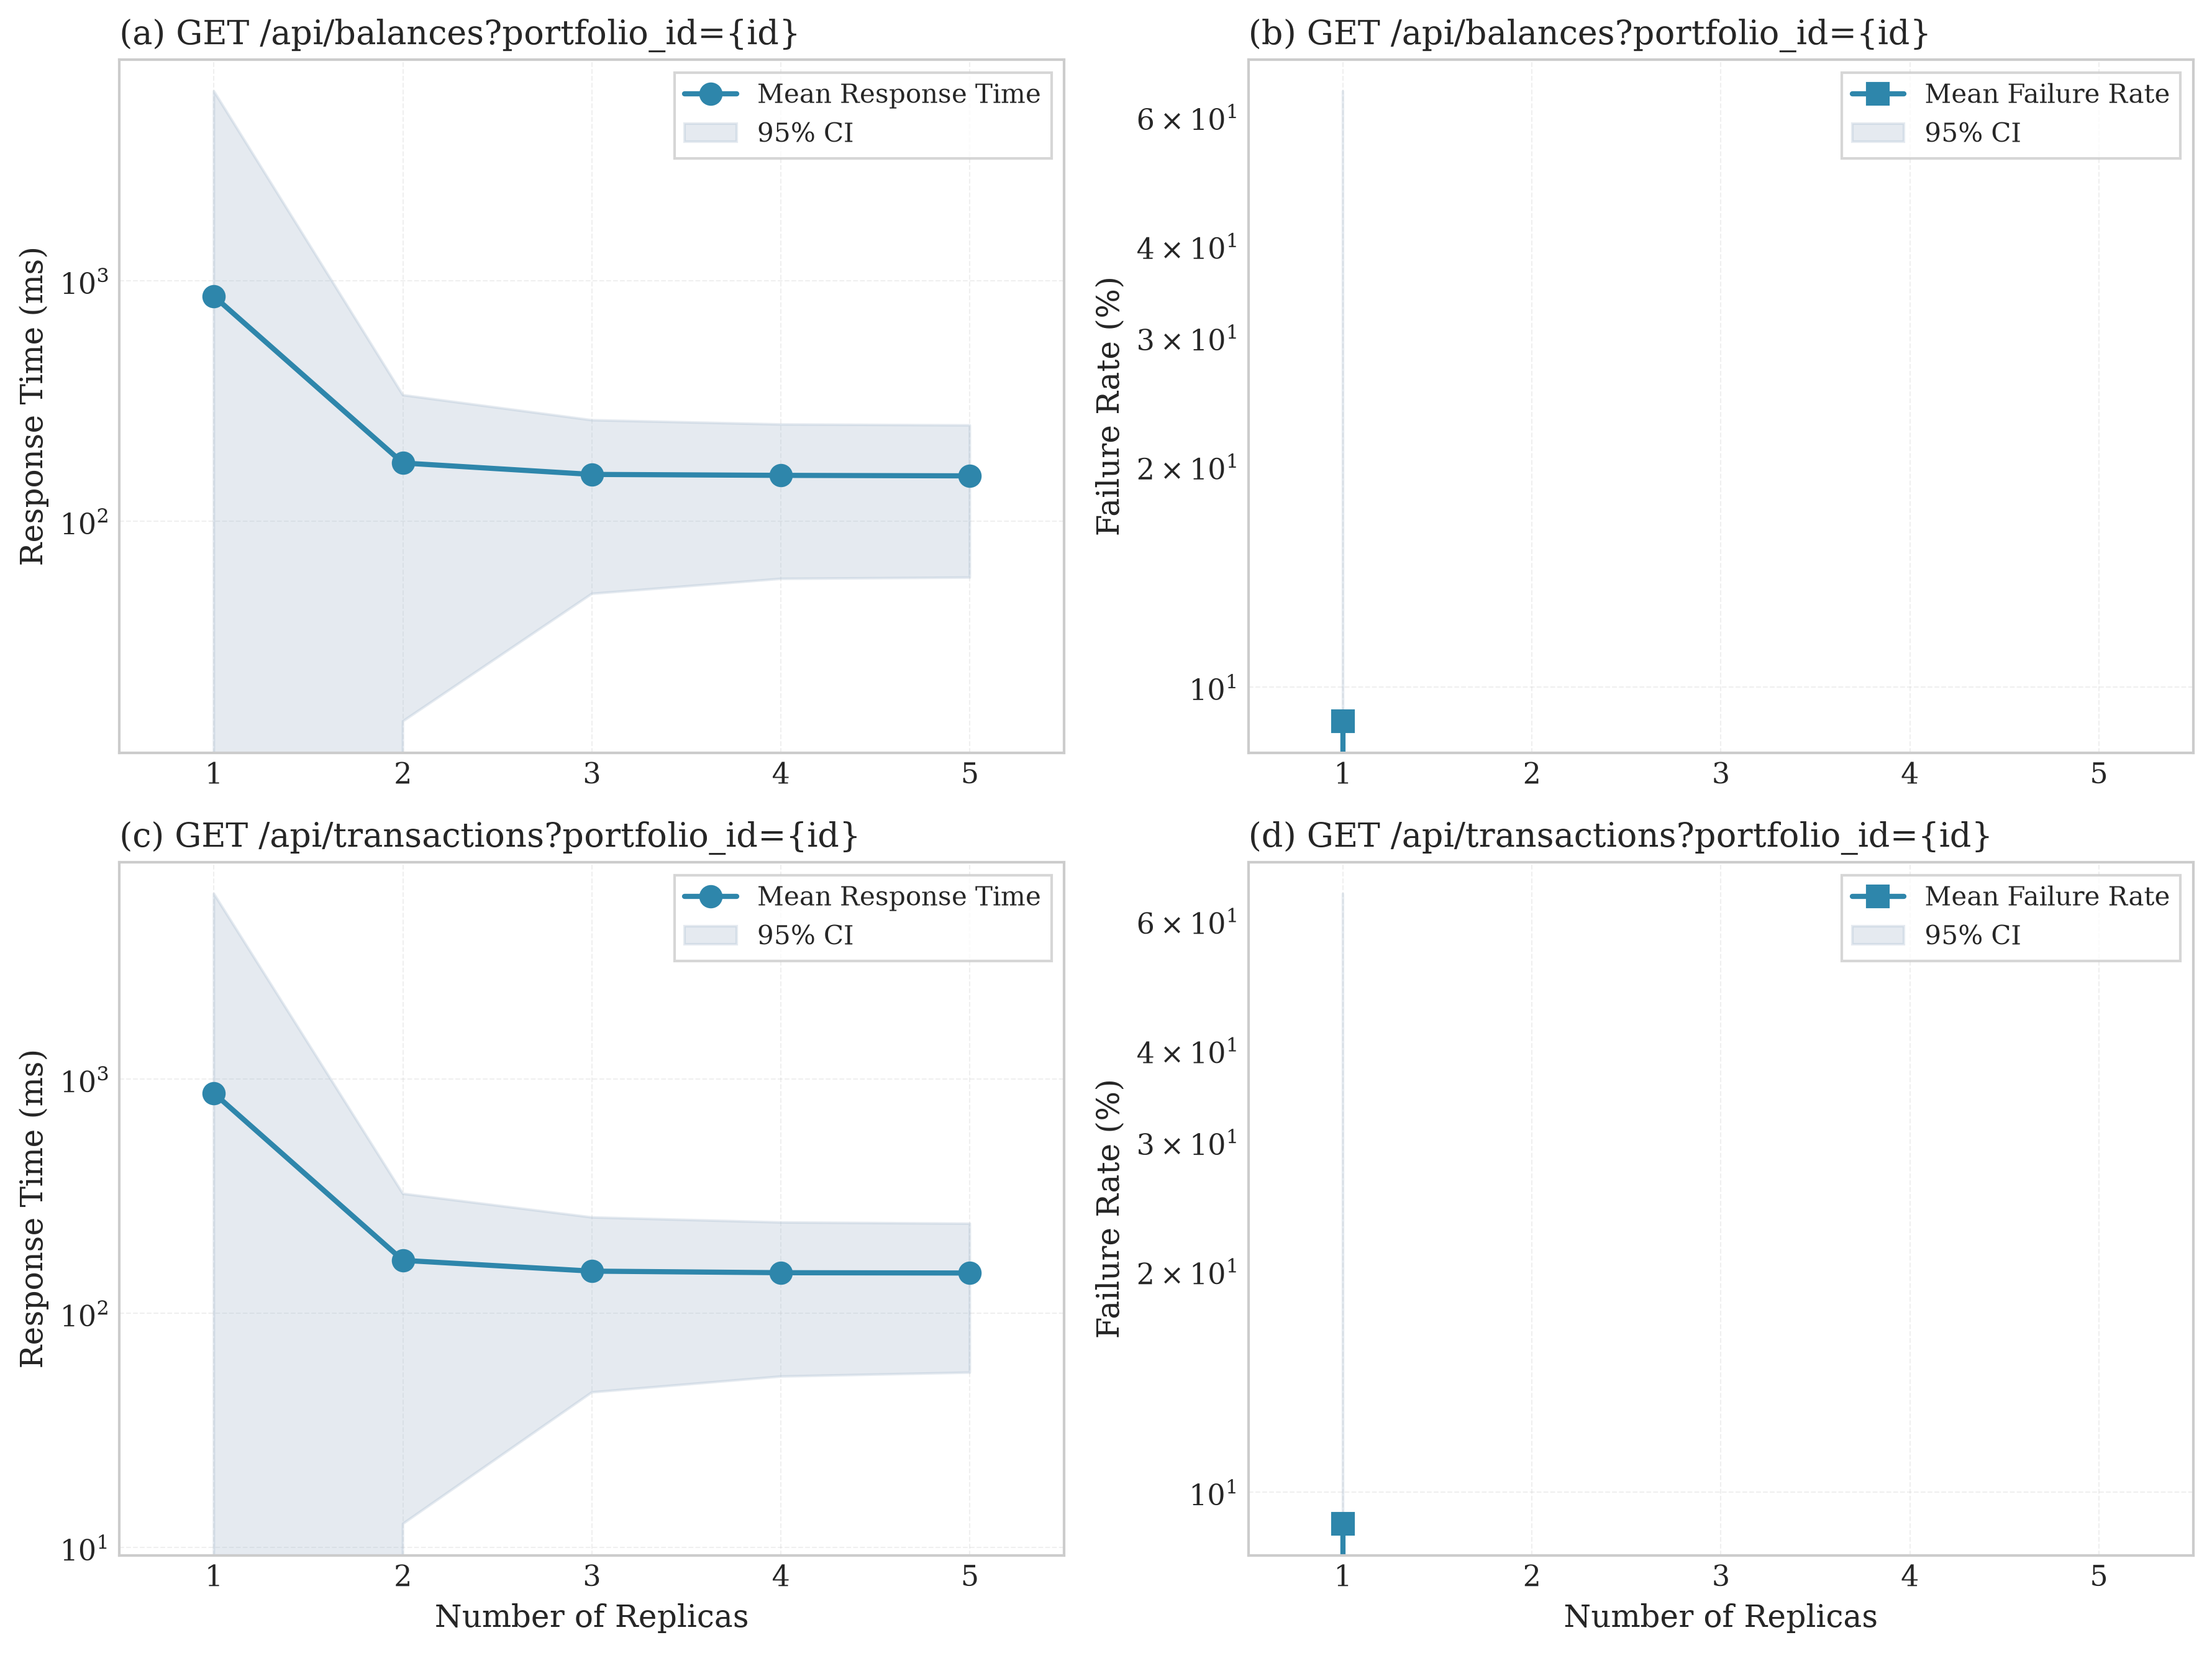

Saved: ../figures/experiment_1_replica_analysis_Portfolio_Accounting.png


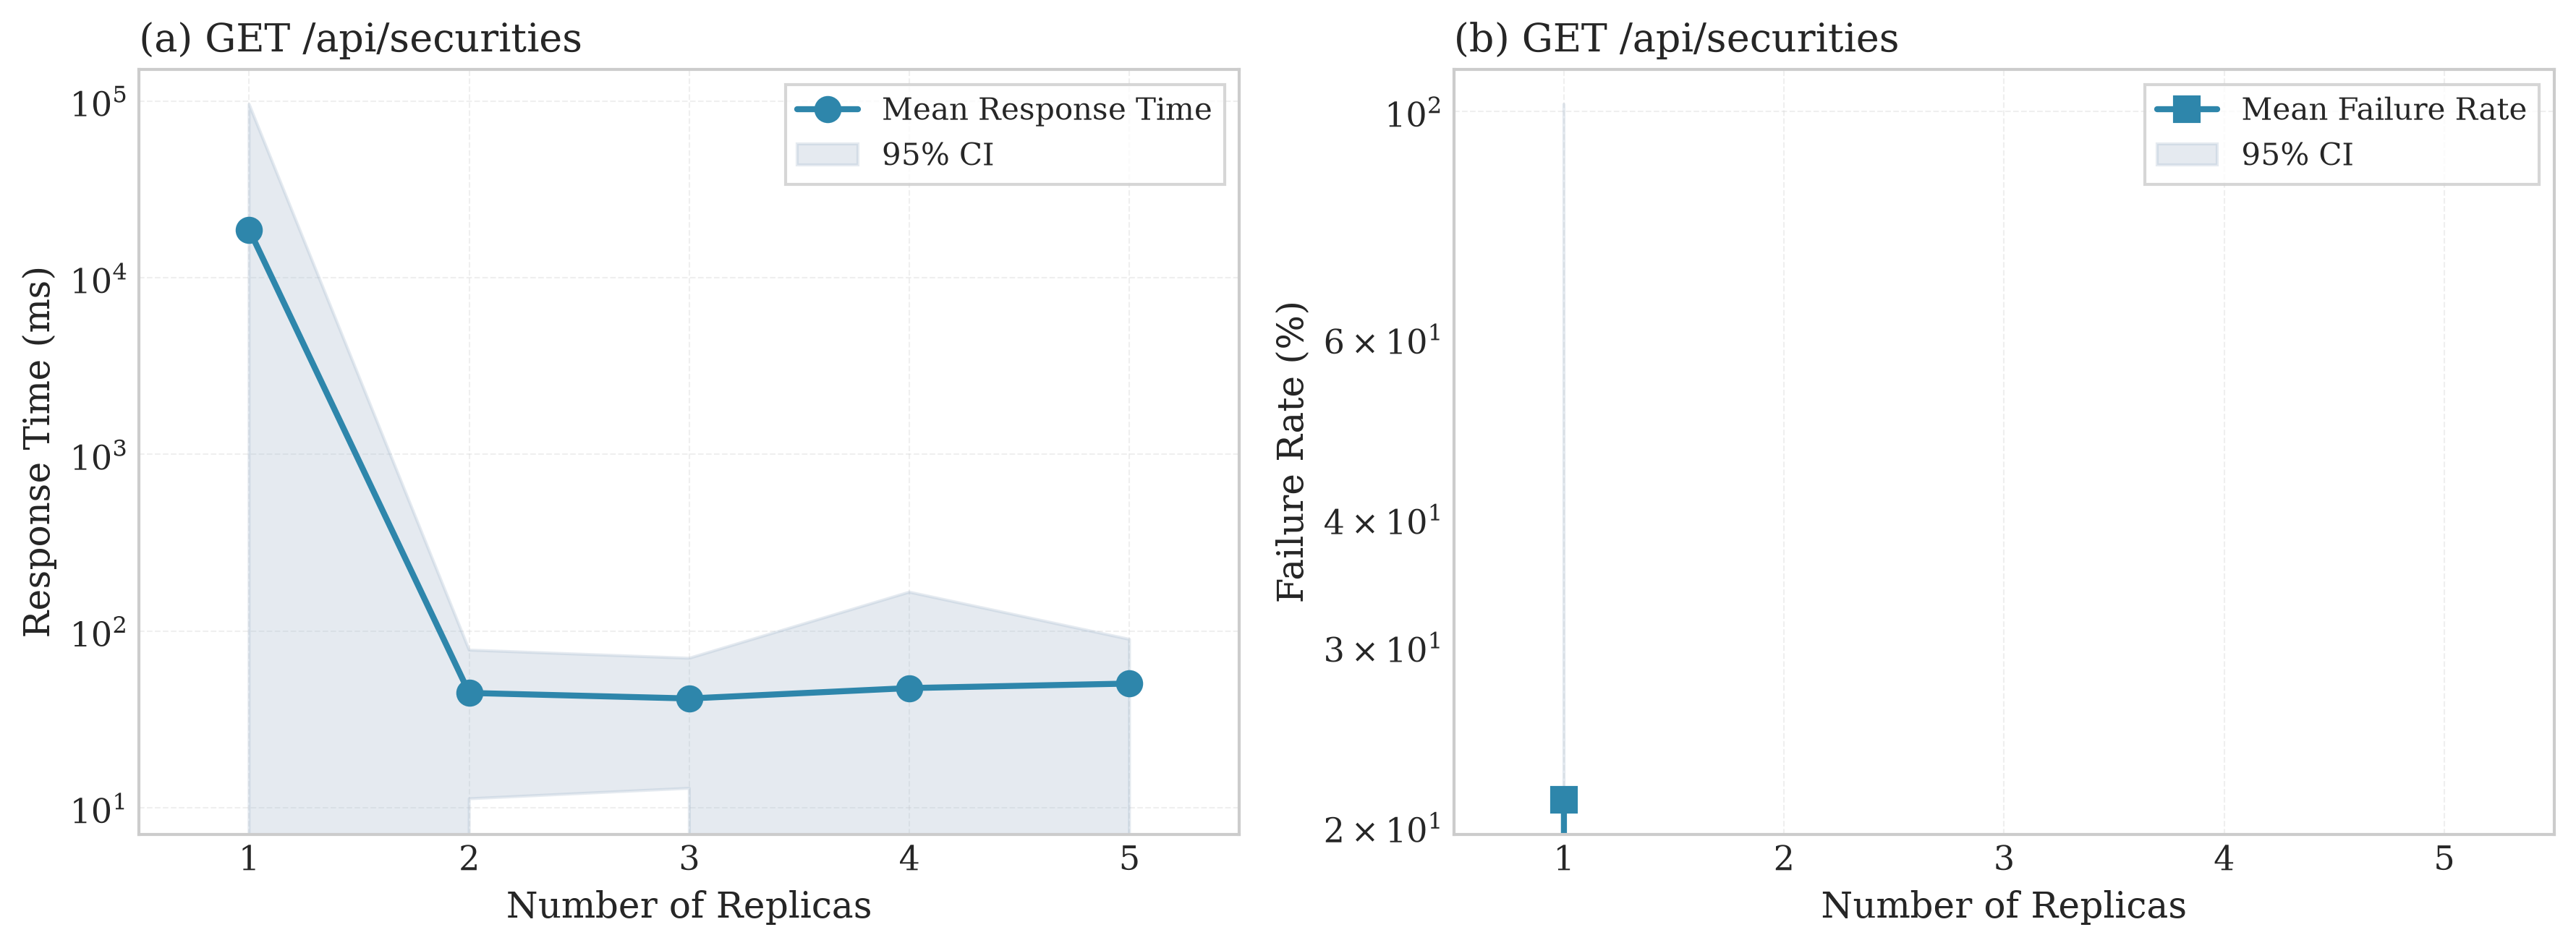

Saved: ../figures/experiment_1_replica_analysis_Security.png


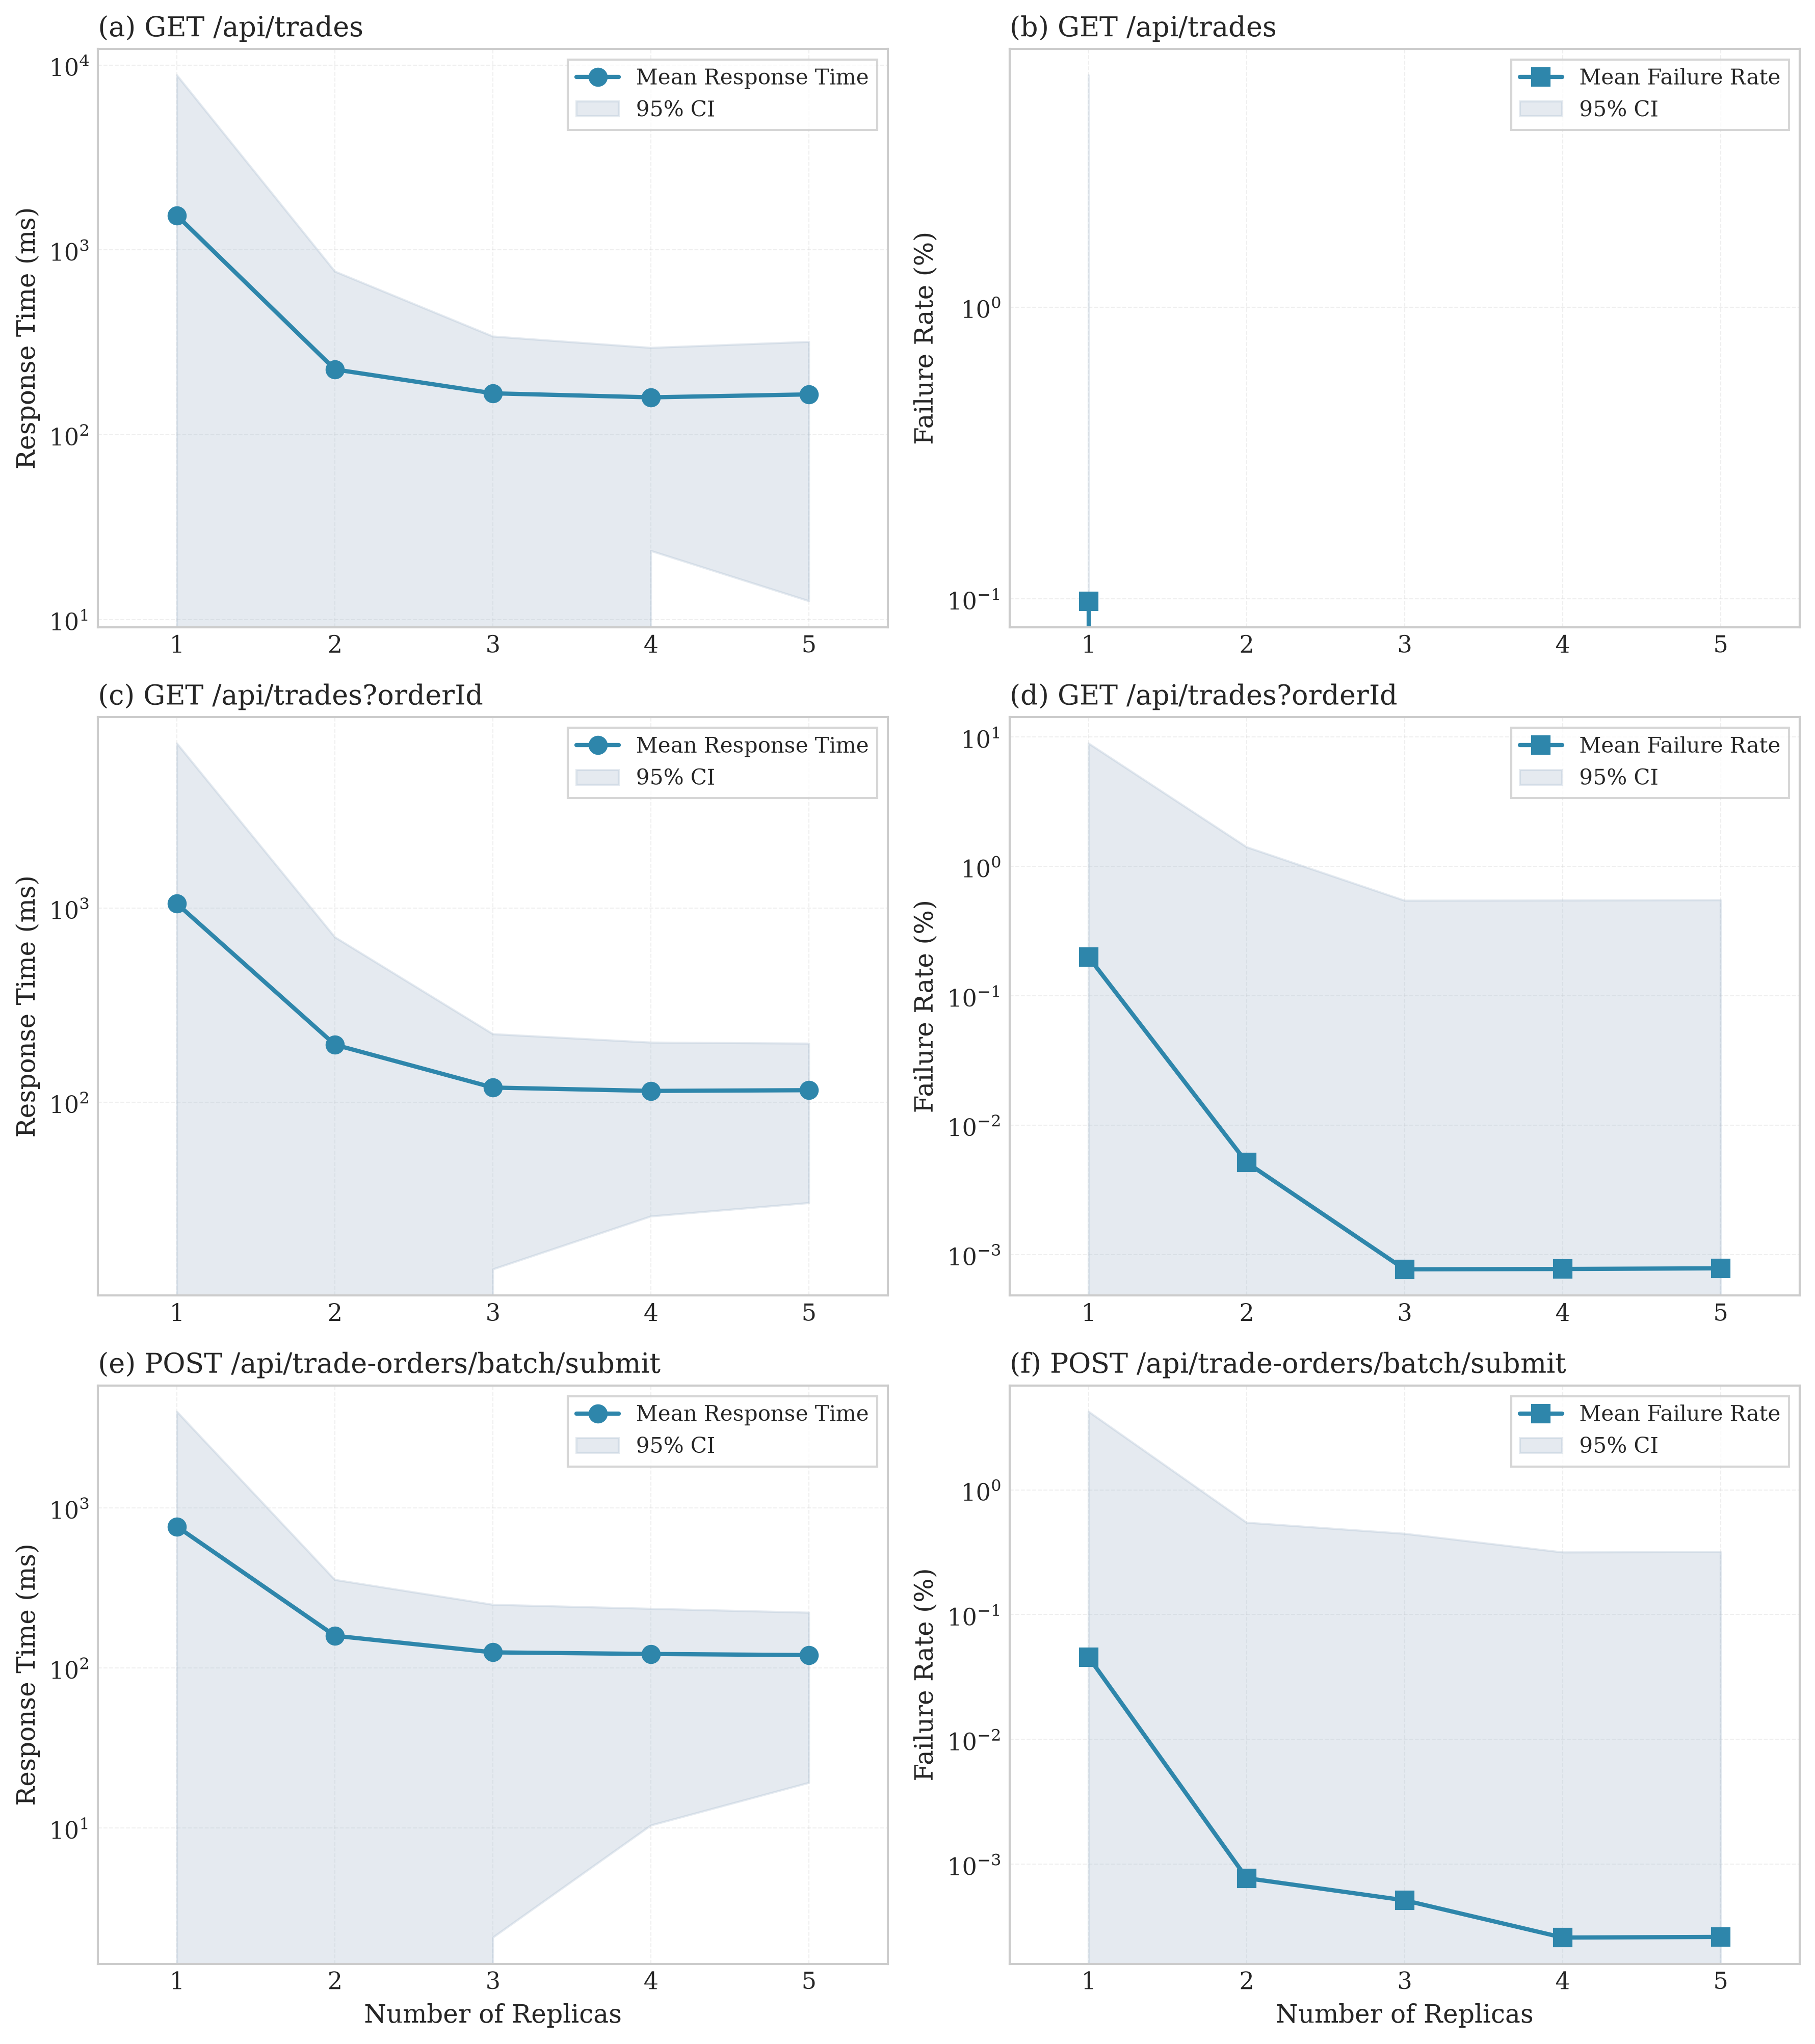

Saved: ../figures/experiment_1_replica_analysis_Trade.png

Summary Statistics (per microservice / name / replicas):

  Microservice: Execution

    API: GET /api/executions/{id}
      Response Time Range : 78.13 - 119.00 ms
      Failure Rate Range  : 0.0005 - 0.0061 %

    API: GET /api/executions?portfolio_id={portfolio_id}
      Response Time Range : 92.55 - 173.45 ms
      Failure Rate Range  : 0.0000 - 0.0000 %

    API: POST /api/transactions
      Response Time Range : 20.01 - 803.99 ms
      Failure Rate Range  : 0.0000 - 8.8760 %

  Microservice: Order

    API: GET /api/orders
      Response Time Range : 148.39 - 432.68 ms
      Failure Rate Range  : 0.0000 - 0.4262 %

    API: POST /api/orders/batch/submit
      Response Time Range : 24.67 - 84.34 ms
      Failure Rate Range  : 0.0000 - 0.0030 %

  Microservice: Order Generation

    API: GET /api/models/{id}
      Response Time Range : 15.53 - 34.03 ms
      Failure Rate Range  : 0.0000 - 0.0126 %

    API: GET /api/rebalan

In [216]:
df = agg_df.copy()
df.replicas = df.replicas.astype(int)
print(df.columns)
# ---------------------------------------------------------------------------
# Publication-quality rcParams (matching reference style)
# ---------------------------------------------------------------------------
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.dpi'] = 300

# Color scheme (reference)
color_primary = '#2E86AB'
color_ci       = '#A9BCD0'

# ---------------------------------------------------------------------------
# Derive CI half-widths from the std columns already in the dataframe.
# 95% CI half-width = 1.96 * std  (treating the reported std as the
# standard-error proxy produced by the load-test harness).
# ---------------------------------------------------------------------------
Z_95 = 1.96

# df['failure_rate']     = df['total_failures'] / df['total_requests']
df['response_time_ci'] = Z_95 * df['response_time_std']
df['failure_rate_ci']  = Z_95 * df['failure_rate_std']

# Work directly on the dataframe (one row per microservice/name/replicas).
agg = df[['microservice', 'name', 'replicas',
          'response_time_mean', 'response_time_ci',
          'failure_rate',      'failure_rate_ci']].copy()
agg.rename(columns={'failure_rate':      'failure_rate_mean'}, inplace=True)

# ---------------------------------------------------------------------------
# One figure per microservice (split into multiple figures if > 3 APIs)
# ---------------------------------------------------------------------------
panel_labels = 'abcdefghijklmnopqrstuvwxyz'
MAX_ROWS_PER_FIGURE = 3  # Maximum number of API rows per figure

for microservice, ms_data in agg.groupby('microservice'):
    names  = sorted(ms_data['name'].unique())
    total_apis = len(names)
    
    # Calculate how many figures we need
    num_figures = (total_apis + MAX_ROWS_PER_FIGURE - 1) // MAX_ROWS_PER_FIGURE
    
    panel_idx = 0  # running index for (a), (b), ... labels across all figures
    
    # Split the APIs into chunks
    for fig_num in range(num_figures):
        start_idx = fig_num * MAX_ROWS_PER_FIGURE
        end_idx = min(start_idx + MAX_ROWS_PER_FIGURE, total_apis)
        names_chunk = names[start_idx:end_idx]
        
        n_rows = len(names_chunk)  # one row per API name in this chunk
        n_cols = 2                  # left = response time, right = failure rate

        fig, axes = plt.subplots(
            n_rows, n_cols,
            figsize=(12, 4.5 * n_rows),
            squeeze=False          # always 2-D array even for 1 row
        )
        fig.subplots_adjust(hspace=0.38, wspace=0.30)

        for row, name in enumerate(names_chunk):
            nd       = ms_data[ms_data['name'] == name].sort_values('replicas')
            replicas = nd['replicas'].values

            # ----------------------------------------------------------------
            # LEFT - Response Time
            # ----------------------------------------------------------------
            ax = axes[row, 0]
            rt_mean = nd['response_time_mean'].values
            rt_ci   = nd['response_time_ci'].values

            ax.plot(replicas, rt_mean,
                    marker='o', linewidth=2, markersize=8,
                    color=color_primary, label='Mean Response Time')
            ax.fill_between(replicas,
                            rt_mean - rt_ci,
                            rt_mean + rt_ci,
                            alpha=0.3, color=color_ci, label='95% CI')

            ax.set_ylabel('Response Time (ms)', fontweight='normal')

            ax.set_yscale('log')


            ax.set_title(f'({panel_labels[panel_idx]}) {name}',
                         loc='left', fontweight='normal')
            ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
            ax.set_xticks(replicas)
            ax.set_xlim(replicas.min() - 0.5, replicas.max() + 0.5)
            ax.legend(loc='upper right', frameon=True, shadow=False, fancybox=False)

            if row == n_rows - 1:
                ax.set_xlabel('Number of Replicas', fontweight='normal')
            else:
                ax.set_xlabel('')

            panel_idx += 1

            # ----------------------------------------------------------------
            # RIGHT - Failure Rate
            # ----------------------------------------------------------------
            ax        = axes[row, 1]
            fr_pct    = nd['failure_rate_mean'].values * 100
            fr_ci_pct = nd['failure_rate_ci'].values   * 100

            ax.plot(replicas, fr_pct,
                    marker='s', linewidth=2, markersize=8,
                    color=color_primary, label='Mean Failure Rate')
            ax.fill_between(replicas,
                            fr_pct - fr_ci_pct,
                            fr_pct + fr_ci_pct,
                            alpha=0.3, color=color_ci, label='95% CI')

            ax.set_ylabel('Failure Rate (%)', fontweight='normal')

            ax.set_yscale('log')

            ax.set_title(f'({panel_labels[panel_idx]}) {name}',
                         loc='left', fontweight='normal')
            ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
            ax.set_xticks(replicas)
            ax.set_xlim(replicas.min() - 0.5, replicas.max() + 0.5)
            ax.legend(loc='upper right', frameon=True, shadow=False, fancybox=False)

            if row == n_rows - 1:
                ax.set_xlabel('Number of Replicas', fontweight='normal')
            else:
                ax.set_xlabel('')

            panel_idx += 1

        plt.tight_layout()
        safe_name = microservice.replace(' ', '_').replace('/', '_')
        
        # Add figure number suffix if multiple figures for this microservice
        if num_figures > 1:
            filename = f'../figures/experiment_1_replica_analysis_{safe_name}_part{fig_num + 1}.png'
        else:
            filename = f'../figures/experiment_1_replica_analysis_{safe_name}.png'
            
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        plt.show()
        print(f"Saved: {filename}")

# ---------------------------------------------------------------------------
# Summary statistics
# ---------------------------------------------------------------------------
print("\nSummary Statistics (per microservice / name / replicas):")
for microservice in sorted(agg['microservice'].unique()):
    print(f"\n  Microservice: {microservice}")
    for name in sorted(agg[agg['microservice'] == microservice]['name'].unique()):
        nd = agg[(agg['microservice'] == microservice) & (agg['name'] == name)]
        print(f"\n    API: {name}")
        print(f"      Response Time Range : "
              f"{nd['response_time_mean'].min():.2f} - "
              f"{nd['response_time_mean'].max():.2f} ms")
        print(f"      Failure Rate Range  : "
              f"{nd['failure_rate_mean'].min()*100:.4f} - "
              f"{nd['failure_rate_mean'].max()*100:.4f} %")

## USL Analysis

### Data prep

In [183]:
usl_df = agg_df.copy()
usl_df.replicas =  usl_df.replicas.astype(int)
usl_df["throughput"] = 1.0 / usl_df.response_time_mean * 1000
usl_df = usl_df.groupby(["replicas"]).agg({"throughput": ["mean", "std"]})
usl_df.columns = ["mean", "std"]
print(usl_df)

               mean        std
replicas                      
1          6.249672   9.283377
2         17.586933  19.286996
3         21.503187  20.641458
4         22.402144  20.214492
5         21.959706  20.345506


### Plot

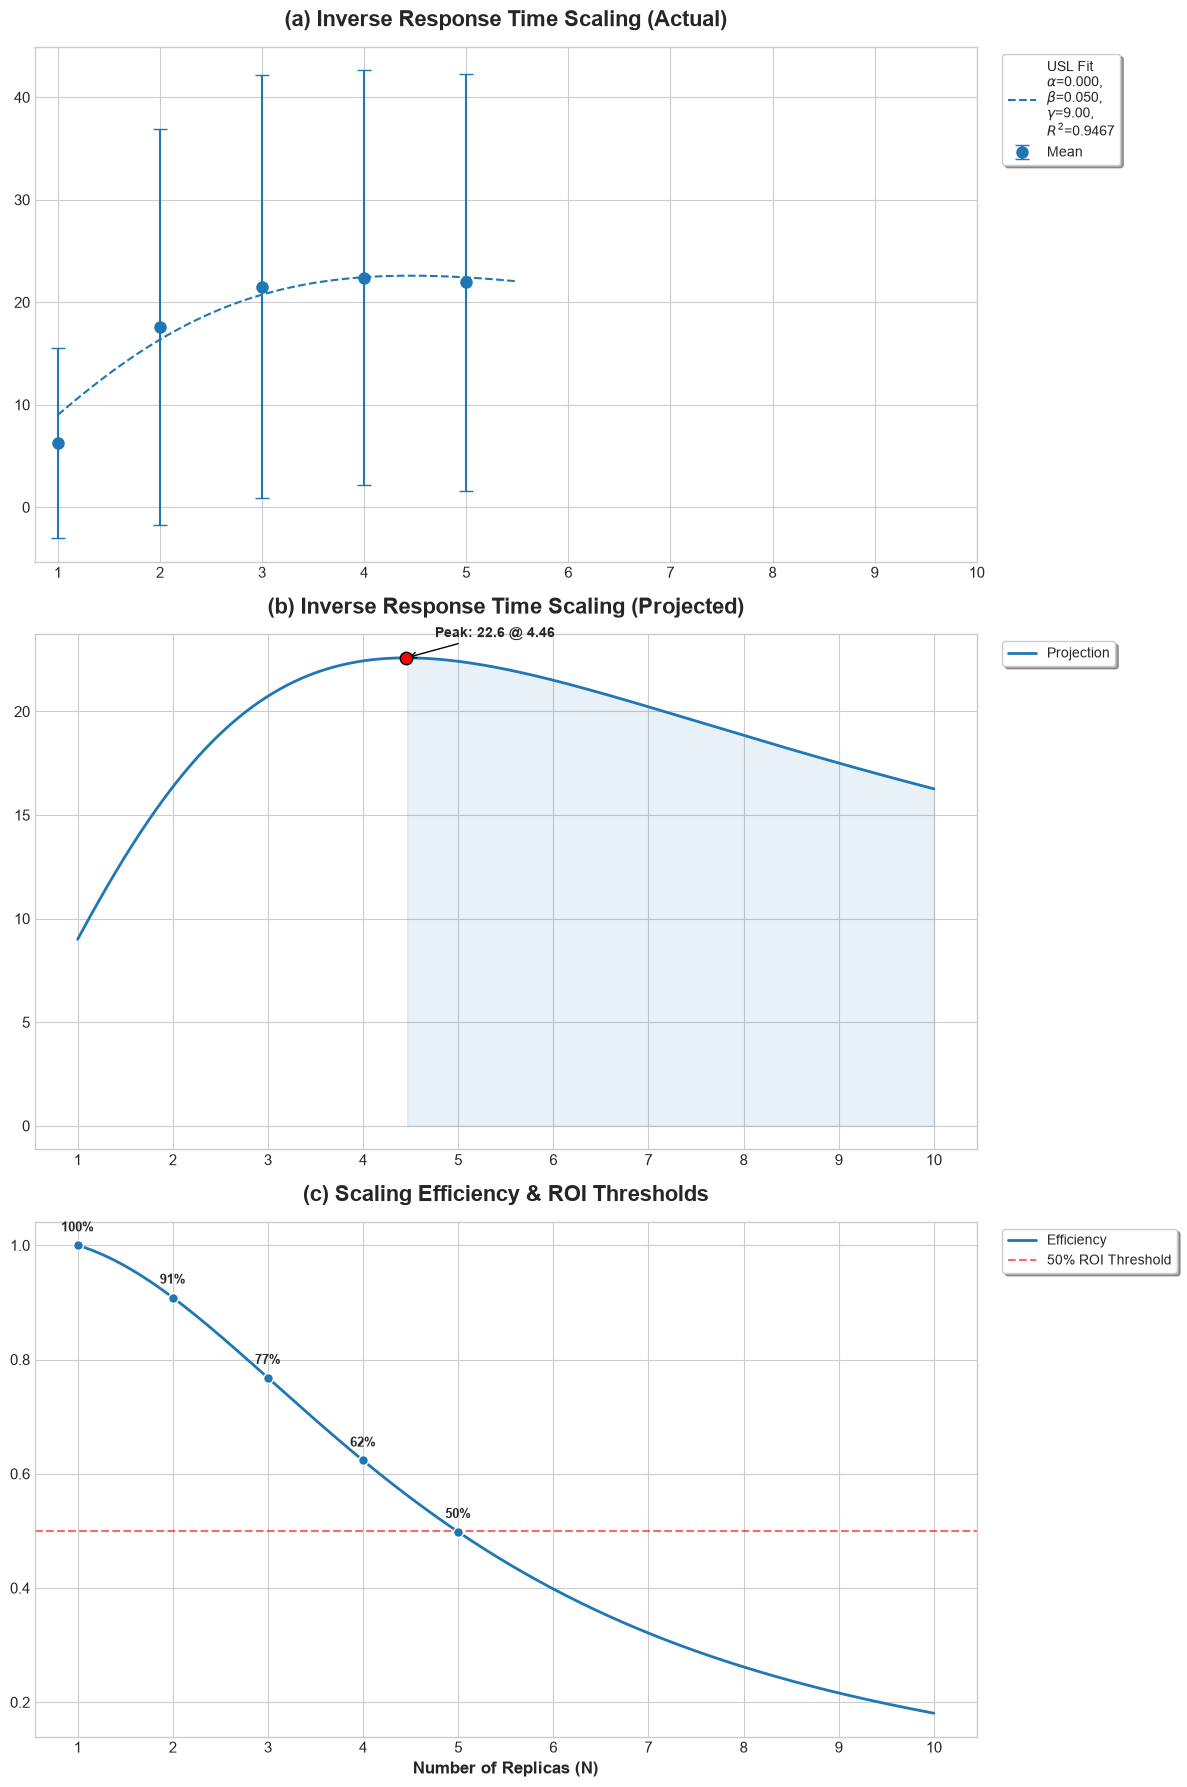

In [217]:
# --- 1. USL MODEL DEFINITIONS ---
def usl_model(N, alpha, beta, gamma):
    """The Universal Scalability Law formula."""
    return (gamma * N) / (1 + alpha * (N - 1) + beta * N * (N - 1))

def usl_efficiency(N, alpha, beta):
    """Calculates efficiency E(N)."""
    return 1 / (1 + alpha * (N - 1) + beta * N * (N - 1))

def fit_usl(df):
    """Dynamically solves for alpha, beta, and gamma based on dataframe input."""
    subset = df
    x = subset.index.values
    y = subset['mean'].values
    # Bounds ensure physical parameters stay positive/realistic
    popt, _ = curve_fit(usl_model, x, y, p0=[0.1, 0.01, y[0]], bounds=(0, [1, 1, np.inf]))
    return popt

def r_squared(y_actual, y_predicted):
    """Calculate the coefficient of determination R²."""
    ss_res = np.sum((y_actual - y_predicted) ** 2)
    ss_tot = np.sum((y_actual - np.mean(y_actual)) ** 2)
    return 1 - (ss_res / ss_tot)


# --- 2. PLOTTING SETUP ---
plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 18), dpi=100)
n_proj = np.linspace(1, 10, 500)
colors = {40: '#1f77b4', 80: '#ff7f0e'}
markers = {40: 'o', 80: 's'}

# --- 3. EXECUTION LOOP ---
# Perform Fit
alpha, beta, gamma = fit_usl(usl_df)
c, m = colors[40], markers[40]

# Calculate R²
subset = usl_df
x_data = subset.index.values
y_data = subset['mean'].values
y_pred = usl_model(x_data, alpha, beta, gamma)
r2 = r_squared(y_data, y_pred)

# Plot 1: Throughput + Fit
subset = usl_df
ax1.errorbar(subset.index, subset['mean'], yerr=subset['std'], fmt=m, color=c, 
                label=f'Mean', capsize=5, markersize=8)
n_fit = np.linspace(1, 5.5, 100)
ax1.plot(n_fit, usl_model(n_fit, alpha, beta, gamma), color=c, linestyle='--', 
            label=f'USL Fit\n$\\alpha$={alpha:.3f}, \n$\\beta$={beta:.3f}, \n$\\gamma$={gamma:.2f}, \n$R^2$={r2:.4f}')

# Plot 2: Projection & Maxima
y_proj = usl_model(n_proj, alpha, beta, gamma)
n_max = np.sqrt((1 - alpha) / beta) if beta > 0 else 10
x_max = usl_model(n_max, alpha, beta, gamma)

ax2.plot(n_proj, y_proj, color=c, linewidth=2, label=f'Projection')
ax2.scatter(n_max, x_max, color='red', s=80, edgecolors='black', zorder=5)
ax2.fill_between(n_proj, y_proj, where=(n_proj > n_max), color=c, alpha=0.1)
ax2.annotate(f'Peak: {x_max:.1f} @ {n_max:.2f}', xy=(n_max, x_max), xytext=(n_max+0.3, x_max+1),
                arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=10, fontweight='bold')

# Plot 3: Efficiency
eff = usl_efficiency(n_proj, alpha, beta)
ax3.plot(n_proj, eff, color=c, linewidth=2, label=f'Efficiency')
n_pts = np.array([1, 2, 3, 4, 5])
eff_pts = usl_efficiency(n_pts, alpha, beta)
ax3.scatter(n_pts, eff_pts, color=c, s=50, edgecolors='white', zorder=5)
for n, e in zip(n_pts, eff_pts):
    ax3.annotate(f'{e:.0%}', (n, e), textcoords="offset points", xytext=(0,10), ha='center', fontsize=9, fontweight='bold')

# Formatting
ax1.set_title('(a) Inverse Response Time Scaling (Actual)', fontsize=16, fontweight='bold', pad=15)
ax2.set_title('(b) Inverse Response Time Scaling (Projected)', fontsize=16, fontweight='bold', pad=15)
ax3.set_title('(c) Scaling Efficiency & ROI Thresholds', fontsize=16, fontweight='bold', pad=15)
ax3.set_xlabel('Number of Replicas (N)', fontsize=12, fontweight='bold')
ax3.axhline(0.5, color='red', linestyle='--', alpha=0.6, label='50% ROI Threshold')

for ax in [ax1, ax2, ax3]:
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, shadow=True)
    ax.set_xticks(range(1, 11))

plt.tight_layout()

plt.savefig("../figures/experiment-1-usl-analysis.png", dpi=300, bbox_inches="tight")
plt.show()

# Node analysis

The analysis below shows that HORIZONTAL-5 is the maximum number of replicas that can be supported before
overloading the nodes.

In [218]:
files = common.get_s3_file_listing(s3_bucket, s3_prefix=RUN)


## Get metrics from tsdb snapshots

In [219]:
client = docker.from_env()
port = 9099

queries = []

cluster_pod_requested_query = r"""
count by (node) (
  kube_pod_info
  * on (pod, namespace) group_left()
  (kube_pod_status_phase{phase=~"Running|Pending"} == 1)
)
/
sum by (node) (kube_node_status_allocatable{resource="pods"})
"""

queries.append({"name": "cluster_pod_requested", "query": cluster_pod_requested_query})


cluster_memory_requested_query = r"""
sum by (node) (
  kube_pod_container_resource_requests{resource="memory"}
  * on (pod, namespace) group_left(node)
  (
    kube_pod_info
    * on (pod, namespace) group_left()
    (kube_pod_status_phase{phase=~"Running|Pending"} == 1)
  )
)
/
sum by (node) (
  kube_node_status_allocatable{resource="memory"}
)
"""

queries.append({"name": "cluster_memory_requested", "query": cluster_memory_requested_query})



cluster_cpu_requested_query = r"""
sum by (node) (
  kube_pod_container_resource_requests{resource="cpu"}
  * on (pod, namespace) group_left(node)
  (
    kube_pod_info
    * on (pod, namespace) group_left()
    (kube_pod_status_phase{phase=~"Running|Pending"} == 1)
  )
)
/
sum by (node) (
  kube_node_status_allocatable{resource="cpu"}
)
"""

queries.append({"name": "cluster_cpu_requested", "query": cluster_cpu_requested_query})


cpu_cores_by_node_query = r"""sum by (node) (
  kube_pod_container_resource_requests{resource="cpu"}
  * on (namespace, pod) group_left(node)
  kube_pod_info
)"""

queries.append({"name": "cpu_cores_by_node", "query": cpu_cores_by_node_query})


node_cpu_usage_query = r"""
  avg(1 - rate(node_cpu_seconds_total{mode="idle"}[2m])) by (node)"""

queries.append({"name": "node_cpu_usage", "query": node_cpu_usage_query})


total_cpu_usage_ratio = r"""1 - (
  sum by (node) (
    rate(node_cpu_seconds_total{mode="idle"}[2m])
  )
  /
  sum by (node) (
    rate(node_cpu_seconds_total[2m])
  )
)
"""

queries.append({"name": "node_cpu_usage", "query": node_cpu_usage_query})


allocatable_cpu_usage_ratio_query = r"""
sum by (node) (
  label_replace(
    rate(container_cpu_usage_seconds_total{container!="", container!="POD"}[2m]),
    "node",
    "$1",
    "instance",
    "(.*)"
  )
)
/
sum by (node) (
  kube_node_status_allocatable{resource="cpu"}
)
"""

queries.append({"name": "allocatable_cpu_usage_ratio", "query": allocatable_cpu_usage_ratio_query})

cluster_cpu_usage_query = r"""
sum by (node) (
  label_replace(
    rate(
      container_cpu_usage_seconds_total{
        container!="",
        container!="POD"
      }[2m]
    ),
    "node",
    "$1",
    "instance",
    "(.*)"
  )
)
/
sum by (node) (
  kube_node_status_allocatable{resource="cpu"}
)
"""

queries.append({"name": "cluster_cpu_usage", "query": cluster_cpu_usage_query})



results = {}
for query in queries:
  df = common.get_metric_from_tsdb(
    s3_bucket,
    files,
    query["query"],
    client=client,
    port=port)
  results[query["name"]] = df

print(results.keys())



    

dict_keys(['cluster_pod_requested', 'cluster_memory_requested', 'cluster_cpu_requested', 'cpu_cores_by_node', 'node_cpu_usage', 'allocatable_cpu_usage_ratio', 'cluster_cpu_usage'])


## Headroom analysis

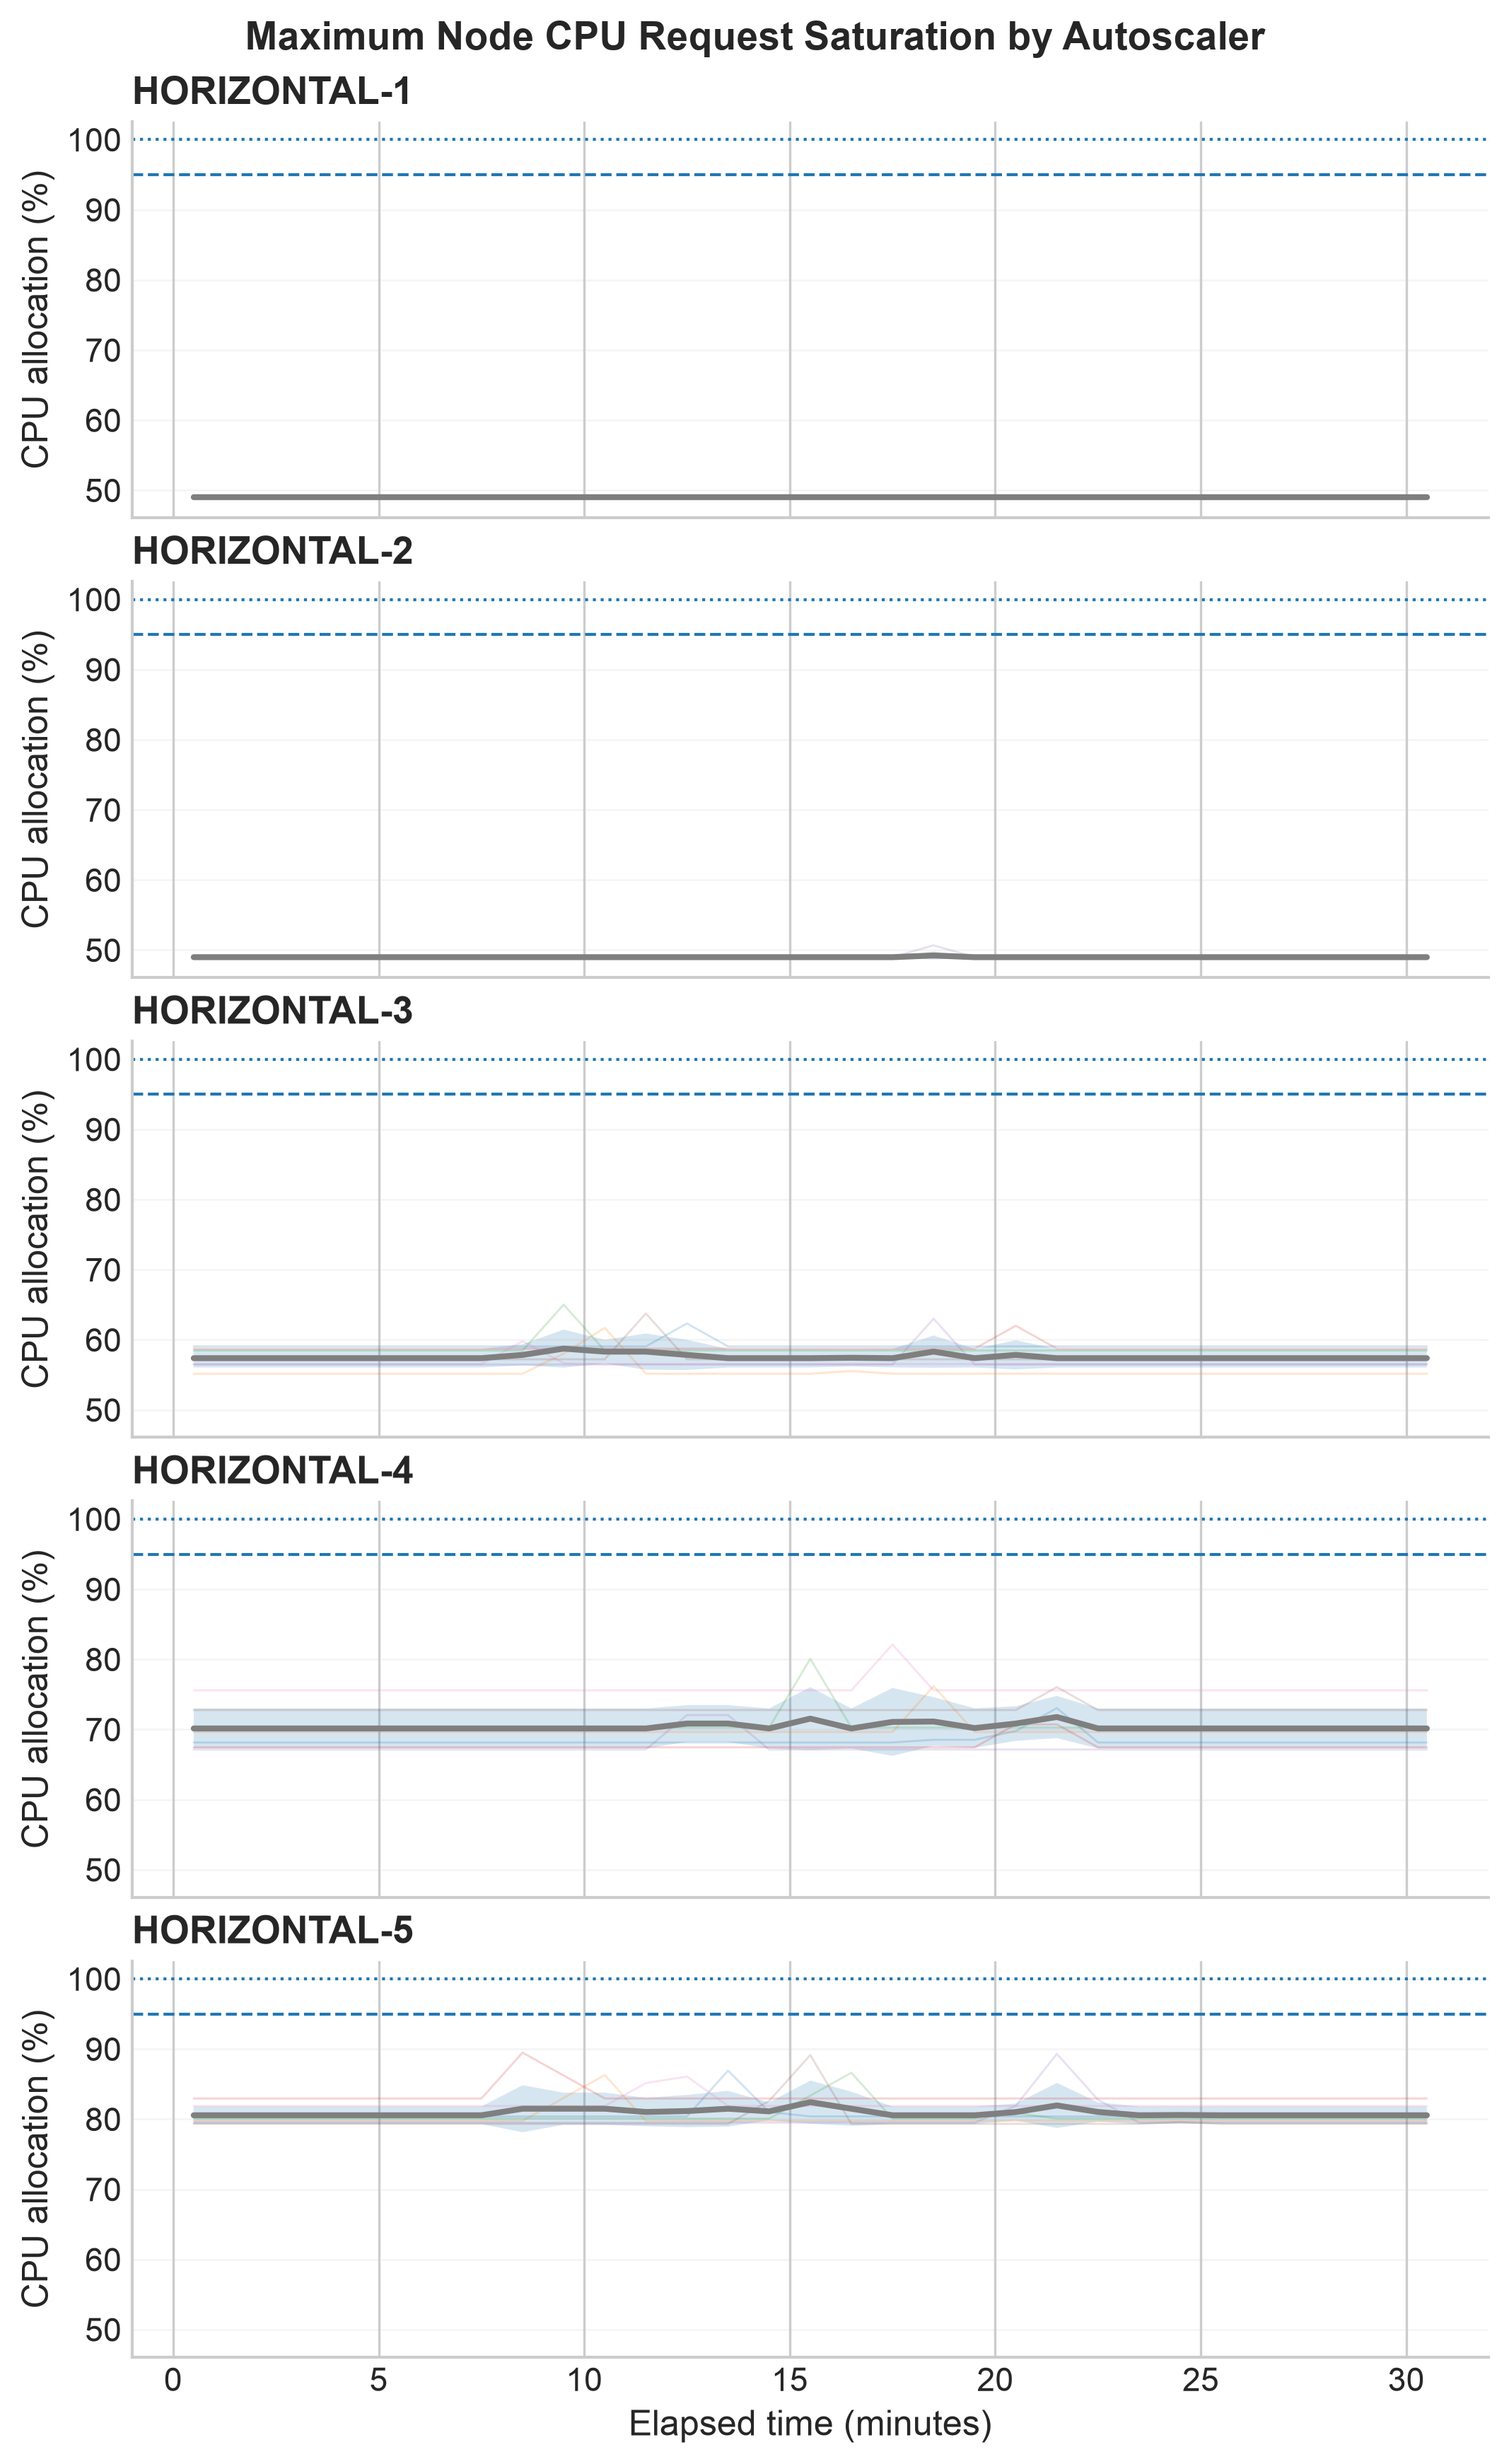

In [220]:
fig, axes, cpu_trial_binned, cpu_summary = common.plot_cpu_allocation(
    results["cluster_cpu_requested"],
    bin_seconds=60,
)

plt.show()

## Time at CPU Over-saturation

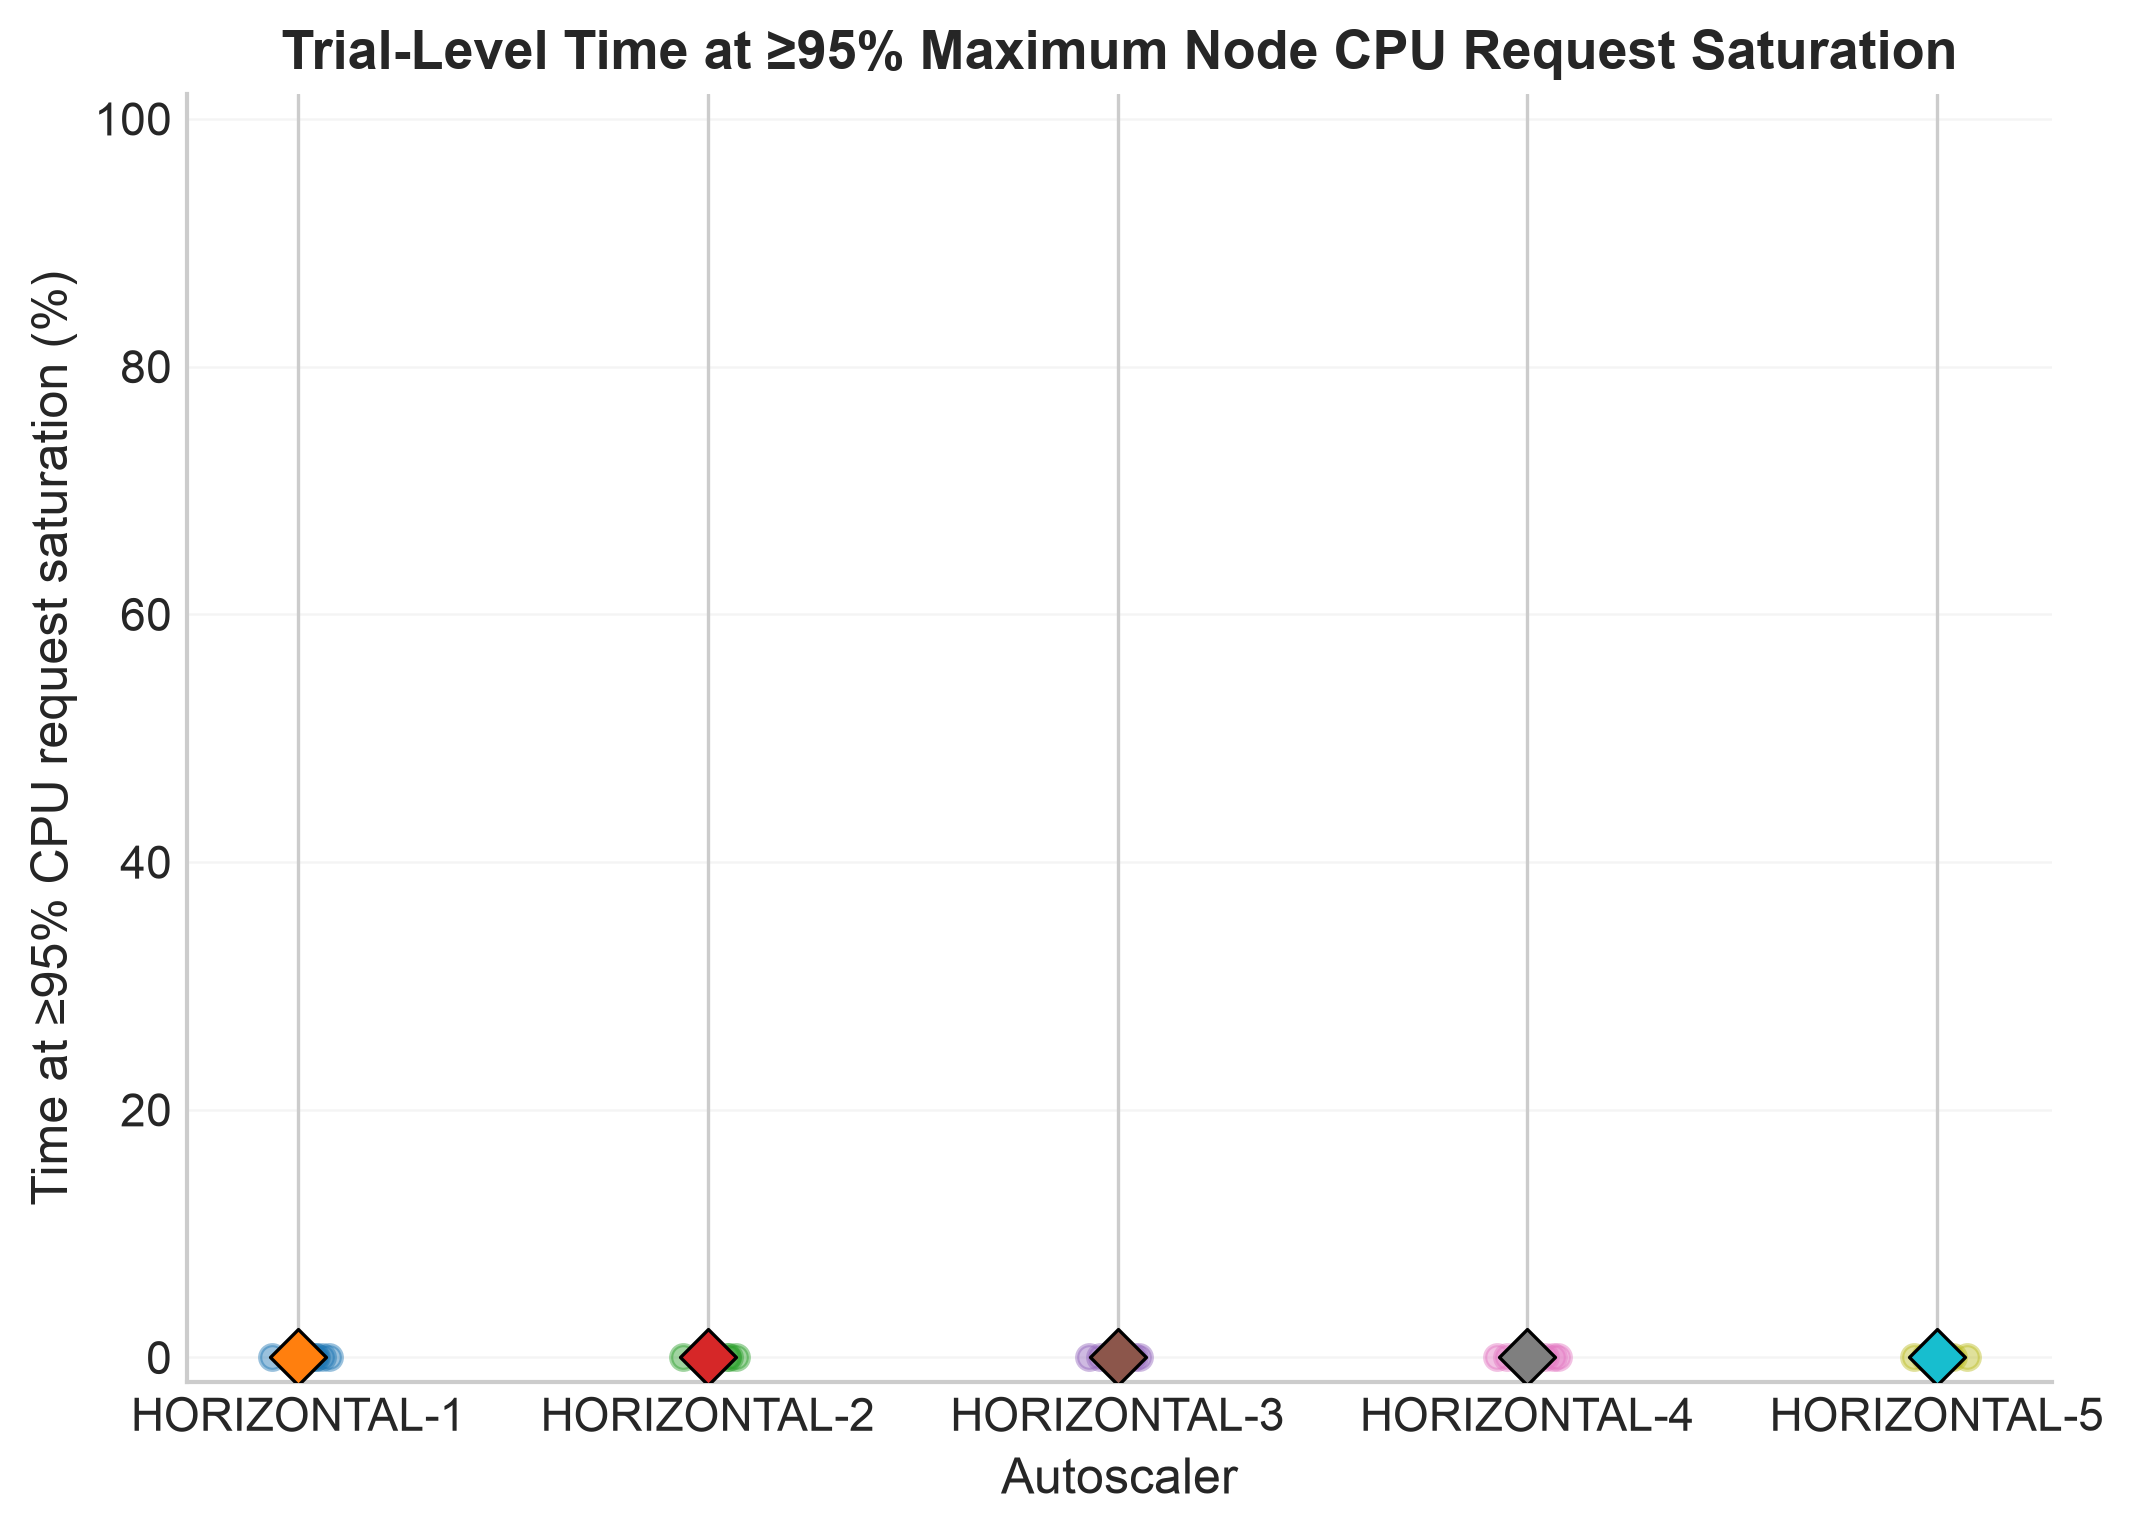

In [221]:
fig, ax, cpu_saturation_trials, cpu_saturation_summary = (
    common.plot_cpu_saturation_time_share(
        results["cluster_cpu_requested"],
        threshold=0.95,
    )
)

plt.show()

In [222]:
cpu_saturation_trials[
    [
        "autoscaler",
        "trial_id",
        "cpu_saturation_time_share_pct",
        "mean_max_cpu_request_ratio",
        "max_cpu_request_ratio",
    ]
].sort_values(
    ["autoscaler", "trial_id"]
)

,autoscaler,trial_id,cpu_saturation_time_share_pct,mean_max_cpu_request_ratio,max_cpu_request_ratio
8,horizontal-1,trial0009,0.0,0.490000,0.490000
9,horizontal-1,trial0010,0.0,0.490000,0.490000
11,horizontal-1,trial0012,0.0,0.490000,0.490000
14,horizontal-1,trial0015,0.0,0.490000,0.490000
21,horizontal-1,trial0022,0.0,0.490000,0.490000
26,horizontal-1,trial0027,0.0,0.490000,0.490000
33,horizontal-1,trial0034,0.0,0.490000,0.490000
10,horizontal-2,trial0011,0.0,0.490000,0.490000
20,horizontal-2,trial0021,0.0,0.490251,0.505188
25,horizontal-2,trial0026,0.0,0.490000,0.490000


In [223]:
cpu_saturation_summary[
    [
        "autoscaler",
        "mean",
        "ci_low",
        "ci_high",
        "count",
    ]
]

,autoscaler,mean,ci_low,ci_high,count
0,horizontal-1,0.0,0.0,0.0,7
1,horizontal-2,0.0,0.0,0.0,7
2,horizontal-3,0.0,0.0,0.0,7
3,horizontal-4,0.0,0.0,0.0,7
4,horizontal-5,0.0,0.0,0.0,7
